# CIS342 課程專案 — 車牌辨識（License Plate Recognition, LPR）

**組別**：`6`

**組員**：
- `Ho Nok Hei` — `S26202765`（A 線）
- `Li Chi Shing` — `S26206590`（B 線）

**提交內容**：Jupyter notebook、PDF 報告、4 個成功案例、2 個失敗案例

**截止時間**：2026 年 12 月 18 日 12:00 中午（Moodle）

**簡報時間**：第 11 週起（暫定）

**評分比重**：程式執行 40% · 報告 30% · 現場簡報 30%



## 目錄

本 notebook 依課程要求的四個階段組織：**影像取得與資料準備 → 車牌偵測 → 字元辨識 → 後處理與驗證**，最後加上整合與評估。

**前置文件**

| 章節 | 內容 |
|---|---|
| AI 使用聲明（Ho Nok Hei） | 本人使用 AI 的方式與範圍 |
| AI 使用聲明（Li Chi Shing） | 另一位組員使用 AI 的方式與範圍 |
| 分工 | 兩人負責的章節與模組、整合窗口、時程 |
| 使用規則 | 協作方式與 cell 撰寫規範 |
| 進度 | 各階段完成狀態 |

**主體章節**

| 章節 | 內容 | 模組代號 | 對應流程階段 | 負責人 |
|---|---|---|---|---|
| §0 | 環境設置與共用資料契約 | `S0-1`～`S0-4` | 全階段共用 | Ho Nok Hei |
| §1 | 資料集取得、標註表與半自動標註 | `D1-01`～`D1-05` | 影像取得 | Ho Nok Hei |
| §2 | 前處理：光照補償與去噪 | `PRE-01` | 車牌偵測（前置） | Ho Nok Hei |
| §3 | 車牌定位：候選產生與篩選 | `LOC-01`、`LOC-02` | 車牌偵測 | Ho Nok Hei |
| §4 | 車牌擷取：由四邊形取出區域 | `SEG-01` | 車牌偵測 | Ho Nok Hei |
| §5 | 幾何校正：透視變換到固定尺寸 | `GEO-01` | 車牌偵測 | Ho Nok Hei |
| §6 | 字元辨識：二值化、切分與辨識 | `OCR-01`、`OCR-02` | 字元辨識 | Li Chi Shing |
| §7 | 後處理：字串規則修正與驗證 | `POST-01` | 後處理與驗證 | Li Chi Shing |
| §8 | 整合：全流程串接 | `INT-01` | 全流程 | Li Chi Shing |
| §9 | 評估：正確率與失敗案例分析 | `EV-01` | 全流程 | Li Chi Shing |


## AI 使用聲明（Ho Nok Hei）

> 本節由 Ho Nok Hei 自行維護，另一位組員請勿修改。
>
> ✏️ **【提交前填寫】** 補齊「使用的 AI 工具」的版本與日期範圍；並逐列確認表格內容是否與事實相符。

**組員**：`Ho Nok Hei`（`S26202765`）

**使用的 AI 工具**：GitHub Copilot（VS Code，Copilot SDK）

下表依時間順序記錄本人在本專案使用 AI 的方式。每一列都寫明「我下了什麼指令」、「AI 做了什麼」、「我如何驗證」、「最後由我決定什麼」。

| 工作部分 | 我給 AI 的輸入 | AI 的輸入與輸出 | 我驗證了什麼 | 我的最終決定／產出 |
|---|---|---|---|---|
| **筆記簿初始化與運行骨架定義**<br>§0 Setup、§1–§9 骨架 | 說明本專案為 2 人小組、以 `.ipynb` 在 Google Colab 協作（各自本機開發、以 cell 為單位貼上雲端）；要求先用 Python 3.12 建立 virtualenv；要求把實作內容劃分給兩人；並要求每次只增加一部分，避免一次產出無法理解的程式碼 | 讀取工作區既有檔案與課程 PDF（因無法直接讀 PDF，先轉為 Markdown）；產出 `TASK_DIVISION.md` 分工表；建立 `.venv`；產生 §0 Setup（import、共用常數、`Candidate` 資料契約、四點排序、影像讀取／除錯存圖／視覺化工具）以及 §1–§9 各階段函式 stub 與 `self test` cell | ✏️ **【提交前驗證】** 本人尚未親自執行。目前僅由 AI 以 `nbconvert --execute` 執行並回報「0 error cell」；需本人於 VS Code 重跑整份 notebook 確認 | 採用此骨架。`PLATE_W × PLATE_H` 暫定 `480 × 140`，待實際量測後調整；各階段先以簡化實作讓 pipeline 能端到端跑通 |
| **標題頁與文件書寫規範** | 要求移除「開發用 Notebook（本機）」這類內部說明；抬頭改為專案名稱、組別、組員姓名學號；標題一律放在 markdown cell 第一行；後續要求全文改用繁體中文 | 重寫標題頁與章節導覽表；把說明文字與程式註解改為繁體中文；修正簡體殘留與錯字 | 本人逐字閱讀並指出不當文字（如「開發用 Notebook」段落、表格化的抬頭），AI 依指示逐次修正 | 採用中文版；「A 線／B 線」代號僅保留於內部分工說明，對外（章節導覽、AI 聲明）改用組員姓名 |
| **AI 使用聲明表格格式** | 提供一份 AI 使用聲明的格式範例，要求 AI 依該範例的表格格式製作本專案的 AI 使用聲明；並指定欄位語意為「我給 AI 的輸入／AI 的輸入與輸出／我驗證了什麼／我的最終決定」 | 範例為 PDF，因無法直接讀取，改用 `pypdf` 提取表格文字；依範例的 5 欄結構製作聲明表格；後續依指示改為以組員姓名劃分而非 A/B 線 | 本人提供範例並確認欄位對應正確；表格內容是否與事實相符仍須本人逐列確認 | 採用範例的 5 欄格式，並以組員姓名作為節標題 |
| **章節編排與閱讀順序檢視** | 要求檢查「還有沒有其他排放順序不符合閱讀順序的地方」，並指出兩點：分工被排在 AI 聲明之後，評閱者不知 A／B 為何；把「分工」整節標為提交前刪除並不合理 | 列出 14 項排序與一致性問題（P1–P14）及建議順序；實際修正 §8 評估與 §9 整合的順序、補上章節導覽、補上「整合窗口」定義、分工表改用姓名 | 本人逐項判斷並採納大部分建議；部分項目（如 `DOC`/`CASE`/`PPT` 是否在 notebook 建章節）由本人決定 | 套用建議順序；§8 整合在前、§9 評估在後；標題頁加入章節導覽 |
| **開發用內容標記制度** | 要求「開發用標示內容」都要額外標示，指明是開發時用、未來需刪除或更改；並指出標記語意不應是「整節刪除」 | 設計三種標記：🛠️ 開發用｜提交前刪除、✏️ 提交前填寫、✏️ 提交前確認；套用至分工（段落級）、使用規則、進度、A／B 線開發順序表，以及 9 個 code cell 的 `TODO`／佔位註解 | 本人指出分工不應整節刪除，AI 已改為段落級標記並修正標記語意 | 採用三種標記；「分工」整節與 A／B 線章節標題列為必須保留 |
| **資料集來源評估與資料契約調整** | 提供兩個 Roboflow 資料集網址（33 張的 `hk-license-plate-recognition`、1,491 張的 `hk-fszrn`），詢問是否可用、能否辨識同圖多車牌、以及該用哪一個；並指定「先做單一車牌、但 labels.csv 預留欄位」 | 讀取頁面後回報：兩者授權皆 CC BY 4.0、皆為 Object Detection、**都沒有車牌字串**（仍需人工填）；33 張那集為 WhatsApp 壓縮轉傳、僅兩天拍攝；1,491 張那集為相機原圖。提出「B 為主（40–50）＋ A 作 external（10–15）」策略，並實作 `[D1-02]` COCO 匯入與 `[D1-03]` 半自動標註工具 | ✏️ **【提交前驗證】** 尚未驗證。圖片品質、實際可用張數與字串正確性仍須本人下載後逐張確認 | 採用 B 為主 ＋ A 為 external；`labels.csv` 新增 `plate_idx`、`split` 兩欄；本版 `run_pipeline()` 維持單一車牌輸出 |

**我未使用 AI 的部分**（以下為應由本人完成、目前尚未完成的事項）：

- **影像蒐集與實地拍攝**：包含前牌（白底）、後牌（黃底）、不同拍攝角度與光照條件的影像。
- **`labels.csv` 人工標註**：車牌字串、`front_rear`、`difficulty` 的判定與填寫。
- **實際執行與驗證**：於 VS Code 親自重跑整份 notebook，確認所有 cell 的輸出與上表「提交前驗證」欄的記載一致。
- **各階段演算法選型與調參**：前處理、車牌定位、擷取、幾何校正的方法選擇、參數調整與除錯（AI 已產出可端到端運行的初版，本人尚需逐段檢視、調參與驗證）。
- **資料集最終取捨**：判斷是否採用 Roboflow 資料集、是否合併其他來源、以及要剔除哪些不可用影像。
- **報告撰寫與案例挑選**：方法論章節、4 個成功案例與 2 個失敗案例的選定與分析。

**責任聲明**：本人對本專案中所有提交的程式碼與結論負責。上表所述 AI 產出內容，在提交前均需由本人執行、理解與驗證；若發現錯誤由本人修正。

## AI 使用聲明（Li Chi Shing）

> 本節由 Li Chi Shing 自行填寫，另一位組員請勿代填。
>
> ✏️ **【提交前填寫】** 本節目前為空白模板。請依實際使用情況逐列填寫，不需要的列可刪除，
> 若有其他工作項目請自行新增列。填完後請把本段提示移除。

**組員**：`Li Chi Shing`（`S26206590`）

**使用的 AI 工具**：`<工具名稱與版本；若未使用 AI 請改寫為「無」>`

下表說明本人使用 AI 的方式。每一列填寫「我下了什麼指令」、「AI 做了什麼」、「我如何驗證」、「最後由我決定什麼」。

| 工作部分 | 我給 AI 的輸入 | AI 的輸入與輸出 | 我驗證了什麼 | 我的最終決定／產出 |
|---|---|---|---|---|
| `<工作部分 1>` | `<我向 AI 說明了什麼、要求它做什麼>` | `<AI 讀了什麼、產出了什麼>` | `<我實際檢查或執行了什麼>` | `<最後由我決定或採用的是什麼>` |
| `<工作部分 2>` | `<…>` | `<…>` | `<…>` | `<…>` |
| `<工作部分 3>` | `<…>` | `<…>` | `<…>` | `<…>` |

**我未使用 AI 的部分**：

- `<應由本人完成、且未使用 AI 的項目>`

**責任聲明**：本人對本專案中所有提交的程式碼與結論負責。AI 產出的內容均經本人理解、執行與驗證後才納入，若發現錯誤由本人修正。

## 分工

本專案由兩位組員共同完成，採「垂直切線」分工：以 pipeline 的四個必要階段為分界，
A 線負責「輸入影像 → 校正好的車牌圖」，B 線負責「校正車牌圖 → 字串」，
再各自延伸負責評估、整合與報告。

| 負責人 | 負責章節 | 對應 pipeline 階段 |
|---|---|---|
| **A 線**<br>`Ho Nok Hei`（`S26202765`） | §0 Setup、§1 資料集、§2 前處理、§3 車牌定位、§4 車牌擷取、§5 幾何校正 | 前處理、Localization、Segmentation、Geometric Transformation |
| **B 線**<br>`Li Chi Shing`（`S26206590`） | §6 字元辨識、§7 後處理、§8 整合、§9 評估 | OCR、後處理、全流程整合與評估 |

**其他交付項目**：`DOC`（PDF 報告）、`CASE`（4 個成功案例 + 2 個失敗案例）、`PPT`（現場簡報）由 B 線主導，
A 線提供各階段中間圖與失敗分析素材。這些內容屬獨立交付檔案，不在本 notebook 內。

> 🛠️ **【開發用｜提交前刪除】**
>
> 整合窗口：`Li Chi Shing`（B 線）。負責合併兩人 cell 進共用 Colab notebook、維護 §0 中標記 `[S0-2]` 的共用常數 cell，並負責最終提交。
> 其他人不直接改 `[S0-2]`，需要修改時先在群組提出。

> ✏️ **【提交前確認】** 確認上表姓名、學號與負責章節的對應正確。

## 使用規則

> 🛠️ **【開發用｜提交前刪除】** 本節只給組員看。刪除本節前請先確認沒有殘留任何標記。

1. 每個 cell 開頭都有 `# ==== [編號] 說明 ====` 標記，貼到 Colab 時**必須保留**。
2. **不要** `import` 本專案自己的 .py 檔（Colab 貼上會找不到）。所有函式都寫在 cell 內。
3. **不要修改別人的 cell**；§0 中標記 `[S0-2]` 的共用常數 cell 只有整合窗口能改。
4. 函式簽名必須符合 §0 中 `[S0-3]` 定義的資料契約，不得自行更改參數或回傳格式。
5. 標題（`#` / `##` / `###`）一律放在 markdown cell 第一行；需要新標題就另開 cell。
6. 缺少的套件在 Colab 用 `%pip install` 自行補，不要事先寫死在 notebook 裡。

**標記說明**：

- 🛠️ **【開發用｜提交前刪除】** — 只給組員看的內部流程說明。可能是一整節（如「使用規則」「進度」），
  也可能只是某節裡的其中一段（如「分工」裡的整合窗口說明）。**只刪標記所標示的那個段落，不要刪掉整節。**
- ✏️ **【提交前填寫／確認】** — 佔位或待確認內容，提交前必須補齊；填完後把標記本身移除。
- `# --- self test` 開頭的 cell — 開發期驗證用，提交前可保留作為示範，或整段刪除。

未加任何標記的內容即為正式內容，會原樣呈現給評閱者。

**必須保留、不可刪除**：`## 目錄`、兩節「AI 使用聲明」、`## 分工` 整節，以及「A 線：負責章節與開發順序」「B 線：負責章節與開發順序」
兩節的**標題與負責人資訊**。這些是評閱者判斷誰負責哪一部分的依據；
標題下方標記 🛠️ 的開發進度表才需要刪除。

## 進度

> 🛠️ **【開發用｜提交前刪除】** 本節只給組員看，用來追蹤各章節完成度。

**A 線（定位）**

- [x] **§0** Setup
- [ ] **§1** 資料集 / `labels.csv` / 半自動標註
- [ ] **§2** 前處理（PRE-01）
- [ ] **§3** 車牌定位（LOC-01 / LOC-02）
- [ ] **§4** 車牌擷取（SEG-01）
- [ ] **§5** 幾何校正（GEO-01）

**B 線（辨識／整合）**

- [ ] **§6** 字元辨識（OCR-01 / OCR-02）
- [ ] **§7** 後處理（POST-01）
- [ ] **§8** 整合（INT）
- [ ] **§9** 評估（EV）
- [ ] **DOC / CASE / PPT** 報告、案例、簡報

## §0 Setup

環境旗標、共用常數、資料契約與工具函式。
**本節必須先完整執行**，後續所有章節都依賴這裡的定義與路徑。

In [1]:
# ==== [S0-1] 共用 import 與環境旗標 ====
import os
import sys
import json
import re
import time
import shutil
import random
import zipfile
import tempfile
import glob
import hashlib
import unicodedata
import urllib.request
from dataclasses import dataclass, field
from typing import List, Tuple, Optional, Dict, Any

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

IN_COLAB = 'google.colab' in sys.modules

print('IN_COLAB', IN_COLAB)
print('Python', sys.version.split()[0])
print('OpenCV', cv2.__version__)
print('NumPy ', np.__version__)


IN_COLAB True
Python 3.13.18
OpenCV 5.0.0
NumPy  2.4.6


In [2]:
# ==== [S0-2] 共用常數與資料契約（全組共用，修改前請先討論） ====
# --- 目錄 ---
# 本機：往上找含 notebooks/ 的那一層當專案根目錄
# Colab：固定用 COLAB_ROOT，若資料放在 Google Drive 請改成掛載路徑
COLAB_ROOT = '/content'
def _find_root() -> str:
    """找出專案根目錄：Colab 用 /content，本機往上找含 notebooks/ 的那一層。"""
    if IN_COLAB:
        return COLAB_ROOT
    d = os.path.abspath('.')
    for _ in range(4):
        if os.path.isdir(os.path.join(d, 'notebooks')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            break
        d = parent
    return os.path.abspath('.')

PROJECT_ROOT = _find_root()
DATA_DIR     = os.path.join(PROJECT_ROOT, 'data', 'images')
RAW_DIR      = os.path.join(PROJECT_ROOT, 'data', 'raw')
LABELS_CSV   = os.path.join(PROJECT_ROOT, 'data', 'labels.csv')
DEBUG_DIR    = os.path.join(PROJECT_ROOT, 'debug')
SHARED_DIR   = os.path.join(PROJECT_ROOT, 'shared', 'rectified')
# §8 整合的 A→B 交接目錄：A 段寫入中間狀態，B 段用 glob 讀取（見 [INT-01] / [INT-02]）
STAGE_DIR    = os.path.join(PROJECT_ROOT, 'shared', 'stages')

# --- 幾何契約：所有階段看到的車牌尺寸都必須是這個 ---
PLATE_W, PLATE_H = 480, 140

# --- 定位參數 ---
TOP_K    = 5      # 最多保留幾個候選
MAX_SIDE = 1280   # 讀圖時限制最長邊，避免大圖拖慢

# 車牌底色遮罩（白底 / 黃底）。實測 99 張調參所得，見 [LOC-01] 說明。
LOC_V_WHITE       = 220    # 白底亮度門檻；低於此會把停車場地面一起框進來
LOC_S_WHITE       = 70     # 白底飽和度上限（白＝低飽和）
LOC_HUE_YELLOW    = (15, 40)
LOC_S_YELLOW      = 85
LOC_V_YELLOW_RATIO = 0.80  # 黃底亮度門檻 = LOC_V_WHITE * 此值
# 白底亮度「門檻階梯」：同一張圖用多個亮度門檻各產生一次候選再合併。
# 為什麼不是挑一個最好的門檻就好：實測單一 v>220 的 recall@k 是 44%，
# 但把 v>170 / v>220 兩組候選取聯集後上限可到 67.7% —— 也就是有相當比例的
# 車牌在某個門檻下完全消失（曝光不足），換個門檻才浮出來，兩者在同一張圖裡互補。
# 為什麼只有兩階不是越多越好：候選越多，[LOC-02] 的同張圖內 min-max 正規化
# 被稀釋得越嚴重，實測三階（150/180/220）反而比兩階差。
LOC_V_LADDER      = (170, 220)   # 由低到高；第一階抓曝光不足，第二階抓乾淨的
LOC_CLOSE_K       = (21, 5)   # 水平閉運算核：把字元間隙串成一整塊
LOC_MIN_AREA      = 200
LOC_MIN_SIDE      = 10
LOC_ASPECT_RANGE  = (1.1, 10.0)
LOC_MIN_RECT_FILL = 0.30   # 輪廓面積 / 最小外接矩形面積

# 評分權重（[LOC-02]）。
# 資料集 GT 的軸對齊 w/h 中位數約 1.6 —— 車牌普遍斜拍，所以不能套用
# 規格書上「真實車牌約 3.5」的理想值，否則正解反而被扣分。
LOC_AR_BASE       = 2.0
LOC_AR_SIGMA_LOG  = 0.55
LOC_SCORE_W       = {'aspect': 0.24, 'area': 0.13, 'fill': 0.11,
                     'edge': 0.12, 'contrast': 0.10, 'char': 0.30}
LOC_NMS_IOU       = 0.60
# 面積偏好：不喜歡「越大越好」，而是偏好「佔畫面約 3%」這種車牌常見比例。
LOC_AREA_FRAC     = 0.03
LOC_AREA_SIGMA_LOG = 1.00
LOC_BORDER_PENALTY = 0.55   # 貼邊候選的乘性懲罰（見 [LOC-02]）
# A 段接受門檻：top-1 分數低於此就視為定位失敗，不寫檔。
# 寧可少寫，也不要讓 B 線拿到「左上角天花板」這種垃圾輸入。
LOC_ACCEPT_SCORE  = 0.60

# 「字元列」特徵（見 [LOC-03]）：把候選攤平後數幾個像字元的連通域。
# 這是「車牌」與「亮塊」（天花板、反光、車廠標誌）最本質的差別 ——
# 前面五個特徵都只看候選本身的形狀與亮度，只有這一個看「裡面有沒有字」。
LOC_CHAR_W, LOC_CHAR_H = 240, 80   # 攤平後的分析尺寸
LOC_CHAR_MAX           = 8         # 數到幾個字元就算滿分（香港車牌最多 8 個）
LOC_CHAR_H_RANGE       = (0.30, 0.95)  # 字元高度 / 攤平高度
LOC_CHAR_AR_RANGE      = (0.12, 1.30)  # 字元寬高比
LOC_CHAR_MIN_AREA_FRAC = 0.008     # 字元面積 / 攤平面積 下限
W_CHAR = 0.30    # 字元特徵在總分中的權重；其餘五項按比例縮到 0.70
# 門檻階梯 + 字元特徵（99 張實測）：
#   單一 220   recall@1 48.5%  recall@k 57.6%  端到端 38.4%
#   220+170    recall@1 51.5%  recall@k 60.6%  端到端 40.4%（+TB6248 +RE4430 −MJ5541）

# --- 測試影像（自行指定要驗證的檔名）---
TEST_IMG = os.path.join(DATA_DIR, 'test_01.jpg')

# --- 標註難度標記 ---
# normal：可直接判讀（評分主力）
# hard  ：模糊／部分被遮／標註框不是車牌，但仍有可靠答案，保留在評估內
# unreadable：人眼亦不可判讀，text 刻意留空，評估時排除
# not_plate ：標註框不是車牌（保留給未來，目前無此值）
LABEL_DIFFICULTIES     = ('normal', 'hard', 'unreadable')
UNSCORABLE_DIFFICULTIES = ('unreadable', 'not_plate')   # 這些列沒有可靠標準答案

# --- 可重現性 ---
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

for _d in (DATA_DIR, RAW_DIR, os.path.dirname(LABELS_CSV), DEBUG_DIR, SHARED_DIR, STAGE_DIR):
    os.makedirs(_d, exist_ok=True)

print('PLATE =', PLATE_W, 'x', PLATE_H)
print('DATA_DIR =', DATA_DIR)
print('RAW_DIR  =', RAW_DIR)


PLATE = 480 x 140
DATA_DIR = /content/data/images
RAW_DIR  = /content/data/raw


### 資料契約結構

`Candidate` 是定位（LOC）與後續階段之間唯一的溝通格式。
`quad` 必須是 `(4,2) float32`、順時針、由左上開始 —— 用 `sort_quad()` 保證。


In [3]:
# ==== [S0-3] 資料契約：候選車牌結構 ====
@dataclass
class Candidate:
    """一個可能含車牌的四邊形候選。

    quad  : np.float32 (4,2)，順時針，由左上角開始
    score : 越大越可能是車牌
    source: 產生此候選的策略名稱（用於 ablation 與除錯）
    meta  : 其他除錯資訊（面積、矩形度、邊緣密度…）
    """
    quad: np.ndarray
    score: float = 0.0
    source: str = ''
    meta: Dict[str, Any] = field(default_factory=dict)

    @property
    def bbox(self) -> Tuple[int, int, int, int]:
        x, y, w, h = cv2.boundingRect(self.quad.astype(np.int32))
        return int(x), int(y), int(w), int(h)

    @property
    def aspect(self) -> float:
        _, _, w, h = self.bbox
        return w / max(h, 1)

    def crop(self, img: np.ndarray) -> np.ndarray:
        x, y, w, h = self.bbox
        return img[y:y + h, x:x + w].copy()


def sort_quad(pts: np.ndarray) -> np.ndarray:
    """四點排序為 左上 → 右上 → 右下 → 左下（順時針）。"""
    pts = np.asarray(pts, dtype=np.float32).reshape(4, 2)
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).ravel()
    tl = pts[np.argmin(s)]
    br = pts[np.argmax(s)]
    tr = pts[np.argmin(d)]
    bl = pts[np.argmax(d)]
    return np.array([tl, tr, br, bl], dtype=np.float32)


In [4]:
# ==== [S0-4] 影像讀取、除錯輸出與視覺化工具 ====
def use_cjk_font() -> bool:
    """讓 matplotlib 能顯示中文標題。

    Colab 預設沒有中文字型，找不到時圖上標題會變成方框；
    此時改用英數標題，或在 Colab 先執行 `!apt-get -y install fonts-noto-cjk`。
    回傳是否成功設定。
    """
    from matplotlib import font_manager
    keywords = ('Noto Sans CJK', 'Noto Serif CJK', 'Microsoft JhengHei',
                'Microsoft YaHei', 'PingFang', 'Heiti', 'SimHei', 'WenQuanYi')
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in keywords:
        if name in available:
            plt.rcParams['font.sans-serif'] = [name] + plt.rcParams['font.sans-serif']
            plt.rcParams['axes.unicode_minus'] = False
            return True
    return False


HAS_CJK_FONT = use_cjk_font()
if not HAS_CJK_FONT:
    print('找不到中文字型，圖表標題請改用英數，或先執行 !apt-get -y install fonts-noto-cjk')


def load_image(path: str, max_side: int = MAX_SIDE) -> np.ndarray:
    """讀取影像（BGR）。最長邊超過 max_side 會等比縮小。"""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f'讀不到影像：{path}')
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1.0:
        img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return img


def pick_sample_image(seed: int = 0) -> Optional[str]:
    """挑一張實際存在的影像當測試圖。

    優先用 TEST_IMG（自行指定的驗證圖）；沒有就從 data/images/ 依檔名排序取第 seed 張。
    這樣各節的 self test 在資料匯入後就能直接跑，不必每次手動填路徑。
    """
    if os.path.exists(TEST_IMG):
        return TEST_IMG
    if not os.path.isdir(DATA_DIR):
        return None
    names = sorted(f for f in os.listdir(DATA_DIR)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    if not names:
        return None
    return os.path.join(DATA_DIR, names[seed % len(names)])


def save_stage(case: str, stage: str, img: np.ndarray) -> str:
    """把某一階段的中間結果存到 debug/<case>/<stage>.png，回傳路徑。"""
    d = os.path.join(DEBUG_DIR, case)
    os.makedirs(d, exist_ok=True)
    p = os.path.join(d, f'{stage}.png')
    cv2.imwrite(p, img)
    return p


def save_case(case_name: str, stages: Dict[str, np.ndarray]) -> None:
    """一次存多個階段：stages = {'01_input': img, '02_pre': img, ...}"""
    for stage, im in stages.items():
        save_stage(case_name, stage, im)


def show(*imgs, titles=None, cols=3, size=4.2):
    """在 notebook 中並排顯示多張圖（支援 BGR 與灰階）。"""
    imgs = list(imgs)
    n = len(imgs)
    cols = min(cols, n)
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(cols * size, rows * size))
    for i, im in enumerate(imgs, 1):
        ax = plt.subplot(rows, cols, i)
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(titles[i - 1] if titles and i - 1 < len(titles) else f'#{i}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def draw_candidates(img: np.ndarray, cands: List[Candidate], top_k: int = TOP_K,
                    color=(0, 0, 255)) -> np.ndarray:
    """把候選四邊形畫在原圖上（除錯與報告用）。"""
    vis = img.copy()
    for i, c in enumerate(cands[:top_k]):
        cv2.polylines(vis, [c.quad.astype(np.int32)], True, color, 2)
        x, y, _, _ = c.bbox
        cv2.putText(vis, f'{i}:{c.score:.2f}', (x, max(y - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return vis


找不到中文字型，圖表標題請改用英數，或先執行 !apt-get -y install fonts-noto-cjk


IN_COLAB     = True
PROJECT_ROOT = /content
DEBUG_DIR    = /content/debug
TEST_IMG     = /content/data/images/test_01.jpg | 存在: False
bbox = (10, 10, 301, 99) | aspect = 3.04


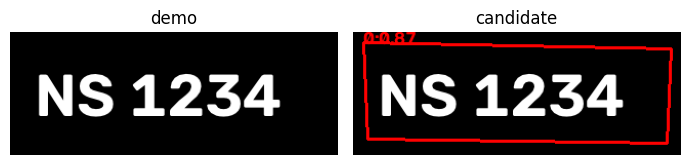

debug 圖已存到: /content/debug/_selftest/00_demo.png


In [5]:
# --- self test: S0 環境檢查（不需要任何資料檔就能跑）---
print('IN_COLAB     =', IN_COLAB)
print('PROJECT_ROOT =', PROJECT_ROOT)
print('DEBUG_DIR    =', DEBUG_DIR)
print('TEST_IMG     =', TEST_IMG, '| 存在:', os.path.exists(TEST_IMG))

demo = np.zeros((120, 320, 3), np.uint8)
cv2.putText(demo, 'NS 1234', (24, 82), cv2.FONT_HERSHEY_SIMPLEX, 2, (255, 255, 255), 4)
q = np.float32([[10, 10], [310, 16], [306, 108], [14, 104]])
cand = Candidate(q, score=0.87, source='demo')
print('bbox =', cand.bbox, '| aspect =', round(cand.aspect, 2))
show(demo, draw_candidates(demo, [cand]), titles=['demo', 'candidate'], cols=2, size=3.5)

p = save_stage('_selftest', '00_demo', draw_candidates(demo, [cand]))
print('debug 圖已存到:', p)


In [6]:
# ==== [S0-5] Colab 環境就緒：缺什麼補什麼（本機執行時整格 no-op） ====
# 為什麼需要這一格：
#   同一份 notebook 在本機與 Colab 各跑一次，實測 Colab 會踩到三個「靜默降級」，
#   三個都不會讓 Run All 失敗，只會讓報告數字變成假的：
#     1. easyocr 沒裝 → [OCR-02] 每張都回空字串，pred="" 但**不報錯**
#     2. shared/rectified_auto/ 不存在 → §8/§9 悄悄退化成「前 5 張」評估
#     3. data/labels.csv 是 [D1-02] 產生的空白骨架，[D1-06] 看到檔案已存在就跳過下載
#        → GT 全空 → [INT-01] 的 only_labelled 把 100 列全濾掉 → A 段完成 0/0 張
#   第 3 點由 [D1-06] 的 self test 處理（它會偵測 text 全空並強制重抓），這裡只做 1、2。
#   把「補了什麼」印出來，讓跑的人看得見，而不是安靜地拿到一份全 0 的結果。

COLAB_REPO_URL = 'https://github.com/onenok/cis342.git'
COLAB_REPO_DIR = '/content/repo'
COLAB_AUTO_DIR = '/content/shared/rectified_auto'   # [INT-01] 的候選路徑之一


def _colab_ensure_easyocr() -> bool:
    """Colab 沒預裝 easyocr；回傳 True 表示現在可以 import。"""
    try:
        import easyocr  # noqa: F401
        print('[S0-5] easyocr 已可用')
        return True
    except ImportError:
        pass
    print('[S0-5] easyocr 未安裝 → 安裝中（約 1-2 分鐘）')
    get_ipython().system('pip install -q easyocr')
    try:
        import easyocr  # noqa: F401
        print('[S0-5] easyocr 安裝完成')
        return True
    except ImportError:
        print('[S0-5] [警告] 安裝後仍無法 import，[OCR-02] 會退化成空結果')
        return False


def _colab_ensure_rectified_auto() -> bool:
    """把 shared/rectified_auto/（26 組，在 git 裡走 LFS）抓到 Colab 的預期路徑。"""
    def marker(d: str) -> bool:
        return os.path.isdir(d) and bool(glob.glob(os.path.join(d, '*_index.csv')))

    if marker(COLAB_AUTO_DIR):
        print('[S0-5] rectified_auto 已存在')
        return True
    if shutil.which('git') is None:
        print('[S0-5] [警告] 找不到 git，無法取得 rectified_auto')
        return False

    get_ipython().system(
        'apt-get -qq -y install git-lfs > /dev/null 2>&1; git lfs install --skip-repo > /dev/null 2>&1')
    if not os.path.isdir(os.path.join(COLAB_REPO_DIR, '.git')):
        print('[S0-5] 複製 repo（--depth 1，只為取 rectified_auto）…')
        get_ipython().system(
            f'git clone --depth 1 {COLAB_REPO_URL} {COLAB_REPO_DIR} 2>&1 | tail -3')
    if os.path.isdir(os.path.join(COLAB_REPO_DIR, '.git')):
        get_ipython().system(
            f'cd {COLAB_REPO_DIR} && git lfs pull -I "project/shared/rectified_auto" 2>&1 | tail -3')
        src = os.path.join(COLAB_REPO_DIR, 'project', 'shared', 'rectified_auto')
        if marker(src):
            os.makedirs(os.path.dirname(COLAB_AUTO_DIR), exist_ok=True)
            if os.path.isdir(COLAB_AUTO_DIR):
                shutil.rmtree(COLAB_AUTO_DIR)
            shutil.copytree(src, COLAB_AUTO_DIR)

    if marker(COLAB_AUTO_DIR):
        n = len(glob.glob(os.path.join(COLAB_AUTO_DIR, '*.png')))
        print(f'[S0-5] rectified_auto 就緒（{n} 張）')
        return True
    print('[S0-5] [警告] 取得 rectified_auto 失敗，§8/§9 會退化成前 5 張')
    return False


if not IN_COLAB:
    print('[S0-5] 本機環境，跳過 Colab 就緒檢查')
else:
    _ready_eocr = _colab_ensure_easyocr()
    _ready_auto = _colab_ensure_rectified_auto()
    print()
    print('[S0-5] 摘要：easyocr =', _ready_eocr, '| rectified_auto =', _ready_auto)
    print('[S0-5] labels.csv 由 [D1-06] 的 self test 檢查（text 全空時會強制重抓）')

[S0-5] easyocr 未安裝 → 安裝中（約 1-2 分鐘）
[S0-5] easyocr 安裝完成
[S0-5] 複製 repo（--depth 1，只為取 rectified_auto）…
Cloning into '/content/repo'...
Filtering content: 100% (345/345), 14.79 MiB | 3.50 MiB/s, done.
[S0-5] rectified_auto 就緒（52 張）

[S0-5] 摘要：easyocr = True | rectified_auto = True
[S0-5] labels.csv 由 [D1-06] 的 self test 檢查（text 全空時會強制重抓）


## A 線：負責章節與開發順序（§1–§5）

**A 線（Localization 前段）**：`Ho Nok Hei`（`S26202765`）
負責「輸入影像 → 校正好的車牌圖」，即 §1 資料集至 §5 幾何校正。

> 🛠️ **【開發用｜提交前刪除】** 以下為 A 線的開發順序與交付內容，不屬於系統說明。

| 順序 | 章節 | 產出 | 解鎖誰 |
|---|---|---|---|
| 1 | **§1 資料集** | `data/images/*.jpg` + `data/labels.csv` | 全部（沒有圖無法驗證） |
| 2 | **§2 前處理** | `preprocess(img)` | §3 車牌定位 |
| 3 | **§3 車牌定位** | `localize_candidates()`、`localize()` | §4 車牌擷取、**B 線可開始接真資料** |
| 4 | **§4 車牌擷取** | `segment(img, quad)` | §5 幾何校正 |
| 5 | **§5 幾何校正** | `rectify(...)` → 存到 `shared/rectified/` | **B 線 OCR 開發** |

> ⚠️ 第 1 週結束前必須把「粗糙但能跑」的定位 + 幾何校正交出去（準確率低沒關係），否則 B 線會空轉一週。

## §1 資料集（D1）

所有影像放在 `data/images/`，標註集中寫在 `data/labels.csv`。§9 的評估只讀這一份標註。

**兩個測試集，分開計算**：

| 集合 | 張數 | 用途 |
|---|---|---|
| `main` | 100 | 主要結果。所有參數調整都在此集合上進行 |
| `external` | 10–15 | 外部來源、**未參與任何調參**，只用來證明非過擬合 |

兩者分開統計，不取總平均 —— 因為兩個來源的影像品質差異大（一為相機原圖、一為通訊軟體壓縮轉傳），
混合平均會掩蓋失誤來源。報告中分開呈現才有說服力。


### 資料集取得方式

本專案的影像與 `labels.csv` **未內嵌在 notebook 中**，而是在執行時下載。交付版本在 Google Colab 執行，
評閱者只要依序執行下列步驟，資料就會自動備妥，不需手動下載任何檔案。

| 步驟 | 模組 | 做什麼 |
|---|---|---|
| 1 | `[D1-04]` | 從 Roboflow 公開直連網址下載 COCO 壓縮檔到 `data/raw/`（**主要方式**，免 API key） |
| 1′ | `[D1-05]` | 上述失效時的備援：用 Google Drive 分享連結下載（免授權、免掛載） |
| 2 | `[D1-02]` | `check_raw_dir()` 確認結構與車牌類別 → `import_coco()` 隨機抽 100 張寫入 `data/images/` 與 `labels.csv` |
| 3 | `[D1-03]` | 逐張人工補上車牌字串、正反面、難度（成果存回 `labels.csv`） |
| 4 | `[D1-06]` | `labels.csv` 的 Drive 收送：組員／評閱者取回已填好的標註 |

`[D1-04]` 與 `[D1-05]` 只需執行其中一個 —— 兩者都會檢查 `data/raw/` 是否已有標註，
已有就自動略過，所以照順序全跑也不會重複下載。兩者共用同一套解壓與結構檢查邏輯。

| 對象 | 取得方式 |
|---|---|
| 評閱者（Colab） | 依上表執行，資料自動下載 |
| 組員（本機編輯） | 執行 `[D1-04]` 或 `[D1-05]` 取得影像，再用 `[D1-06]` 取回共用的 `labels.csv` |
| 沒有網路／連結失效 | `data/` 留空；§1 與 §9 會顯示「尚未建立 labels.csv，略過」，其餘章節需自行指定影像路徑 |

目錄結構：

```
data/
  images/       影像檔案（僅匯入的 100 張，由 [D1-02] 產生）
  labels.csv    標註表（人工填寫，由 [D1-06] 從 Drive 收送）
  raw/          下載解壓的完整 COCO 資料集（僅匯入時使用）
```


### 從 Roboflow 直連下載（主要方式）

Roboflow Universe 匯出後會給一條**免登入**的直連網址，用它抓 COCO 壓縮檔，不需要 API key，
也不會把任何憑證寫進 notebook。

**取得網址**：Roboflow Universe → 該資料集 → **Download Dataset** → 選 `COCO` →
複製頁面上的 `https://universe.roboflow.com/ds/...` 連結（形如 `https://universe.roboflow.com/ds/AbCd?key=XyZ`）。

**為什麼不用 API key 的 `roboflow` 套件**：notebook 會複製給組員、也會遞交給評閱者，
把 API key 寫在裡面等於把帳號額度一起交出去。直連網址本身就是公開下載連結，沒有這個問題。

> 下載後只做兩件事：解壓到 `data/raw/`、呼叫 `[D1-02]` 的 `import_coco()` 抽 100 張。
> 不做「取前 100 張」—— `import_coco()` 是固定種子**隨機**抽樣，避免 100 張全來自同一場景。

> ✏️ **【提交前確認】** 直連網址請確認仍可下載（Roboflow 改版可能失效）。
> 失效時改用下一節 `[D1-05]` 的 Drive 備援。


In [7]:
# ==== [D1-04] 從 Roboflow 直連下載 COCO 資料集 ====
# ✏️ 貼上 Roboflow「Download Dataset → COCO」頁面上的直連網址
ROBOFLOW_COCO_URL = '<貼上 Roboflow 直連下載網址>'

# 選填：記錄出處，供 §1 引用與報告使用
ROBOFLOW_DATASET = 'hk-fszrn (Safety Helmet Detection, Roboflow Universe)'


def has_coco(raw_dir: str = None) -> bool:
    """data/raw/ 底下是否已有 COCO 標註（用判斷要不要重新下載）。"""
    raw_dir = raw_dir or RAW_DIR
    return os.path.isdir(raw_dir) and any(
        '_annotations.coco.json' in fs for _r, _d, fs in os.walk(raw_dir))


def _merge_into(src: str, dst: str) -> None:
    """把 src 底下的檔案逐一覆蓋到 dst（同名目錄遞迴合併，不巢狀複製）。"""
    for name in os.listdir(src):
        s_path, d_path = os.path.join(src, name), os.path.join(dst, name)
        if os.path.isdir(s_path):
            os.makedirs(d_path, exist_ok=True)
            _merge_into(s_path, d_path)
        else:
            shutil.copyfile(s_path, d_path)


def _download_stream(url: str, dest: str, timeout: int = 600, label: str = '下載'):
    """把 url 內容串流寫入 dest，每 10% 印一次進度。

    回傳 (True, None)；若對方回傳的是 HTML（警告頁、權限錯誤）則回傳 (False, html)。
    """
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        if 'text/html' in (r.headers.get('Content-Type') or ''):
            return False, r.read().decode('utf-8', 'ignore')
        total = int(r.headers.get('Content-Length') or 0)
        done, step = 0, 0
        with open(dest, 'wb') as f:
            while True:
                chunk = r.read(1 << 20)
                if not chunk:
                    break
                f.write(chunk)
                done += len(chunk)
                if total:
                    pct = done * 100 / total
                    if pct >= step + 10:
                        step = int(pct // 10 * 10)
                        print(f'{label} {pct:5.1f}%  {done / 1e6:6.0f} / {total / 1e6:.0f} MB')
            if total:
                print(f'{label} 完成  {done / 1e6:.0f} MB')
    return True, None


def extract_coco_zip(zip_path: str, raw_dir: str = None, remove_zip: bool = True) -> bool:
    """把 COCO 壓縮檔解壓到 data/raw/，並壓平多餘的外層資料夾。

    Roboflow / Google Drive 的 zip 常多包一層（如 hk-fszrn.coco/），
    壓平後 train/ valid/ test/ 才會直接位於 data/raw/ 之下。
    """
    raw_dir = raw_dir or RAW_DIR
    os.makedirs(raw_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        names = zf.namelist()
        zf.extractall(raw_dir)
    if remove_zip:
        try:
            os.remove(zip_path)
        except OSError:
            pass

    # 注意：不能用 shutil.move 搬目錄 —— 目標已存在時會搬進目標裡面（變成 train/train）
    tops = {n.split('/')[0] for n in names if '/' in n}
    if len(tops) == 1:
        top = os.path.join(raw_dir, tops.pop())
        if os.path.isdir(top):
            _merge_into(top, raw_dir)
            shutil.rmtree(top, ignore_errors=True)

    if not has_coco(raw_dir):
        print('⚠️ 解壓後找不到 _annotations.coco.json，請確認下載格式選的是 COCO')
        return False
    n = sum(1 for _r, _d, fs in os.walk(raw_dir) if '_annotations.coco.json' in fs)
    print(f'解壓完成：找到 {n} 份 COCO 標註，位於 {raw_dir}')
    print('下一步：執行 [D1-02] 的 check_raw_dir() 確認類別，再跑 import_coco()')
    return True


def download_coco(url: str = None, raw_dir: str = None, force: bool = False) -> bool:
    """下載 Roboflow COCO 壓縮檔並解壓到 data/raw/。

    - 免 API key：使用 Roboflow Universe 提供的公開直連網址
    - 已存在 _annotations.coco.json 時預設不重下（force=True 可強制）
    """
    url = url or ROBOFLOW_COCO_URL
    raw_dir = raw_dir or RAW_DIR

    if not url or url.startswith('<'):
        print('尚未設定 ROBOFLOW_COCO_URL')
        print('請到 Roboflow Universe → Download Dataset → COCO，複製直連網址填入本 cell 開頭')
        return False
    if has_coco(raw_dir) and not force:
        print('data/raw/ 已有 COCO 標註，略過下載（要重新下載請傳 force=True）')
        return True

    os.makedirs(raw_dir, exist_ok=True)
    fd, tmp_zip = tempfile.mkstemp(suffix='.zip')
    os.close(fd)
    print('下載中…')
    try:
        ok, html = _download_stream(url, tmp_zip)
        if not ok:
            print('下載失敗：回傳的是 HTML 頁面，通常代表網址需要登入或已失效')
            print('請確認網址可公開存取（瀏覽器無痕視窗貼上應能直接下載）')
            return False
    except Exception as e:
        print('下載失敗：', type(e).__name__, e)
        print('請確認網址可公開存取（瀏覽器無痕視窗貼上應能直接下載）')
        return False
    finally:
        if not os.path.exists(tmp_zip) or os.path.getsize(tmp_zip) == 0:
            if os.path.exists(tmp_zip):
                os.remove(tmp_zip)

    print(f'檔案大小 {os.path.getsize(tmp_zip) / 1024 / 1024:.1f} MB，解壓中…')
    return extract_coco_zip(tmp_zip, raw_dir)


In [8]:
# --- self test: [D1-04] ---
if download_coco():
    if 'check_raw_dir' in globals():
        check_raw_dir()
    else:
        print('資料集已就緒（結構檢查由 [D1-02] 的 check_raw_dir() 執行）')
else:
    print('尚未取得資料集，後續章節會顯示「略過」')


尚未設定 ROBOFLOW_COCO_URL
請到 Roboflow Universe → Download Dataset → COCO，複製直連網址填入本 cell 開頭
尚未取得資料集，後續章節會顯示「略過」


### 從 Google Drive 連結下載（備援）

當 `[D1-04]` 的 Roboflow 直連失效時，改用這裡。**不需要掛載 Drive、不需要授權**，
只要一條「知道連結的任何人可檢視」的分享連結即可。

**使用方式**：把 Drive 檔案的分享連結貼進 `[D1-05]`，執行後會自動下載並解壓到 `data/raw/`。

> 支援兩種輸入形式：
> - 分享連結：`https://drive.google.com/file/d/<ID>/view?usp=sharing`
> - 純檔案 ID：`<ID>`

**技術說明**：Drive 無法直接下載大型檔案 —— 會先回一個「病毒掃描警告」HTML 頁面，
要從裡面取出 `uuid` 再打第二次 `drive.usercontent.google.com/download`。本 cell 已處理這段。

> ✏️ **【提交前確認】** 連結權限需為「知道連結的任何人可檢視」，否則評閱者無法下載。


In [9]:
# ==== [D1-05] 從 Google Drive 分享連結下載資料集（備援） ====
DRIVE_SHARE_LINK = 'https://drive.google.com/file/d/1eCCV7C5rv4EZLN2uYHWp_ElY1zPDfHDX/view?usp=sharing'


def drive_id_from_link(link: str) -> str:
    """從 Google Drive 分享連結取出檔案 ID；若已是純 ID 則原樣回傳。"""
    link = (link or '').strip()
    m = re.search(r'/file/d/([A-Za-z0-9_-]{10,})', link)
    if m:
        return m.group(1)
    m = re.search(r'[?&]id=([A-Za-z0-9_-]{10,})', link)
    if m:
        return m.group(1)
    return link if re.fullmatch(r'[A-Za-z0-9_-]{10,}', link) else ''


def download_drive_zip(link: str = None, raw_dir: str = None, force: bool = False) -> bool:
    """用 Drive 分享連結下載壓縮檔並解壓到 data/raw/（不需掛載 Drive）。

    Drive 對大檔會先回「病毒掃描警告」HTML，需取出 uuid 後再打一次，
    帶 confirm=t 才會真的開始傳檔案。
    """
    link = link or DRIVE_SHARE_LINK
    raw_dir = raw_dir or RAW_DIR

    fid = drive_id_from_link(link)
    if not fid:
        print('無法從連結取出檔案 ID，請貼完整的 Drive 分享連結或純 ID')
        return False
    if has_coco(raw_dir) and not force:
        print('data/raw/ 已有 COCO 標註，略過下載（要重新下載請傳 force=True）')
        return True

    os.makedirs(raw_dir, exist_ok=True)
    fd, tmp_zip = tempfile.mkstemp(suffix='.zip')
    os.close(fd)

    base = 'https://drive.google.com/uc?export=download&id=' + fid
    print('下載中…')
    try:
        ok, html = _download_stream(base, tmp_zip, label='下載')
        if not ok:
            # 大型檔案：先取 confirm / uuid 再重試一次
            m_uuid = re.search(r'name="uuid"\s+value="([^"]+)"', html or '')
            m_conf = re.search(r'name="confirm"\s+value="([^"]+)"', html or '')
            if not (m_uuid and m_conf):
                print('下載失敗：回傳的是 HTML 頁面，且找不到 confirm 參數')
                print('常見原因：連結權限不是「知道連結的任何人可檢視」')
                return False
            retry = ('https://drive.usercontent.google.com/download'
                     f'?id={fid}&export=download&confirm={m_conf.group(1)}&uuid={m_uuid.group(1)}')
            print('檔案較大，需要確認下載（病毒掃描警告頁），自動重試…')
            ok, html = _download_stream(retry, tmp_zip, label='下載')
            if not ok:
                print('下載失敗：重試後仍取得 HTML 頁面，請確認連結權限')
                return False
    except Exception as e:
        print('下載失敗：', type(e).__name__, e)
        print('請確認連結可公開存取（瀏覽器無痕視窗貼上應能直接下載）')
        return False
    finally:
        if os.path.exists(tmp_zip) and os.path.getsize(tmp_zip) == 0:
            os.remove(tmp_zip)

    print(f'檔案大小 {os.path.getsize(tmp_zip) / 1024 / 1024:.1f} MB，解壓中…')
    return extract_coco_zip(tmp_zip, raw_dir)


In [10]:
# --- self test: [D1-05] ---
if download_drive_zip():
    if 'check_raw_dir' in globals():
        check_raw_dir()
    else:
        print('資料集已就緒（結構檢查由 [D1-02] 的 check_raw_dir() 執行）')
else:
    print('尚未取得資料集，後續章節會顯示「略過」')


下載中…
檔案較大，需要確認下載（病毒掃描警告頁），自動重試…
下載  10.1%     103 / 1021 MB
下載  20.0%     204 / 1021 MB
下載  30.1%     307 / 1021 MB
下載  40.0%     409 / 1021 MB
下載  50.0%     511 / 1021 MB
下載  60.1%     613 / 1021 MB
下載  70.0%     715 / 1021 MB
下載  80.1%     818 / 1021 MB
下載  90.1%     920 / 1021 MB
下載 100.0%    1021 / 1021 MB
下載 完成  1021 MB
檔案大小 973.8 MB，解壓中…
解壓完成：找到 2 份 COCO 標註，位於 /content/data/raw
下一步：執行 [D1-02] 的 check_raw_dir() 確認類別，再跑 import_coco()
資料集已就緒（結構檢查由 [D1-02] 的 check_raw_dir() 執行）


### 資料集來源與引用

本專案的影像來自 Roboflow Universe 上的公開資料集。兩者皆為 **CC BY 4.0** 授權，
依授權要求需標明原作者與出處。

| 用途 | 資料集 | 張數 | 授權 |
|---|---|---|---|
| 主要測試集（`main`） | [hk Computer Vision Dataset](https://universe.roboflow.com/safety-helmet-detection-lvkib/hk-fszrn) | 1,491（取 100 張） | CC BY 4.0 |
| 外部測試集（`external`） | [HK License Plate Recognition](https://universe.roboflow.com/hong-kong-license-plate-detect/hk-license-plate-recognition) | 33（取 10–15 張） | CC BY 4.0 |

主要測試集的建議引用格式（由 Roboflow 頁面提供）：

```bibtex
@misc{ hk-fszrn_dataset,
  title     = { hk Dataset },
  type      = { Open Source Dataset },
  author    = { Safety Helmet Detection },
  howpublished = { \url{ https://universe.roboflow.com/safety-helmet-detection-lvkib/hk-fszrn } },
  url       = { https://universe.roboflow.com/safety-helmet-detection-lvkib/hk-fszrn },
  journal   = { Roboflow Universe },
  publisher = { Roboflow },
  year      = { 2026 },
  month     = { apr },
  note      = { visited on 2026-11-19 }
}
```

> 兩份資料集都只提供**車牌邊界框**，不含車牌字串。`labels.csv` 的 `text` 欄由本組人工逐張填寫。


### `labels.csv` 欄位

| 欄位 | 型別 | 說明 |
|---|---|---|
| `file` | str | 影像檔名（不含路徑），例如 `IMG_5129.jpg` |
| `plate_idx` | str | 同一張圖的第幾個車牌；單車牌固定填 `0`（為多車牌擴充預留） |
| `split` | str | `main`（主要測試集）或 `external`（外部測試集，只用於交叉驗證，不參與調參） |
| `text` | str | 正確車牌字串，全大寫、**只留英數與中文**。`RDA•2388`、`RDA-2388`、`RDA 2388` 一律寫成 `RDA2388`（`save_label()` 會自動去除分隔符號） |
| `front_rear` | str | `front`（白底）或 `rear`（黃底） |
| `difficulty` | str | `normal` / `hard` / `unreadable`（語意見下） |
| `note` | str | 備註（側拍、陰影、部分遮擋、同圖含粵Z黑牌…），可留空 |

**車牌字串寫法**：

- 香港車牌印刷上常有中間圓點（`RDA•2388`）或連字號（`RDA-2388`），但**那不是字元**，
  只是排版分隔。`text` 只填真正的字元，即 `RDA2388`。
- 跨境車牌含中文字（如 `粵Z·1234`）時，中文保留、圓點去掉 → `粵Z1234`。
- 全部大寫，不要空白。`save_label()` 與 `import_coco()` 都遵循同一規則，
  所以手改 CSV 時也請照這個格式，否則 §9 評估會把它判成錯誤。

**`difficulty` 的意義**：

| 值 | 意義 | 是否計入 §9 準確率 |
|---|---|---|
| `normal` | 光線與角度正常，可直接判讀 | ✅ 計入（評分主力，89 張） |
| `hard` | 模糊、部分被遮、或標註框其實不是車牌，但仍判斷得出答案 | ✅ 計入（10 張） |
| `unreadable` | 人眼亦不可判讀（如車牌中間被反光白塊完全蓋住） | ❌ 排除（1 張） |
| `not_plate` | 標註框不是車牌（保留給未來，目前無此值） | ❌ 排除 |

`unreadable` 的列 **`text` 刻意留空**，代表「這是資料本身的限制，不是標錯」。
硬猜一個字串會製造假的標準答案，讓 §9 的準確率失真；整列刪掉又會讓樣本數
對不上 `labels.csv`。因此改用「保留該列、評估時排除」的做法，
並在報告中明確寫<|place_holder_mm_span_0442|>數量與排除理由（見 `TASK_DIVISION.md` §7）。

**單一車牌原則**：本版 `run_pipeline()` 每次只輸出一個車牌字串。若一張圖有多個車牌，
只標註**面積最大**的那一個（`[D1-02]` 已自動依此挑選），其餘視為背景。
`plate_idx` 是為日後擴充多車牌預留的欄位，現在每張圖只需一列。


In [11]:
# ==== [D1-01] 讀取標註表 ====
LABEL_COLUMNS = ['file', 'plate_idx', 'split', 'text', 'front_rear', 'difficulty', 'note']


def load_labels(path: str = LABELS_CSV) -> pd.DataFrame:
    """讀取 labels.csv，缺欄位會直接報錯，避免大家各寫各的格式。"""
    if not os.path.exists(path):
        return pd.DataFrame(columns=LABEL_COLUMNS)
    df = pd.read_csv(path, dtype=str).fillna('')
    missing = [c for c in LABEL_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f'labels.csv 缺少欄位：{missing}')
    return df[LABEL_COLUMNS]


def file_sort_key(fname: str) -> str:
    """排序鍵：直接用檔名字串，從最左邊字元開始比。

    這樣 labels.csv 的列序才會跟檔案總管看到的順序一致 ——
    填標註時是一邊開著資料夾、一邊照順序往下填，順序對不上就要一直回頭找。
    """
    return str(fname)


def normalize_plate_text(text: str) -> str:
    """把使用者輸入的車牌字串正規化成統一格式。

    規則：全形轉半形（NFKC）→ 全大寫 → 只保留英數與中文。
    香港車牌印刷上常有中間圓點（RDA•2388）或連字號（RDA-2388），
    但那些只是排版分隔、不是字元；若不拿掉，§9 評估會把它們判成錯誤。
    跨境車牌的中文字（粵Z）要保留，所以不能只留 A-Z0-9。
    """
    s = unicodedata.normalize('NFKC', str(text)).upper()
    return re.sub(r'[^0-9A-Z\u4e00-\u9fff]', '', s)


FP_RE = re.compile(r'fp=([0-9a-f]{8})')


def _stamp_fp(note: str, fp: str) -> str:
    """把抽樣指紋寫進 note 欄（重複呼叫不會疊加）。"""
    note = FP_RE.sub('', str(note)).rstrip('; ')
    return (note + ';' if note else '') + f'fp={fp}'


def _labels_fingerprint(df=None) -> str:
    """從 labels.csv 的 note 欄讀出抽樣指紋；沒有記錄就回傳 ''。

    指紋是「這批影像是哪 100 張」的身分證。車牌字串只對這 100 張有效，
    換一批影像就等於沒有正確答案，所以指紋一定要跟著 labels.csv 走。
    """
    df = load_labels() if df is None else df
    if df is None or df.empty:
        return ''
    for v in df['note'].astype(str):
        m = FP_RE.search(v)
        if m:
            return m.group(1)
    return ''

In [12]:
# --- self test: [D1-01] ---
labels = load_labels()
print('labels.csv 筆數:', len(labels))
print('已存在的影像數:', len(os.listdir(DATA_DIR)) if os.path.isdir(DATA_DIR) else 0)
if len(labels):
    _fp = _labels_fingerprint(labels)
    print('抽樣指紋:', _fp or '(未記錄)')
    if not _fp:
        print('⚠️ labels.csv 沒有指紋（可能來自舊版）。填完標註前建議重跑一次 [D1-02] 讓它寫入。')
    display(labels.head())
else:
    print('尚未建立 labels.csv，欄位定義已就緒：', LABEL_COLUMNS)

labels.csv 筆數: 0
已存在的影像數: 0
尚未建立 labels.csv，欄位定義已就緒： ['file', 'plate_idx', 'split', 'text', 'front_rear', 'difficulty', 'note']


In [13]:
# ==== [D1-02] 由 Roboflow COCO 標註匯入影像與 labels.csv 骨架 ====
# 用法：
#   1. 取得 COCO 資料集到 data/raw/（[D1-04] 直連下載，或 [D1-05] 從 Drive 同步）
#   2. 先跑 check_raw_dir() 確認結構與類別名稱
#   3. 再跑 import_coco() → 產生 data/images/* 與 data/labels.csv（text 留空）
#   4. 最後用 [D1-03] 逐張輸入車牌字串
# RAW_DIR 定義在 [S0-2] 共用常數
IMPORT_LIMIT_TOTAL = 100   # 總共匯入幾張（跨 train/valid/test 合計）
MIN_PLATE_W = 40           # 車牌寬度小於此值直接跳過（太小無法辨識，標了也用不上）
FORCE_RESAMPLE = False     # True＝即使指紋不符也強制重抽（會讓已填的 text 全部失效，慎用）

# 車牌類別名稱。留空＝自動判斷：單一類別直接用；多類別時用 plate / 車牌 / number 關鍵字猜。
# check_raw_dir() 印出的「車牌類別」欄若顯示「(不篩選)」或猜錯，就把正確名稱填在這裡。
# 本專案資料集（hk-fszrn v2）只有一個真正的標註類別：license_plate。
# 另一個 ploatew-license-plate 是 Roboflow 自動產生的父類別（supercategory），底下沒有標註，已自動排除。
PLATE_CATEGORY = 'license_plate'


def _plate_category_ids(coco: dict, want: str = '') -> Optional[set]:
    """挑出「車牌」類別的 category_id。回傳 None 代表不做類別篩選。

    資料集若同時標了安全帽、人、車等類別，不篩類別就會把最大框當成車牌 —— 這是錯的。
    """
    cats = coco.get('categories', [])
    if not cats:
        return None
    names = {c.get('id'): str(c.get('name', '')) for c in cats}

    if want:
        ids = {cid for cid, n in names.items() if want.lower() in n.lower()}
        if not ids:
            print(f'⚠️ 找不到類別「{want}」，實際類別：{list(names.values())}；改為自動判斷')
        else:
            return ids

    if len(names) == 1:
        return set(names)

    # Roboflow 會多塞一個父類別（supercategory='none'），它底下沒有任何標註，
    # 但名稱同樣含 plate，會讓「車牌類別」多一欄。把被別人當 supercategory 的排除。
    parents = {str(c.get('supercategory', '')) for c in cats} - {'none', ''}
    names = {cid: n for cid, n in names.items() if n not in parents}
    if not names:
        names = {c.get('id'): str(c.get('name', '')) for c in cats}
    if len(names) == 1:
        return set(names)

    keywords = ('plate', '車牌', 'number')
    ids = {cid for cid, n in names.items() if any(k in n.lower() for k in keywords)}
    if ids:
        return ids

    print(f'⚠️ 多類別但判斷不出哪個是車牌：{list(names.values())}')
    print('   請把類別名稱填入 PLATE_CATEGORY 後重跑；目前暫不篩選類別')
    return None


def check_raw_dir(raw_dir: str = None) -> pd.DataFrame:
    """列出 data/raw/ 底下找到的 COCO 標註檔、影像數量與車牌類別，確認結構正確。

    Roboflow 解壓後可能多包一層資料夾（例如 hk-fszrn.coco/），
    本函式會遞迴搜尋，不限固定層數。
    """
    raw_dir = raw_dir or RAW_DIR
    if not os.path.isdir(raw_dir):
        print(f'找不到 {raw_dir}')
        print('請先執行 [D1-04] 直連下載，或把資料集解壓到 data/raw/ 底下')
        return pd.DataFrame()

    rows = []
    for root, _dirs, files in os.walk(raw_dir):
        _dirs.sort()   # 固定順序，否則本機與 Colab 印出的 split 次序會不一樣
        if '_annotations.coco.json' not in files:
            continue
        ann_path = os.path.join(root, '_annotations.coco.json')
        with open(ann_path, encoding='utf-8') as f:
            coco = json.load(f)
        imgs = coco.get('images', [])
        anns = coco.get('annotations', [])
        # 實際存在的影像檔數
        present = sum(1 for im in imgs if os.path.exists(os.path.join(root, im['file_name'])))
        cats = [c.get('name', '?') for c in coco.get('categories', [])]
        ids = _plate_category_ids(coco, PLATE_CATEGORY)
        used = [c.get('name', '?') for c in coco.get('categories', []) if ids and c.get('id') in ids]
        rows.append({
            '資料夾': os.path.relpath(root, raw_dir),
            '影像(標註)': len(imgs),
            '影像(實際存在)': present,
            '標註框': len(anns),
            '類別': ', '.join(cats) if cats else '(無)',
            '車牌類別': ', '.join(used) if used else '(不篩選)',
        })

    if not rows:
        print(f'{raw_dir} 底下找不到 _annotations.coco.json')
        print('請確認解壓的是 COCO 格式，而不是 YOLO / VOC 格式')
        return pd.DataFrame()

    df = pd.DataFrame(rows)
    print(f'在 {raw_dir} 找到 {len(df)} 份 COCO 標註：')
    print(df.to_string(index=False))
    if (df['車牌類別'] == '(不篩選)').any():
        print('\n⚠️ 有資料夾未篩選類別，可能把非車牌物件當成車牌。')
        print('   請把「類別」欄中代表車牌的名稱填入 PLATE_CATEGORY 後重跑本 cell。')
    return df


def import_coco(raw_dir: str = None, limit_total: int = IMPORT_LIMIT_TOTAL,
                split_tag: str = 'main', min_plate_w: int = MIN_PLATE_W,
                seed: int = RANDOM_SEED, force_resample: bool = FORCE_RESAMPLE) -> pd.DataFrame:
    """把 Roboflow COCO 標註轉成本專案的 labels.csv 骨架。

    - 只取車牌類別的標註（避免抓到安全帽等其他物件）
    - 跨所有 split 收集後以固定種子隨機抽樣，避免只拿到某一類場景
    - 單一車牌原則：只取面積最大的車牌標註
    - 車牌太窄（< min_plate_w）或影像檔不存在者一律跳過
    - bbox 記在 note 欄，供 [D1-03] 顯示與日後重切使用
    - 重跑時不覆蓋已人工填寫的 text / front_rear / difficulty
    - 抽樣指紋寫進 note 並鎖定：指紋不符就拒絕重抽，避免 text 對錯影像
    """
    raw_dir = raw_dir or RAW_DIR
    if not os.path.isdir(raw_dir):
        print(f'找不到 {raw_dir}，請先執行 [D1-05] 下載或同步資料集')
        return pd.DataFrame(columns=LABEL_COLUMNS)

    pool, skipped = [], {'無標註': 0, '缺檔': 0, '車牌太小': 0}
    for root, dirs, files in os.walk(raw_dir):
        # 排序：os.walk 的順序隨檔案系統而異，不排序的話不同機器抽到的 100 張會不一樣
        dirs.sort()
        files.sort()
        if '_annotations.coco.json' not in files:
            continue
        split = os.path.basename(root).lower() or 'unknown'
        with open(os.path.join(root, '_annotations.coco.json'), encoding='utf-8') as f:
            coco = json.load(f)

        cat_ids = _plate_category_ids(coco, PLATE_CATEGORY)
        cat_name = {c.get('id'): str(c.get('name', '')) for c in coco.get('categories', [])}
        boxes = {}
        for a in coco.get('annotations', []):
            boxes.setdefault(a['image_id'], []).append(a)

        for im in coco.get('images', []):
            anns = boxes.get(im['id'], [])
            if cat_ids is not None:
                anns = [a for a in anns if a.get('category_id') in cat_ids]
            if not anns:
                skipped['無標註'] += 1
                continue
            best = max(anns, key=lambda a: a['bbox'][2] * a['bbox'][3])
            x, y, bw, bh = [int(round(v)) for v in best['bbox']]
            if bw < min_plate_w:
                skipped['車牌太小'] += 1
                continue
            src_img = os.path.join(root, im['file_name'])
            if not os.path.exists(src_img):
                skipped['缺檔'] += 1
                continue
            pool.append({
                'src': src_img,
                'name': f'{split}_{os.path.basename(im["file_name"])}',
                'note': (f'bbox={x},{y},{bw},{bh};n_obj={len(anns)};'
                         f'cat={cat_name.get(best.get("category_id"), "?")}'),
            })

    if not pool:
        print('沒有可匯入的影像，請先執行 check_raw_dir() 檢查結構與類別')
        return pd.DataFrame(columns=LABEL_COLUMNS)

    # 固定種子抽樣。抽樣前先依檔名排序 —— 否則 pool 的順序取決於檔案系統，
    # 同一份資料集在不同機器（本機 / Colab）會抽到不同的 100 張，
    # 導致 labels.csv 與影像對不上。
    pool.sort(key=lambda d: d['name'])
    random.Random(seed).shuffle(pool)
    picked = pool[:limit_total]

    # 抽樣指紋＝這批影像是哪 100 張的身分證。text 只對這批影像有效，
    # 所以指紋會寫進 note 並鎖定：換一批就代表所有 text 都要重填。
    fp = hashlib.md5('|'.join(sorted(d['name'] for d in picked)).encode()).hexdigest()[:8]
    if os.path.exists(LABELS_CSV) and not force_resample:
        locked = _labels_fingerprint()
        if locked and locked != fp:
            print(f'❌ 抽樣指紋不符：labels.csv 已鎖定 {locked}，本次抽到的是 {fp}。')
            print('   兩批影像不同，沿用舊 labels.csv 會讓 text 全部對錯圖片。')
            print('   請確認資料集版本與 RANDOM_SEED 沒有被改動；')
            print('   若真的想換一批（現有 text 全部作廢），先設 FORCE_RESAMPLE = True 再重跑。')
            return load_labels()
        if locked:
            print(f'抽樣指紋 {fp} 與 labels.csv 相符，重跑不會動到已填的 text。')

    os.makedirs(DATA_DIR, exist_ok=True)
    rows = []
    for item in picked:
        shutil.copyfile(item['src'], os.path.join(DATA_DIR, item['name']))
        rows.append({
            'file': item['name'],
            'plate_idx': '0',
            'split': split_tag,
            'text': '',          # 待人工填寫
            'front_rear': '',    # 待人工判斷
            'difficulty': '',    # 待人工判斷
            'note': _stamp_fp(item['note'], fp),
        })

    df = pd.DataFrame(rows, columns=LABEL_COLUMNS)
    dropped = 0
    if os.path.exists(LABELS_CSV):
        old = load_labels()
        # 已人工填過的值優先保留（重跑不可清空這些欄位）
        prev = old.drop_duplicates('file').set_index('file')
        for col in ('text', 'front_rear', 'difficulty'):
            keep = prev[col].astype(str).str.strip()
            filled = keep[keep != ''].to_dict()
            df[col] = [filled.get(f, v) for f, v in zip(df['file'], df[col])]
        # 這次沒抽到的舊列一律丟棄 —— labels.csv 必須剛好是本次抽樣結果，
        # 否則重跑會不斷累積、張數愈來愈多，與「main 100 張」的契約不符。
        gone = old[~old['file'].isin(df['file'])]
        dropped = len(gone)
        # 連影像檔一起清掉，否則 data/images/ 會殘留上一批的檔案。
        # 只刪「舊 labels.csv 有登記」的，自訂測試圖不會被動到。
        for fname in gone['file'].astype(str):
            fp_img = os.path.join(DATA_DIR, fname)
            if os.path.exists(fp_img):
                os.remove(fp_img)
        lost = gone[gone['text'].astype(str).str.strip() != '']
        if len(lost):
            print(f'⚠️ 有 {len(lost)} 筆已填好車牌字串的列不在本次抽樣中，將被移除：')
            print('   ', ', '.join(lost['file'].head(5)) + (' …' if len(lost) > 5 else ''))
            print('   若不想失去這些標註，請保留原 labels.csv 不要重跑匯入。')
    # 依檔名字串排序後才寫檔，打開 CSV 就與檔案總管顯示順序一致
    df = df.sort_values('file').reset_index(drop=True)
    df.to_csv(LABELS_CSV, index=False, encoding='utf-8-sig')

    print(f'候選 {len(pool)} 張，實際匯入 {len(rows)} 張｜抽樣指紋 {fp}')
    print('（指紋可用來確認本機與 Colab 抽到同一批影像；不一致就代表資料集版本不同）')
    if any(skipped.values()):
        print('已跳過：', '｜'.join(f'{k} {v} 張' for k, v in skipped.items() if v))
    if dropped:
        print(f'已移除 {dropped} 列不在本次抽樣中的舊資料')
    print(f'labels.csv 目前共 {len(df)} 列（text 待填）')
    return df


In [14]:
# --- self test: [D1-02] ---
check_raw_dir()
_df = import_coco()
if _df.empty:
    print('尚未匯入資料集（需要 data/raw/ 底下的 COCO 解壓結果）')
else:
    _todo = int((_df['text'].astype(str).str.strip() == '').sum())
    print(f'已標註 {len(_df) - _todo} 張，待填 text {_todo} 張')
    print('逐張填寫請用下一節的 [D1-03]')


在 /content/data/raw 找到 2 份 COCO 標註：
  資料夾  影像(標註)  影像(實際存在)  標註框                                   類別          車牌類別
train    1044      1044 1232 ploatew-license-plate, license_plate license_plate
valid     447       447  548 ploatew-license-plate, license_plate license_plate
候選 1475 張，實際匯入 100 張｜抽樣指紋 bd1a4489
（指紋可用來確認本機與 Colab 抽到同一批影像；不一致就代表資料集版本不同）
已跳過： 車牌太小 16 張
labels.csv 目前共 100 列（text 待填）
已標註 0 張，待填 text 100 張
逐張填寫請用下一節的 [D1-03]


### 半自動標註

Roboflow 只給 bbox，**車牌字串必須人工填**。以下三個函式把流程縮到最短：
`label_progress()` 看剩多少 → `annotate_next()` 逐張填 → `save_label()` 可單筆手動補。

`annotate_next()` 需要 `ipywidgets`（Colab 內建；本機若無請先 `%pip install ipywidgets`）。
若無法使用，改用 `save_label('檔名.jpg', 'NS1234', 'front', 'normal')` 直接寫入。


In [15]:
# ==== [D1-03] 半自動標註工具 ====
def _parse_bbox(note: str):
    """從 note 欄的 bbox=x,y,w,h 取回座標。"""
    m = re.search(r'bbox=(-?\d+),(-?\d+),(\d+),(\d+)', note or '')
    return tuple(int(v) for v in m.groups()) if m else None


def sort_labels_csv(path: str = LABELS_CSV) -> pd.DataFrame:
    """把 labels.csv 依檔名數字重新排序後寫回（不改變任何內容）。"""
    df = load_labels(path)
    if df.empty:
        print('labels.csv 為空，略過排序')
        return df
    df = df.sort_values('file').reset_index(drop=True)
    df.to_csv(path, index=False, encoding='utf-8-sig')
    return df


def _is_labelled(df: pd.DataFrame) -> pd.Series:
    """是否已處理完畢：text 非空，或 difficulty 屬不可評分。

    unreadable 的列 text 刻意留空（見 labels.csv 欄位說明），
    若只看 text 是否空白，這些列會永遠顯示「未標註」。
    """
    has_text   = df['text'].astype(str).str.strip() != ''
    unscorable = df['difficulty'].astype(str).isin(UNSCORABLE_DIFFICULTIES)
    return has_text | unscorable


def label_progress(df: Optional[pd.DataFrame] = None) -> pd.DataFrame:
    """統計各 split 已處理／待處理的張數。

    已處理的定義見 _is_labelled()：填了 text，或標成 unreadable。
    """
    df = load_labels() if df is None else df
    if df.empty:
        print('labels.csv 為空，請先執行 [D1-02] 匯入資料集')
        return pd.DataFrame()
    df = df.copy()
    df['done'] = _is_labelled(df)
    tab = df.groupby('split')['done'].agg(總數='size', 已標註='sum')
    tab['未標註'] = tab['總數'] - tab['已標註']
    print(tab)
    return tab


def next_unlabeled(df: Optional[pd.DataFrame] = None) -> Optional[str]:
    """回傳下一張尚未填 text 的檔名。"""
    df = load_labels() if df is None else df
    if df.empty:
        return None
    todo = df[~_is_labelled(df)]
    if todo.empty:
        return None
    # 依檔名字串排序，與檔案總管顯示順序一致，才不用一直回頭找圖
    todo = todo.sort_values('file')
    return str(todo.iloc[0]['file'])


def show_label_target(fname: str, size: float = 7.0):
    """顯示要標註的影像並框出 bbox，方便對照打車牌字串。"""
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f'找不到影像：{path}')
        return None
    img = load_image(path)
    df = load_labels()
    row = df[df['file'] == fname]
    vis = img.copy()
    if not row.empty:
        bb = _parse_bbox(str(row.iloc[0]['note']))
        if bb:
            x, y, w, h = bb
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 2)
    # bbox 是原始座標，縮圖後需等比縮放才對得準
    h0, w0 = cv2.imread(path).shape[:2]
    sc = img.shape[1] / max(w0, 1)
    if sc < 1.0 and not row.empty:
        bb = _parse_bbox(str(row.iloc[0]['note']))
        if bb:
            vis = img.copy()
            x, y, w, h = [int(v * sc) for v in bb]
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 2)
    show(vis, titles=[fname], cols=1, size=size)
    return img


def save_label(fname: str, text: str, front_rear: str, difficulty: str,
               note: Optional[str] = None) -> None:
    """寫入或更新一筆標註。

    text 正規化為全大寫，並移除所有分隔符號 —— 含空白與各種中間圓點。
    香港車牌印刷上常見 `RDA•2388`、`RDA-2388`、`RDA 2388` 等寫法，
    但字串本身只有 `RDA2388`；若把圓點留下來，§9 評估會全部判成錯誤。
    """
    df = load_labels()
    if df.empty:
        print('labels.csv 為空，請先執行 [D1-02]')
        return
    clean = normalize_plate_text(text)
    if not clean and difficulty not in UNSCORABLE_DIFFICULTIES:
        print('text 不可為空（若影像真的不可判讀，difficulty 選 unreadable 再儲存）')
        return
    mask = df['file'].astype(str) == fname
    if not mask.any():
        print(f'labels.csv 沒有 {fname}，請確認檔名')
        return
    df.loc[mask, 'text'] = clean
    df.loc[mask, 'front_rear'] = front_rear
    df.loc[mask, 'difficulty'] = difficulty
    if note is not None:
        df.loc[mask, 'note'] = note
    df.to_csv(LABELS_CSV, index=False, encoding='utf-8-sig')
    print(f'已寫入：{fname} -> {clean} ({front_rear}, {difficulty})')


def annotate_next():
    """互動式逐張標註：顯示影像 → 輸入字串 → 儲存後自動跳下一張。"""
    try:
        import ipywidgets as widgets
        from IPython.display import display as _display, clear_output
    except ImportError:
        print('未安裝 ipywidgets，請執行 %pip install ipywidgets；'
              '或改用 save_label() 手動逐筆寫入')
        return None

    fname = next_unlabeled()
    if fname is None:
        print('全部標註完成')
        return None

    show_label_target(fname)
    box = widgets.Text(description='車牌：', placeholder='NS1234')
    fr = widgets.Dropdown(description='前/後：', options=['front', 'rear'])
    diff = widgets.Dropdown(description='難度：', options=list(LABEL_DIFFICULTIES), value='normal')
    btn = widgets.Button(description='儲存並下一張', button_style='success')
    out = widgets.Output()

    def _on_click(_):
        with out:
            clear_output()
            save_label(fname, box.value, fr.value, diff.value)
            label_progress()
        nxt = next_unlabeled()
        if nxt is None:
            print('全部標註完成')
        else:
            show_label_target(nxt)

    btn.on_click(_on_click)
    return _display(widgets.VBox([box, fr, diff, btn, out]))


In [16]:
# --- self test: [D1-03] ---
label_progress()
_nxt = next_unlabeled()
print('下一張待標註：', _nxt if _nxt else '（無，或標註已完成）')


        總數  已標註  未標註
split               
main   100    0  100
下一張待標註： train_IMG_1231_JPG.rf.4427265fe92179f31edca9a21230e353.jpg


### `labels.csv` 的取得與回存

`labels.csv` 不會下載自資料集（Roboflow 只給標註框，不給車牌字串），它是**人工填寫**的成果，
所以另外放在 Google Drive，由本節負責收送。

- **下載**：`[D1-06]` 的 `LABELS_SHARE_LINK` 填 Drive 分享連結，執行 `download_labels()` 取回
- **回存**：填完後執行 `save_labels_to_drive()`；在 Colab 會直接存到 `/content/drive/...`，
  本機則用 `files.download()` 產出檔案由你手動上傳

> ✏️ **【提交前確認】** `LABELS_SHARE_LINK` 已填、權限為「知道連結的任何人可檢視」。

**為什麼要綁抽樣指紋**：`text` 是「第 N 張影像的正確答案」，換一批影像就全部對不上。
`[D1-02]` 會把抽樣指紋寫進 `note`（`fp=xxxxxxxx`）並鎖定，
`[D1-06]` 下載後也會比對 —— 指紋不符就停下來警告，不會讓你填了半天卻對錯圖片。


In [17]:
# ==== [D1-06] labels.csv 的 Drive 同步（下載 / 回存） ====
# labels.csv 是人工填寫的成果，不從資料集取得，因此單獨放在 Google Drive 收送。
# 建立方式：把填好的 data/labels.csv 上傳到 Drive，共用設為「知道連結的任何人可檢視」，
#           再把連結貼到下面（留空＝不同步，只使用本機的 data/labels.csv）。
LABELS_SHARE_LINK = 'https://drive.google.com/file/d/1AOZo8TyTXWugr4dYUqdU2bRrYS18cuJZ/view?usp=sharing'   # 例：'https://drive.google.com/file/d/<ID>/view?usp=sharing'


def download_labels(link: str = None, dest: str = None, force: bool = False) -> pd.DataFrame:
    """從 Drive 取回 labels.csv。本機已存在且非 force 時不動它。"""
    link = LABELS_SHARE_LINK if link is None else link
    dest = dest or LABELS_CSV

    if not (link or '').strip():
        print('未設定 LABELS_SHARE_LINK，沿用本機的 data/labels.csv')
        return load_labels()
    if os.path.exists(dest) and not force:
        print(f'{os.path.basename(dest)} 已存在，略過下載（要覆蓋請傳 force=True）')
        return load_labels()

    fid = drive_id_from_link(link)
    if not fid:
        print('無法從連結取出檔案 ID，請貼完整的 Drive 分享連結或純 ID')
        return load_labels()

    os.makedirs(os.path.dirname(dest) or '.', exist_ok=True)
    fd, tmp = tempfile.mkstemp(suffix='.csv')
    os.close(fd)
    base = 'https://drive.google.com/uc?export=download&id=' + fid
    print('下載 labels.csv…')
    try:
        ok, html = _download_stream(base, tmp, timeout=120, label='下載')
        if not ok:
            m_uuid = re.search(r'name="uuid"\s+value="([^"]+)"', html or '')
            m_conf = re.search(r'name="confirm"\s+value="([^"]+)"', html or '')
            if not (m_uuid and m_conf):
                print('下載失敗：回傳 HTML 頁面。請確認連結權限為「知道連結的任何人可檢視」')
                return load_labels()
            retry = ('https://drive.usercontent.google.com/download'
                     f'?id={fid}&export=download&confirm={m_conf.group(1)}&uuid={m_uuid.group(1)}')
            ok, html = _download_stream(retry, tmp, timeout=120, label='下載')
            if not ok:
                print('下載失敗：重試後仍取得 HTML 頁面，請確認連結權限')
                return load_labels()
        shutil.copyfile(tmp, dest)
    except Exception as e:
        print('下載失敗：', type(e).__name__, e)
        return load_labels()
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)

    df = load_labels(dest)
    print(f'已取回 {len(df)} 列')

    # 指紋比對 —— 若這份 labels.csv 是為另一批影像填的，text 會全部對不上
    remote_fp = _labels_fingerprint(df)
    local_fp = _labels_fingerprint() if remote_fp else ''
    if remote_fp and local_fp and remote_fp != local_fp:
        print(f'⚠️ 指紋不符：這份 labels.csv 是 {remote_fp}，本機影像卻是 {local_fp}。')
        print('   車牌字串會對錯圖片，請確認是否拿錯檔案。')
    elif remote_fp:
        print(f'抽樣指紋 {remote_fp} 與本機影像相符')
    return df


def save_labels_to_drive(dest_dir: str = '/content/drive/MyDrive', name: str = 'labels.csv') -> bool:
    """把目前的 labels.csv 回存。Colab 有掛載 Drive 就寫進去，否則用瀏覽器下載。"""
    if not os.path.exists(LABELS_CSV):
        print('找不到 data/labels.csv，請先執行 [D1-02]')
        return False
    df = load_labels()
    fp = _labels_fingerprint(df)
    if fp:
        print(f'這份存檔鎖定抽樣指紋 {fp}（下載端指紋不符會警告）')

    if IN_COLAB:
        try:
            from google.colab import drive, files  # noqa: F401
            if not os.path.isdir('/content/drive/MyDrive'):
                print('Drive 尚未掛載，先執行：')
                print("    from google.colab import drive; drive.mount('/content/drive')")
                print('或直接用下一行把檔案下載到本機，再手動上傳到 Drive。')
                files.download(LABELS_CSV)
                print('已透過瀏覽器下載 labels.csv')
                return True
            out = os.path.join(dest_dir, name)
            os.makedirs(dest_dir, exist_ok=True)
            shutil.copyfile(LABELS_CSV, out)
            print(f'已回存到 {out}（{len(df)} 列）')
            return True
        except Exception as e:
            print('回存失敗：', type(e).__name__, e)
            return False

    print(f'本機環境：檔案在 {LABELS_CSV}，請手動上傳到 Google Drive 覆蓋舊檔。')
    return True


In [18]:
# --- self test: [D1-06] ---
# Colab 陷阱：上一節 [D1-02] 會先產生 100 列「空白骨架」，
# 於是 download_labels() 看到「檔案已存在」就跳過下載，Drive 上填好的那份永遠不會被拉下來。
# 後果是 GT 全空 → [INT-01] 的 only_labelled 篩選把 100 列全濾掉 → A 段完成 0/0 張，
# 最後 [EV] 只剩空字串對空字串的假 100%。所以這裡先看填充率，全空就強制重抓一次。
def _filled_text_count(df) -> int:
    """回傳 text 欄「非空且非空白」的列數；df 為 None/空就回 0。"""
    if df is None or getattr(df, 'empty', True) or 'text' not in df.columns:
        return 0
    return int((df['text'].notna() & (df['text'].astype(str).str.strip() != '')).sum())


_existing = load_labels()
_n_existing = 0 if _existing is None else len(_existing)
_n_filled = _filled_text_count(_existing)
_force = bool(_n_existing > 0 and _n_filled == 0)
if _force:
    print(f'[D1-06] 現有 labels.csv 有 {_n_existing} 列但 text 全空 → 視為骨架，強制從 Drive 重抓')

_lab = download_labels(force=_force)
_n_filled = _filled_text_count(_lab)
print('目前 labels.csv 筆數:', len(_lab), '| 已填 text:', _n_filled)
if _n_filled == 0:
    print('⚠️ text 全空：後續 A 段只處理「有答案」的列，會變成 0 張。')
    print('   請確認 LABELS_SHARE_LINK 有效，或手動把填好的 data/labels.csv 上傳到 /content/data/。')
_fp = _labels_fingerprint(_lab)
print('抽樣指紋:', _fp or '(未記錄)')
if _fp and not os.path.isdir(DATA_DIR):
    print('⚠️ 有 labels.csv 但沒有 data/images/，請先執行 [D1-05] + [D1-02]')
if _fp:
    print('（指紋只在換資料集或改 RANDOM_SEED 時才會變 —— 那時 text 必須全部重填）')

[D1-06] 現有 labels.csv 有 100 列但 text 全空 → 視為骨架，強制從 Drive 重抓
下載 labels.csv…
下載 100.0%       0 / 0 MB
下載 完成  0 MB
已取回 100 列
抽樣指紋 bd1a4489 與本機影像相符
目前 labels.csv 筆數: 100 | 已填 text: 99
抽樣指紋: bd1a4489
（指紋只在換資料集或改 RANDOM_SEED 時才會變 —— 那時 text 必須全部重填）


## §2 前處理（PRE-01）

目的是讓後續定位更穩定，例如光照補償、去噪、銳化。
**契約**：輸入原圖、輸出同尺寸 BGR 影像。

In [19]:
# ==== [PRE-01] 前處理：光照補償與去噪 ====
# 契約：輸入 BGR 原圖，輸出「同尺寸、同 dtype（uint8）」的 BGR 影像。
# 只能在可視性上改善，不可改變尺寸、不可裁切。
#
# 為什麼一定要留在 BGR：車牌正反面靠顏色區分（白底 front / 黃底 rear），
# 若在這裡就轉灰階或做色彩均衡，那份資訊就永遠拿不回來了。
# 需要灰階的階段（邊緣偵測、二值化）請各自在該節轉換。

PRE_CLAHE_CLIP = 2.0        # 對比增強的裁切上限；太大會把雜訊一起放大
PRE_CLAHE_GRID = (8, 8)     # 分區網格：越小越偏局部，適合不均勻光照
PRE_BILATERAL_D = 5         # 雙邊濾波鄰域直徑；5 對 1280px 影像已足夠
PRE_BILATERAL_SIGMA = 45    # 顏色/空間 sigma；越大越平滑
PRE_SHARPEN_AMOUNT = 0.6    # unsharp mask 強度；0 = 不銳化


def _compensate_illumination(bgr: np.ndarray) -> np.ndarray:
    """在 LAB 的 L（亮度）通道做 CLAHE。

    只動亮度、不動 a/b，所以白底車牌不會被推成偏藍、黃底也不會跑色。
    香港車牌常有單側陰影或背光，全圖直方圖均衡化會讓另一側過曝，分區 CLAHE 較穩。
    """
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=PRE_CLAHE_CLIP, tileGridSize=PRE_CLAHE_GRID).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)


def _denoise(bgr: np.ndarray) -> np.ndarray:
    """雙邊濾波：抹平雜訊，但保留車牌外框與字元筆畫的邊緣。

    不用高斯模糊，因為高斯會把車牌邊界一起糊掉 —— 而邊界正是 §3 定位要用的訊號。
    """
    return cv2.bilateralFilter(bgr, PRE_BILATERAL_D,
                               PRE_BILATERAL_SIGMA, PRE_BILATERAL_SIGMA)


def _sharpen(bgr: np.ndarray, amount: float = PRE_SHARPEN_AMOUNT) -> np.ndarray:
    """Unsharp mask：原圖 + amount ×（原圖 − 模糊圖），強化高頻邊緣。"""
    if amount <= 0:
        return bgr
    blur = cv2.GaussianBlur(bgr, (0, 0), 1.2)
    return cv2.addWeighted(bgr, 1.0 + amount, blur, -amount, 0)


def preprocess(img: np.ndarray, compensate: bool = True,
               denoise: bool = True, sharpen: bool = True) -> np.ndarray:
    """光照補償 → 去噪 → 銳化，回傳同尺寸 BGR 影像。

    三個旗標保留下來是為了做 ablation：報告裡要能回答
    「加了哪一步、準確率差多少」，而不是只能說「全部開了比較好」。
    """
    if img is None or img.size == 0:
        raise ValueError('preprocess 收到空影像')
    if img.ndim == 2:
        out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    elif img.shape[2] == 4:
        out = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)
    elif img.shape[2] == 3:
        out = img
    else:
        raise ValueError(f'不支援的影像通道數：{img.shape}')

    out = out.copy()
    if compensate:
        out = _compensate_illumination(out)
    if denoise:
        out = _denoise(out)
    if sharpen:
        out = _sharpen(out)
    return out


測試圖 : train_IMG_1231_JPG.rf.4427265fe92179f31edca9a21230e353.jpg
shape  : (960, 1280, 3) -> (960, 1280, 3) | dtype uint8
對比(標準差)   59.0 ->   57.1
邊緣密度       4.89% ->   9.33%
平均 BGR 偏移  [18.  18.3 18.4] (過大會影響白底/黃底判斷)


/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 22294 (\N{CJK UNIFIED IDEOGRAPH-5716}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 34389 (\N{CJK UNIFIED IDEOGRAPH-8655}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 29702 (\N{CJK UNIFIED IDEOGRAPH-7406}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 24460 (\N{CJK UNIFIED IDEOGRAPH-5F8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 21407 (\N

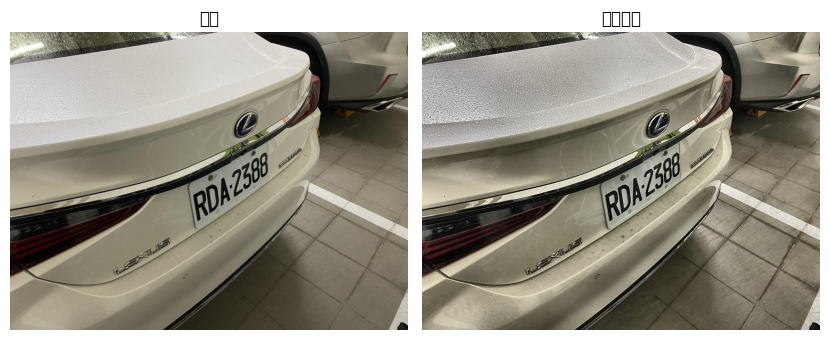

--- ablation（對比 / 邊緣密度）---
全部關閉   std=  59.0  edge= 4.89%
只光照補償  std=  55.5  edge= 9.70%
光照+去噪  std=  54.9  edge= 7.67%
全部開啟   std=  57.1  edge= 9.33%


In [20]:
# --- self test: [PRE-01] ---
_p = pick_sample_image()
if _p:
    _img = load_image(_p)
    _pre = preprocess(_img)

    # 契約檢查：尺寸與 dtype 都不可變
    assert _pre.shape == _img.shape, f'契約破壞：尺寸 {_img.shape} -> {_pre.shape}'
    assert _pre.dtype == np.uint8, f'契約破壞：dtype {_pre.dtype}'

    _g0 = cv2.cvtColor(_img, cv2.COLOR_BGR2GRAY)
    _g1 = cv2.cvtColor(_pre, cv2.COLOR_BGR2GRAY)
    _e0 = (cv2.Canny(_g0, 100, 200) > 0).mean() * 100
    _e1 = (cv2.Canny(_g1, 100, 200) > 0).mean() * 100

    print('測試圖 :', os.path.basename(_p))
    print('shape  :', _img.shape, '->', _pre.shape, '| dtype', _pre.dtype)
    print(f'對比(標準差) {_g0.std():6.1f} -> {_g1.std():6.1f}')
    print(f'邊緣密度     {_e0:6.2f}% -> {_e1:6.2f}%')

    # 顏色是否被推走：用平均 BGR 差衡量（過大代表白/黃底被改色，會影響正反面判斷）
    _shift = np.abs(_pre.astype(np.int16) - _img.astype(np.int16)).mean(axis=(0, 1))
    print('平均 BGR 偏移 ', np.round(_shift, 1), '(過大會影響白底/黃底判斷)')

    save_case('PRE-01', {'01_input': _img, '02_pre': _pre})
    show(_img, _pre, titles=['原圖', '前處理後'], cols=2)

    # ablation：關掉各步驟看差異，報告可直接引用
    print('\n--- ablation（對比 / 邊緣密度）---')
    for _name, _kw in [('全部關閉', dict(compensate=False, denoise=False, sharpen=False)),
                       ('只光照補償', dict(denoise=False, sharpen=False)),
                       ('光照+去噪', dict(sharpen=False)),
                       ('全部開啟', dict())]:
        _v = preprocess(_img, **_kw)
        _vg = cv2.cvtColor(_v, cv2.COLOR_BGR2GRAY)
        print(f'{_name:<6} std={_vg.std():6.1f}  edge={(cv2.Canny(_vg,100,200)>0).mean()*100:5.2f}%')
else:
    print('尚未提供測試圖，略過（或先執行 [D1-02] 匯入影像）')


## §3 車牌定位（LOC-01 / LOC-02）

分成兩步：先**產生候選**（寧可多、不可漏），再**評分篩選**（排序取 top-k）。
最終對外只暴露 `localize()`，回傳 `List[Candidate]`，分數由高到低。

In [21]:
# ==== [LOC-01] 定位：候選產生 ====
# 策略：車牌底色（白 / 黃）色彩模型 → 水平閉運算串成一塊 → 最小外接矩形。
#
# 為什麼強調「水平閉運算」：車牌內部是暗色字元，直接找連通域會被字元切碎成
# 一堆小塊。用寬而扁的核 (21,5) 把同一列的字元縫在一起，才能得到整張車牌。
#
# 為什麼亮度門檻要拉高（而非課本常見的 130）：
# 停車場的淺灰地面在 CLAHE 提亮後落在 v≈150~200，用寬鬆門檻會讓「車牌 + 地面」
# 黏成同一個連通域，minAreaRect 於是框住整片地板。實測 99 張（recall@k）：
#   v>130 → 24%   v>180 → 34%   v>220 → 53.5%   v>250 → 52.5%
# 也就是說車牌是畫面中最亮的區域之一，門檻拉高反而更乾淨。
#
# 但單一門檻永遠會漏：同一批圖在不同門檻下的**命中集合並不相同**。
# 所以這裡改成「門檻階梯」—— 多個門檻各產生一次候選，全部合併後交給 [LOC-02]
# 統一評分。候選不需要準，只需要被包含在裡面（recall@k 才是這裡的指標）。


def plate_color_masks(bgr: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """回傳 (白底遮罩, 黃底遮罩)，皆為 uint8 0/255。

    這是「單一門檻」版，供需要一組遮罩的地方（如 [SEG-01]）使用；
    定位用的多門檻版本是下面的 plate_color_masks_ladder()。
    """
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    white = ((s < LOC_S_WHITE) & (v > LOC_V_WHITE)).astype(np.uint8) * 255

    h0, h1 = LOC_HUE_YELLOW
    yellow = ((h >= h0) & (h <= h1) & (s > LOC_S_YELLOW)
              & (v > LOC_V_WHITE * LOC_V_YELLOW_RATIO)).astype(np.uint8) * 255
    return white, yellow


def plate_color_masks_ladder(bgr: np.ndarray) -> List[Tuple[np.ndarray, str]]:
    """回傳 [(遮罩, 來源標籤), ...]：白底每個亮度門檻一張，黃底一張。

    各階遮罩是**獨立**產生的，不是累積的 —— 高門檻的遮罩是高門檻遮罩的子集，
    累積只會重複產生同一批輪廓。分開跑才能讓低門檻多抓到的暗車牌不被高門檻蓋掉。
    """
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    out: List[Tuple[np.ndarray, str]] = []
    for vt in LOC_V_LADDER:
        m = ((s < LOC_S_WHITE) & (v > vt)).astype(np.uint8) * 255
        out.append((m, f'white{vt}'))

    h0, h1 = LOC_HUE_YELLOW
    y = ((h >= h0) & (h <= h1) & (s > LOC_S_YELLOW)
         & (v > LOC_V_WHITE * LOC_V_YELLOW_RATIO)).astype(np.uint8) * 255
    out.append((y, 'yellow'))
    return out


def quads_from_mask(mask: np.ndarray, polarity: str = '') -> List[Candidate]:
    """把二值遮罩轉成一組四邊形候選。

    只做「形狀合理性」過濾（面積／長寬比／矩形度），**不評分** ——
    評分是 [LOC-02] 的事，這裡寧可多留以免漏掉正解。
    """
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, LOC_CLOSE_K)
    m = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out: List[Candidate] = []
    for c in contours:
        area = cv2.contourArea(c)
        if area < LOC_MIN_AREA:
            continue

        rect = cv2.minAreaRect(c)
        (_, _), (rw, rh), _ = rect
        if rw < LOC_MIN_SIDE or rh < LOC_MIN_SIDE:
            continue

        long_side, short_side = max(rw, rh), min(rw, rh)
        ar = long_side / max(short_side, 1e-6)
        if not (LOC_ASPECT_RANGE[0] <= ar <= LOC_ASPECT_RANGE[1]):
            continue

        fill = area / max(rw * rh, 1e-6)
        if fill < LOC_MIN_RECT_FILL:
            continue

        quad = sort_quad(cv2.boxPoints(rect).astype(np.float32))
        out.append(Candidate(
            quad=quad, score=0.0, source='color',
            meta={'area': float(area), 'w': float(rw), 'h': float(rh),
                  'aspect': float(ar), 'fill': float(fill), 'polarity': polarity},
        ))
    return out


def localize_candidates(img: np.ndarray) -> List[Candidate]:
    """產生所有可能是車牌的四邊形候選（不評分、不篩選）。

    img 應為 preprocess() 後的 BGR 影像（同尺寸）。白色與黃色車牌各跑一次，
    因為兩者的最佳參數不同；合併後由 [LOC-02] 統一評分。
    """
    cands: List[Candidate] = []
    for mask, tag in plate_color_masks_ladder(img):
        cands.extend(quads_from_mask(mask, tag))
    return cands


In [22]:
# ==== [LOC-02] 定位：候選評分與篩選 ====
# 六個特徵 → **同張圖內 min-max 正規化** → 加權求和 → NMS。
#
# 前五個（aspect / area / fill / edge / contrast）只看「候選本身的形狀與亮度」，
# 因此任何一塊又大又亮的東西都能拿高分 —— 實測下巴最容易贏的就是車廠標誌、
# 天花反光、車尾燈反光。第六個特徵「字元列」改成看「候選裡面有沒有字」，
# 這是車牌與其他亮塊最本質的差別：99 張實測 recall@1 30.3% → 48.5%、
# recall@k 47.5% → 57.6%，端到端整牌正確率 26.3% → 38.4%。
#
# 為什麼要「同張圖內正規化」而不是用絕對值：
# 第一版用絕對值時，亮圖裡每個候選的 edge/contrast 都頂到 1.00，等於沒有鑑別力，
# 結果左上角一塊亮天花板就以 area=1.00 排到第一。改成同一張圖內互相比較後，
# 「這張圖裡哪個候選最像車牌」才是真正的問題，跨圖亮度差異也被消掉。


def _roi(gray: np.ndarray, quad: np.ndarray) -> Optional[np.ndarray]:
    """依四邊形裁出灰階 ROI；超出邊界時夾回影像內。"""
    x, y, w, h = cv2.boundingRect(quad.astype(np.int32))
    x, y = max(x, 0), max(y, 0)
    roi = gray[y:y + max(h, 1), x:x + max(w, 1)]
    return roi if roi.size else None


def _char_row_score(gray: np.ndarray, quad: np.ndarray) -> float:
    """把候選四邊形攤平成固定尺寸，數裡面有幾個「像字元」的連通域。

    為什麼要攤平：不攤平就無法用「字元高度佔比」這種與大小無關的判準，
    斜拍的車牌上字元在原始座標裡是歪的，直接量 bounding box 會失真。

    判準（皆為佔攤平尺寸的比例，因此與影像解析度無關）：
      - 高度 30%~95%：太矮是雜點，太高是整片色塊
      - 寬高比 0.12~1.30：涵蓋 1、I、W、M 等各種字寬
      - 面積 ≥ 0.8%：濾掉鉤狀雜訊

    回傳 0~1：數到 LOC_CHAR_MAX 個字元即滿分。
    """
    q = _order_quad_lite(quad)
    dst = np.array([[0, 0], [LOC_CHAR_W - 1, 0],
                    [LOC_CHAR_W - 1, LOC_CHAR_H - 1], [0, LOC_CHAR_H - 1]], np.float32)
    try:
        M = cv2.getPerspectiveTransform(q, dst)
        w = cv2.warpPerspective(gray, M, (LOC_CHAR_W, LOC_CHAR_H),
                                flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    except cv2.error:
        return 0.0
    if w.size == 0:
        return 0.0

    w = cv2.GaussianBlur(w, (3, 3), 0)
    # Otsu 自動分離「字（暗）」與「底（亮）」；車牌一定是淺底深字
    _, bw = cv2.threshold(w, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    n, _lab, st, _ctr = cv2.connectedComponentsWithStats(bw, 8)

    nch = 0
    for i in range(1, n):
        cw, ch = st[i, cv2.CC_STAT_WIDTH], st[i, cv2.CC_STAT_HEIGHT]
        ca = st[i, cv2.CC_STAT_AREA]
        if not (LOC_CHAR_H_RANGE[0] * LOC_CHAR_H <= ch <= LOC_CHAR_H_RANGE[1] * LOC_CHAR_H):
            continue
        if cw < 3 or cw > 0.45 * LOC_CHAR_W:
            continue
        if not (LOC_CHAR_AR_RANGE[0] <= cw / float(ch) <= LOC_CHAR_AR_RANGE[1]):
            continue
        if ca < LOC_CHAR_MIN_AREA_FRAC * LOC_CHAR_W * LOC_CHAR_H:
            continue
        nch += 1
    return min(nch, LOC_CHAR_MAX) / float(LOC_CHAR_MAX)


def _order_quad_lite(q: np.ndarray) -> np.ndarray:
    """把四點排成 左上→右上→右下→左下（不依賴 [GEO-01] 的版本，避免章節倒序）。"""
    q = np.asarray(q, np.float32).reshape(4, 2)
    c = q.mean(axis=0)
    ang = np.arctan2(q[:, 1] - c[1], q[:, 0] - c[0])
    q = q[np.argsort(ang)]
    return np.roll(q, -int(np.argmin(q.sum(axis=1))), axis=0).astype(np.float32)


def _raw_features(cand: Candidate, gray: np.ndarray, img_area: float) -> Dict[str, float]:
    """算出五個未正規化的特徵值。"""
    roi = _roi(gray, cand.quad)
    area = max(cand.meta.get('area', 0.0), 1.0)
    ar = max(cand.meta.get('aspect', 1.0), 1e-6)

    edge = contrast = 0.0
    if roi is not None and roi.size >= 16:
        edge = float((cv2.Canny(roi, 60, 160) > 0).mean())
        contrast = float(roi.std())

    return {
        'aspect':   float(np.exp(-0.5 * (np.log(ar / LOC_AR_BASE) / LOC_AR_SIGMA_LOG) ** 2)),
        'area':     float(np.exp(-0.5 * (np.log(area / img_area / LOC_AREA_FRAC)
                                        / LOC_AREA_SIGMA_LOG) ** 2)),
        'fill':     float(np.clip(cand.meta.get('fill', 0.0), 0.0, 1.0)),
        'edge':     edge,
        'contrast': contrast,
        # 唯一「看裡面」的特徵；其餘五項都只看候選本身的形狀與亮度
        'char':     _char_row_score(gray, cand.quad),
    }


def _minmax(vals: List[float]) -> List[float]:
    """把一組值拉到 0~1。全部相同時回傳 0.5（無鑑別力，不該加分也不該扣分）。"""
    lo, hi = min(vals), max(vals)
    if hi - lo < 1e-9:
        return [0.5] * len(vals)
    return [(v - lo) / (hi - lo) for v in vals]


def score_candidates(cands: List[Candidate], gray: np.ndarray,
                     img_area: float) -> None:
    """就地為整批候選評分（0~1）。"""
    if not cands:
        return
    raws = [_raw_features(c, gray, img_area) for c in cands]
    norm = {k: _minmax([r[k] for r in raws]) for k in raws[0]}

    for i, (c, r) in enumerate(zip(cands, raws)):
        parts = {k: norm[k][i] for k in norm}
        base = float(sum(LOC_SCORE_W[k] * parts[k] for k in LOC_SCORE_W))
        # 貼邊懲罰：車牌幾乎不會緊貼畫面邊界，而天花板／牆角／地板交界常貼邊。
        # 用乘性而非加性，才不會被其他四項的高分抵銷掉。
        touches = _touches_border(c.quad, gray.shape)
        c.meta['parts'] = parts
        c.meta['raw'] = r
        c.meta['border'] = touches
        c.score = base * (1.0 - LOC_BORDER_PENALTY * touches)


def _touches_border(quad: np.ndarray, shape: Tuple[int, int],
                    margin: int = 2) -> float:
    """外包框是否貼著畫面邊界（1.0 = 貼邊）。"""
    h, w = shape[:2]
    x, y, bw, bh = cv2.boundingRect(quad.astype(np.int32))
    hit = (x <= margin) or (y <= margin) or (x + bw >= w - margin) or (y + bh >= h - margin)
    return 1.0 if hit else 0.0


def _iou_quad(a: np.ndarray, b: np.ndarray) -> float:
    """兩個軸對齊外包框的 IoU（候選都是矩形，用外包框已足夠做 NMS）。"""
    ax, ay, aw, ah = cv2.boundingRect(a.astype(np.int32))
    bx, by, bw, bh = cv2.boundingRect(b.astype(np.int32))
    x1, y1 = max(ax, bx), max(ay, by)
    x2, y2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
    iw, ih = max(0, x2 - x1), max(0, y2 - y1)
    inter = iw * ih
    union = aw * ah + bw * bh - inter
    return inter / union if union > 0 else 0.0


def nms(cands: List[Candidate], iou_thr: float = LOC_NMS_IOU) -> List[Candidate]:
    """依分數由高到低保留，壓掉重疊度過高的候選。

    白底與黃底遮罩常常各自框到同一張車牌，不去重會讓 top-k 被同一物件佔滿。
    """
    kept: List[Candidate] = []
    for c in sorted(cands, key=lambda x: x.score, reverse=True):
        if all(_iou_quad(c.quad, k.quad) < iou_thr for k in kept):
            kept.append(c)
    return kept


def localize(img: np.ndarray) -> List[Candidate]:
    """對候選評分並回傳前 TOP_K 個，分數由高到低。

    img 契約與 [LOC-01] 相同：preprocess() 後的 BGR 影像。
    """
    cands = localize_candidates(img)
    if not cands:
        return []

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_area = float(img.shape[0] * img.shape[1])
    score_candidates(cands, gray, img_area)

    return nms(cands)[:TOP_K]


train_IMG_1231_JPG.rf.4427265fe92179f31e → 候選 5 個
  #0 score=0.663 AR=1.17 aspect=0.97 area=0.00 fill=0.00 edge=0.32 contrast=0.93 char=1.00
  #1 score=0.428 AR=0.60 aspect=0.96 area=0.02 fill=0.08 edge=0.76 contrast=0.95 char=0.00
  #2 score=0.296 AR=1.49 aspect=0.77 area=0.00 fill=0.08 edge=0.27 contrast=0.69 char=0.00
  #3 score=0.275 AR=2.91 aspect=0.78 area=0.80 fill=0.91 edge=1.00 contrast=1.00 char=0.00
  #4 score=0.270 AR=1.09 aspect=0.69 area=0.01 fill=0.15 edge=0.18 contrast=0.65 char=0.00
  與 GT 的最佳 IoU = 0.026


/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 20505 (\N{CJK UNIFIED IDEOGRAPH-5019}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 36984 (\N{CJK UNIFIED IDEOGRAPH-9078}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 32005 (\N{CJK UNIFIED IDEOGRAPH-7D05}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20505 (\N{CJK UNIFIED IDEOGRAPH-5019}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPy

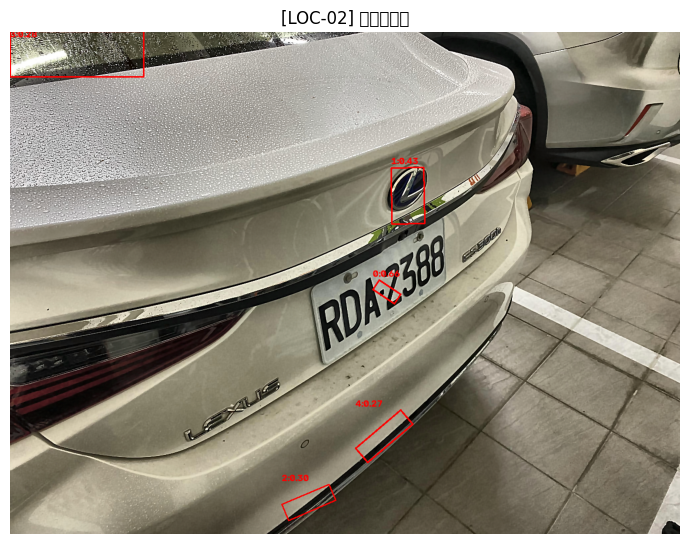

[全資料集] 99 張
  recall@1  (IoU>=0.5) = 51.5%
  recall@k  (IoU>=0.5) = 60.6%   k=5
  平均最佳 IoU = 0.503


In [23]:
# --- self test: [LOC-01] / [LOC-02] ---
# 用真實資料量測，而不是只看一張圖漂不漂亮。

def _gt_box_of(fname: str):
    """從 labels.csv 的 note 取 GT bbox，並換算到 load_image() 之後的座標。"""
    if not os.path.exists(LABELS_CSV):
        return None
    df = load_labels()
    row = df[df['file'].astype(str) == fname]
    if row.empty:
        return None
    b = _parse_bbox(str(row.iloc[0]['note']))
    if b is None:
        return None
    raw = cv2.imread(os.path.join(DATA_DIR, fname))
    if raw is None:
        return None
    oh, ow = raw.shape[:2]
    s = min(1.0, MAX_SIDE / max(oh, ow))
    return tuple(int(v * s) for v in b)


def _iou_xywh(a, b) -> float:
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    x1, y1 = max(ax, bx), max(ay, by)
    x2, y2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
    iw, ih = max(0, x2 - x1), max(0, y2 - y1)
    inter = iw * ih
    union = aw * ah + bw * bh - inter
    return inter / union if union > 0 else 0.0


# ---- (1) 單張：看候選與分數 ----
_p = pick_sample_image()
if _p:
    _img = preprocess(load_image(_p))
    _cands = localize(_img)
    print(f'{os.path.basename(_p)[:40]} → 候選 {len(_cands)} 個')
    for _i, _c in enumerate(_cands):
        _pt = _c.meta.get('parts', {})
        _detail = ' '.join(f'{k}={v:.2f}' for k, v in _pt.items())
        print(f'  #{_i} score={_c.score:.3f} AR={_c.aspect:.2f} {_detail}')
    _gt = _gt_box_of(os.path.basename(_p))
    if _gt:
        _best = max((_iou_xywh(_c.bbox, _gt) for _c in _cands), default=0.0)
        print(f'  與 GT 的最佳 IoU = {_best:.3f}')
    show(draw_candidates(_img, _cands), titles=['[LOC-02] 候選（紅）'], cols=1, size=7)

# ---- (2) 全資料集：recall@1 / recall@k ----
if os.path.exists(LABELS_CSV):
    _df = load_labels()
    _df = _df[_is_labelled(_df) & ~_df['difficulty'].isin(UNSCORABLE_DIFFICULTIES)]
    _files = _df['file'].astype(str).tolist()
    _hit1 = _hit5 = _n = 0
    _ious = []
    for _f in _files:
        _path = os.path.join(DATA_DIR, _f)
        _gt = _gt_box_of(_f)
        if _gt is None or not os.path.exists(_path):
            continue
        _c = localize(preprocess(load_image(_path)))
        _ious.append(max((_iou_xywh(x.bbox, _gt) for x in _c), default=0.0))
        if _c and _iou_xywh(_c[0].bbox, _gt) >= 0.5:
            _hit1 += 1
        if any(_iou_xywh(x.bbox, _gt) >= 0.5 for x in _c):
            _hit5 += 1
        _n += 1
    if _n:
        print(f'\n[全資料集] {_n} 張')
        print(f'  recall@1  (IoU>=0.5) = {_hit1 / _n:.1%}')
        print(f'  recall@k  (IoU>=0.5) = {_hit5 / _n:.1%}   k={TOP_K}')
        print(f'  平均最佳 IoU = {np.mean(_ious):.3f}')
else:
    print('尚未建立 labels.csv，跳過資料集量測')


## §4 車牌擷取（SEG-01）

以定位給的 `quad` 為基礎，精修邊界並產生車牌區域遮罩。
**契約**：`segment(img, quad)` → `(plate_bgr, mask_uint8)`；輸入為**原始影像**，不是前處理後的圖。

與 `[LOC-01]`/`[LOC-02]` 的差別：定位只回答「車牌大概在哪」，`quad` 通常比車牌實際
邊界大一圈（會吃到車身、保險槓、地面）。擷取這一步負責把範圍收緊到車牌本身，
並用 mask 明確標出「哪些像素是真的車牌」—— 後續 `[GEO-01]` 與 B 線的
`binarize()` 都依賴這個 mask，而不是依賴矩形邊界。


In [24]:
# ==== [SEG-01] 擷取：由四邊形取出車牌區域 ====
# 定位給的 quad 會比車牌實際邊界大一圈，這裡往內收並用顏色驗證，再把結果裁緊。
SEG_SHRINK    = 0.06   # 四邊形往內縮的比例（去掉車牌外框線）
SEG_MARGIN    = 0.06   # 裁切時往外留的邊，避免縮框後切掉車牌邊角
SEG_MIN_KEEP  = 0.25   # 顏色驗證後至少保留原多邊形面積的比例，太低就退回多邊形
SEG_CLOSE_K   = (15, 5)  # 水平方向閉運算，把字元間隙縫成整塊車牌底

SEG_LAST_QUAD: Optional[np.ndarray] = None   # 最近一次 segment() 精修後的四邊形（裁切後小圖座標）
SEG_LAST_BOX:  Tuple[int, int] = (0, 0)       # 該小圖左上角在原圖的位置，用來換算回原圖座標


def _shrink_quad(q: np.ndarray, ratio: float) -> np.ndarray:
    """把四邊形往中心等比收縮，用來去掉車牌外框線與定位框的鬆弛。"""
    c = q.mean(axis=0)
    return ((q - c) * (1.0 - ratio) + c).astype(np.float32)


def segment(img: np.ndarray, quad: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """依四點取出車牌區域，並產生「哪裡真的是車牌」的遮罩。

    步驟：
      1. 四邊形往內縮 SEG_SHRINK，去掉外框線
      2. 依縮後四邊形的外接矩形裁切（含 SEG_MARGIN 邊界）
      3. 用 fillPoly 產生四邊形遮罩（保底：顏色驗證失敗時就用這個）
      4. 用 plate_color_masks() 找白底／黃底區域，與四邊形取交集
      5. 水平閉運算把字元間隙縫起來，只留最大連通域（排除旁邊的白色車身）
      6. 若顏色結果小於原面積的 SEG_MIN_KEEP，視為驗證失敗，退回四邊形遮罩
      7. 依遮罩實際範圍把影像裁緊

    Args:
        img : 原始影像（不是 preprocess 後的圖）
        quad: (4,2) 車牌四邊形
    Returns:
        plate_bgr: 裁緊後的車牌區域（尚未校正透視）
        mask_uint8: 同尺寸遮罩，255 = 車牌像素、0 = 車牌以外

    副作用：把精修後的實際四邊形記到 SEG_LAST_QUAD（**裁切後小圖座標**），
    並把該小圖左上角在原圖的位置記到 SEG_LAST_BOX —— 兩者相加就能換算回原圖座標，
    可視化時才畫得出「seg 實際用了哪個四邊形」。
    """
    global SEG_LAST_QUAD, SEG_LAST_BOX

    q = sort_quad(np.asarray(quad, np.float32).reshape(4, 2))
    H, W = img.shape[:2]
    qs = _shrink_quad(q, SEG_SHRINK)

    bw = float(qs[:, 0].max() - qs[:, 0].min())
    bh = float(qs[:, 1].max() - qs[:, 1].min())
    x0 = max(0, int(np.floor(qs[:, 0].min() - SEG_MARGIN * bw)))
    x1 = min(W, int(np.ceil(qs[:, 0].max() + SEG_MARGIN * bw)) + 1)
    y0 = max(0, int(np.floor(qs[:, 1].min() - SEG_MARGIN * bh)))
    y1 = min(H, int(np.ceil(qs[:, 1].max() + SEG_MARGIN * bh)) + 1)
    if x1 - x0 < 4 or y1 - y0 < 4:
        SEG_LAST_QUAD = q
        SEG_LAST_BOX = (0, 0)
        return (np.zeros((1, 1, img.shape[2] if img.ndim == 3 else 1), np.uint8),
                np.zeros((1, 1), np.uint8))
    crop = img[y0:y1, x0:x1]

    poly = (qs - np.array([x0, y0], np.float32)).astype(np.int32)
    poly_mask = np.zeros(crop.shape[:2], np.uint8)
    cv2.fillPoly(poly_mask, [poly], 255)
    poly_area = float((poly_mask > 0).sum())

    white, yellow = plate_color_masks(crop)
    color = cv2.bitwise_and(cv2.bitwise_or(white, yellow), poly_mask)
    color = cv2.morphologyEx(color, cv2.MORPH_CLOSE,
                             cv2.getStructuringElement(cv2.MORPH_RECT, SEG_CLOSE_K))

    mask = poly_mask
    n, lab, stats, _ = cv2.connectedComponentsWithStats((color > 0).astype(np.uint8), 8)
    if n > 1:
        biggest = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
        cand = cv2.bitwise_and(((lab == biggest).astype(np.uint8) * 255), poly_mask)
        # 顏色驗證只留得下碎片時，代表底色判斷失準（陰影、反光），退回四邊形遮罩
        if float((cand > 0).sum()) >= SEG_MIN_KEEP * poly_area:
            mask = cand

    ys, xs = np.where(mask > 0)
    if len(ys):
        ty0, ty1 = max(0, int(ys.min()) - 1), min(mask.shape[0], int(ys.max()) + 2)
        tx0, tx1 = max(0, int(xs.min()) - 1), min(mask.shape[1], int(xs.max()) + 2)
        mask, crop = mask[ty0:ty1, tx0:tx1], crop[ty0:ty1, tx0:tx1]
        SEG_LAST_QUAD = (qs - np.array([x0 + tx0, y0 + ty0], np.float32)).astype(np.float32)
        SEG_LAST_BOX = (x0 + tx0, y0 + ty0)
    else:
        SEG_LAST_QUAD = qs
        SEG_LAST_BOX = (x0, y0)

    return crop, mask


選擇候選：score=0.663 bbox=(693, 475, 54, 46)
plate=(44, 52, 3)  mask=(44, 52)  遮罩填充率=0.41
精修後四邊形面積 / 原 quad 面積 = 0.88
與 GT 的 IoU = 0.026（未命中，屬預期）


/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 22294 (\N{CJK UNIFIED IDEOGRAPH-5716}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 25847 (\N{CJK UNIFIED IDEOGRAPH-64F7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 21462 (\N{CJK UNIFIED IDEOGRAPH-53D6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 35009 (\N{CJK UNIFIED IDEOGRAPH-88C1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 32202 (\N{CJK UNIFIED IDEOGRAPH-7DCA}) missi

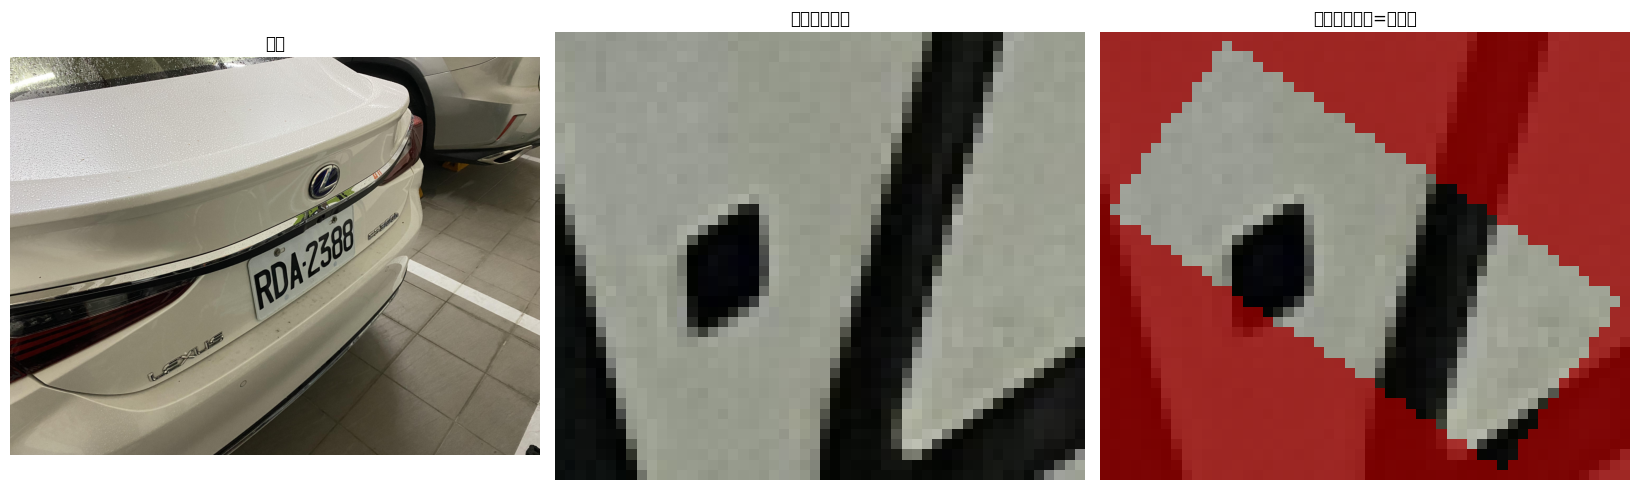

全量檢查：100 張有輸出（0 張無影像或無候選），其中 100 張 (100%) 的遮罩小於整張矩形
對照：舊版 segment() 回傳全 255 遮罩，這一欄永遠是 0%


In [25]:
# --- self test: [SEG-01] ---
# 用 [LOC-02] 的 top-1 候選實際取一次，而不是等手動指定 TEST_IMG。
_p = pick_sample_image()
if _p:
    _img = load_image(_p)
    _cands = localize(preprocess(_img))
    if not _cands:
        print('沒有候選（[LOC-02] 未命中），略過')
    else:
        _best = _cands[0]
        _plate, _mask = segment(_img, _best.quad)
        _fill = float((_mask > 0).mean())
        print(f'選擇候選：score={_best.score:.3f} bbox={_best.bbox}')
        print(f'plate={_plate.shape}  mask={_mask.shape}  遮罩填充率={_fill:.2f}')
        print(f'精修後四邊形面積 / 原 quad 面積 = '
              f'{cv2.contourArea(SEG_LAST_QUAD) / max(cv2.contourArea(sort_quad(_best.quad)), 1):.2f}')
        _gt = _gt_box_of(os.path.basename(_p)) if "_gt_box_of" in globals() else None
        if _gt:
            _iou = _iou_xywh(_best.bbox, _gt)
            print(f'與 GT 的 IoU = {_iou:.3f}' + ('（命中）' if _iou >= 0.5 else '（未命中，屬預期）'))
        _over = _plate.copy()
        _over[_mask == 0] = (_over[_mask == 0] * 0.25 + np.array([0, 0, 160]) * 0.75).astype(np.uint8)
        show(_img, _plate, _over, titles=['原圖', '擷取（裁緊）', '遮罩套用（紅=排除）'],
             cols=3, size=5.5)
else:
    print('data/images 沒有影像，略過')

# 全量 sanity check：確認沒有空輸出，且遮罩多半真的比整張矩形小（代表 tight crop 生效）
if os.path.exists(LABELS_CSV):
    _lab_seg = load_labels()
    _ok = _tight = _skip = 0
    for _fn in _lab_seg['file'].astype(str):
        _pp = os.path.join(DATA_DIR, _fn)
        if not os.path.exists(_pp):
            _skip += 1
            continue
        _im = load_image(_pp)
        _cs = localize(preprocess(_im))
        if not _cs:
            _skip += 1
            continue
        _pl, _mk = segment(_im, _cs[0].quad)
        if _pl.size == 0 or _mk.size == 0:
            continue
        _ok += 1
        if float((_mk > 0).mean()) < 0.99:
            _tight += 1
    print(f'全量檢查：{_ok} 張有輸出（{_skip} 張無影像或無候選），'
          f'其中 {_tight} 張 ({_tight / max(_ok, 1) * 100:.0f}%) 的遮罩小於整張矩形')
    print('對照：舊版 segment() 回傳全 255 遮罩，這一欄永遠是 0%')
else:
    print('尚未建立 labels.csv，跳過全量檢查')


## §5 幾何校正（GEO-01）

把車牌校正成正視圖，輸出尺寸固定為 `PLATE_W × PLATE_H`（定義在 `[S0-2]`）。

**契約**：`rectify(plate_bgr, mask)` → `(upright_bgr, upright_mask)`。

`[SEG-01]` 交出的是「裁著透視畸變的車牌」，不是正視圖。直接 `cv2.resize` 只會把斜拍的車牌壓成 480×140，字仍然是斜的且被剪切變形 —— 而 B 線的切字窗假設字元垂直。

本節用**遮罩自己**估四邊形，而不依賴 `SEG_LAST_QUAD`：

| 來源 | 問題 |
|---|---|
| `SEG_LAST_QUAD` | 它是**原圖座標**，但 `rectify()` 拿到的已經是裁切後的小圖，偏移量在契約外流失 |
| `mask` | 它就在同一張小圖上，255 = 真實車牌像素，且已經過 `[SEG-01]` 的顏色驗證 |

### 為什麼不是 `cv2.minAreaRect`

`minAreaRect` 回傳的是**最小外接旋轉矩形**，數學上恆為平行四邊形 —— 它的對邊夾角差**永遠是 0°**。但相機斜拍車牌時，四邊形本質上是**梯形**（近端邊長、遠端邊短），用平行四邊形去貼只能貼到兩條對邊，另外兩條必然內縮或外擴。

實測（對邊角度差，0° = 平行四邊形）：

| 車牌 | `minAreaRect` | `approxPolyDP` |
|---|---|---|
| YG6805 | 上下 0.0° / 左右 0.0° | 上下 4.6° / 左右 1.8° |
| US529 | 上下 0.0° / 左右 0.0° | 上下 10.1° / 左右 2.1° |

### 為什麼也不是直接用 `approxPolyDP`

`approxPolyDP` 忠實貼合遮罩輪廓，也就一併貼合了遮罩的**鋸齒邊界**。逐張比對發現：改用純 `approxPolyDP` 後整牌正確率是 **23.2% → 23.2%，淨值零**（修好 2 張、弄壞 2 張）—— 修好的是真的斜拍，弄壞的是原本軸對齊、被鋸齒帶歪的。幾何更「真」不等於 OCR 更準。

### 本節做法：近似四邊形當種子 → 對四條邊各別做直線擬合

1. `approxPolyDP` 掃一組 `eps`（0.02–0.10 倍周長），取第一個能收斂成 **凸四邊形**且面積 ≥ 80% 輪廓面積的結果，作為**種子四邊形**。
2. 用種子的四條邊各圈出一條**邊帶**（容差 = 短邊的 6%），收集落在帶內的輪廓點。
3. 對每條邊帶的點用 `cv2.fitLine`（`DIST_HUBER`，抗離群）擬合直線。
4. 相鄰兩條直線求交點 → 得到四個角。

這樣既保留了梯形的自由度（`minAreaRect` 做不到），又用「一整條邊的所有點」壓掉了單點的鋸齒抖動（純 `approxPolyDP` 的弱點）。

**守門（不改善就不動手）**：
- 擬合出來的梯形程度太小（對邊角度差 < `GEO_PARA_DEG` = 2°）→ 沒有真正的透視畸變，直接用 `minAreaRect`，避免為雜訊而扭曲影像。
- 擬合失敗、退化、長寬比不合理 → 退回 `minAreaRect`。
- `minAreaRect` 也失敗 → 退回 `cv2.resize`。

寧可不改善，也不能用一個亂估的四點把字拉得更歪。

遮罩用 `INTER_NEAREST` 一起變換，不讓插值製造出「半透明的車牌像素」。

In [26]:
# ==== [GEO-01] 幾何校正：透視變換到固定尺寸 ====
# 由遮罩自己估四邊形，而不依賴 SEG_LAST_QUAD —— 後者是原圖座標，
# 但 rectify() 拿到的已經是裁切後的小圖，偏移量在契約外流失。

GEO_MIN_MASK_AREA = 0.15       # 遮罩有效區佔比低於此 → 估角不可信，退回等比縮放
GEO_AR_RANGE      = (1.8, 6.0) # 估出的長寬比合理範圍（香港車牌 480/140 ≈ 3.43；跨境牌更長）
GEO_MIN_SIDE      = 4.0        # 四邊形短邊下限（像素），太小代表遮罩碎掉了

# approxPolyDP 的候選容差（占輪廓周長比例）。小的先試，越接近原輪廓越優先。
GEO_AP_EPS        = (0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10)
GEO_MIN_POLY_FILL = 0.80       # 近似四邊形面積 / 輪廓面積 的下限，太低代表漏掉一大塊
GEO_FIT_TOL       = 0.06       # 邊帶容差（占該邊長比例），用來收集擬合用的輪廓點
GEO_PARA_DEG      = 2.0        # 對邊角度差小於此值 → 視為無明顯梯形，改用 minAreaRect


def _order_quad(q: np.ndarray) -> np.ndarray:
    """把四個點排成 左上→右上→右下→左下。

    不直接用 `sort_quad`：它靠 x+y / x-y 分象限，在**接近軸對齊**的四邊形上
    分數會並列而排錯順序（產生蝴蝶結），實測曾導致對邊角度差算成 178°。
    這裡改用「相對質心的極角」排序，對任意凸四邊形都穩定。
    """
    q = np.asarray(q, np.float32).reshape(4, 2)
    c = q.mean(axis=0)
    ang = np.arctan2(q[:, 1] - c[1], q[:, 0] - c[0])   # y 軸向下 → 極角遞增即順時針
    q = q[np.argsort(ang)]
    # 旋轉使「左上」在最前：x+y 最小者
    return np.roll(q, -int(np.argmin(q.sum(axis=1))), axis=0).astype(np.float32)


def _opposite_angle_diff(q: np.ndarray) -> Tuple[float, float]:
    """四邊形兩組對邊的夾角差（度）。(上下, 左右)；平行四邊形為 0°。"""
    q = np.asarray(q, np.float32).reshape(4, 2)

    def _dir(a, b):
        v = b - a
        return float(np.degrees(np.arctan2(v[1], v[0])) % 180.0)

    def _diff(a, b):
        d = abs(a - b)
        return min(d, 180.0 - d)

    return (_diff(_dir(q[0], q[1]), _dir(q[3], q[2])),
            _diff(_dir(q[1], q[2]), _dir(q[0], q[3])))


def _quad_valid(q: np.ndarray, area: float) -> bool:
    """四邊形是否可用：凸、非退化、面積夠、長寬比合理。"""
    q = np.asarray(q, np.float32)
    if not np.all(np.isfinite(q)):
        return False
    qi = q.reshape(-1, 1, 2).astype(np.int32)
    if not cv2.isContourConvex(qi):
        return False
    if abs(cv2.contourArea(qi)) < GEO_MIN_POLY_FILL * area:
        return False
    w = float(np.linalg.norm(q[1] - q[0]))
    h = float(np.linalg.norm(q[2] - q[1]))
    if min(w, h) < GEO_MIN_SIDE:
        return False
    return GEO_AR_RANGE[0] <= max(w, h) / max(min(w, h), 1e-6) <= GEO_AR_RANGE[1]


def _fit_line(pts: np.ndarray, p0: np.ndarray, p1: np.ndarray) -> Optional[np.ndarray]:
    """收集靠近 p0→p1 線段的輪廓點並擬合直線，回傳 (a, b, c) 使 ax+by+c=0。"""
    v = p1 - p0
    L = float(np.linalg.norm(v))
    if L < 1e-6:
        return None
    u = v / L
    n = np.array([-u[1], u[0]], np.float32)
    rel = pts - p0
    dist = np.abs(rel @ n)
    t = rel @ u
    band = max(GEO_FIT_TOL * L, 1.5)
    sel = (dist <= band) & (t >= -0.05 * L) & (t <= 1.05 * L)
    if int(sel.sum()) < 6:
        return None
    vx, vy, x0, y0 = cv2.fitLine(pts[sel].reshape(-1, 1, 2), cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
    return np.array([-vy, vx, vy * x0 - vx * y0], np.float64)


def _line_intersect(l1: np.ndarray, l2: np.ndarray) -> Optional[np.ndarray]:
    """兩條 (a, b, c) 直線的交點；近平行則回傳 None。"""
    a1, b1, c1 = l1
    a2, b2, c2 = l2
    d = a1 * b2 - a2 * b1
    if abs(d) < 1e-9:
        return None
    return np.array([(b1 * c2 - b2 * c1) / d, (a2 * c1 - a1 * c2) / d], np.float32)


def _quad_from_mask(mask: np.ndarray,
                    shape: Tuple[int, int]) -> Tuple[Optional[np.ndarray], str]:
    """由遮罩估出車牌四邊形（左上→右上→右下→左下）。

    三段式，由「最貼合」退到「最保守」：
      1. 邊線擬合 —— 允許梯形，用整條邊的點壓掉鋸齒抖動
      2. minAreaRect —— 平行四邊形，只在上面的擬合失敗或梯形程度可有可無時使用
      3. None —— 由上層退回等比縮放

    Returns:
        (quad, how)：quad 為 (4, 2) float32 或 None；how 說明走了哪條路徑，
        供 self test 統計（'fit' / 'fit-invalid' / 'rect' / 'rect-nopara' / ...）。
    """
    m = (mask > 0).astype(np.uint8) * 255
    if m.shape != tuple(shape[:2]):
        m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)

    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None, 'no-contour'
    c = max(contours, key=cv2.contourArea)
    area = float(cv2.contourArea(c))
    if area < GEO_MIN_MASK_AREA * shape[0] * shape[1]:
        return None, 'small-area'

    # --- 第 2 段的結果先算好：既是擬合的備援，也是「無明顯梯形」時的答案 ---
    rect = cv2.minAreaRect(c)
    rw, rh = rect[1]
    quad_rect = None
    if min(rw, rh) >= GEO_MIN_SIDE and        GEO_AR_RANGE[0] <= max(rw, rh) / max(min(rw, rh), 1e-6) <= GEO_AR_RANGE[1]:
        quad_rect = _order_quad(cv2.boxPoints(rect))

    # --- 第 1 段：approxPolyDP 找出種子四邊形，再逐邊擬合 ---
    peri = cv2.arcLength(c, True)
    seed = None
    for eps in GEO_AP_EPS:
        ap = cv2.approxPolyDP(c, eps * peri, True)
        if len(ap) != 4:
            continue
        cand = _order_quad(ap.reshape(4, 2))
        if _quad_valid(cand, area):
            seed = cand
            break

    how = 'no-seed'
    if seed is not None:
        pts = c.reshape(-1, 2).astype(np.float32)
        lines = [_fit_line(pts, seed[i], seed[(i + 1) % 4]) for i in range(4)]
        if any(L is None for L in lines):
            how = 'fit-fail'
        else:
            corners = []
            for i in range(4):
                p = _line_intersect(lines[(i - 1) % 4], lines[i])
                if p is None:
                    corners = None
                    break
                corners.append(p)
            if corners is None:
                how = 'fit-fail'
            else:
                q = _order_quad(np.array(corners, np.float32))
                if not _quad_valid(q, area):
                    how = 'fit-invalid'
                else:
                    dt, dl = _opposite_angle_diff(q)
                    if max(dt, dl) < GEO_PARA_DEG:
                        # 擬合出來的梯形程度可有可無 → 不值得為雜訊扭曲影像
                        return (quad_rect, 'rect-nopara' if quad_rect is not None else 'reject')
                    return q, 'fit'

    return (quad_rect, 'rect' if quad_rect is not None else 'reject')


def rectify(plate_bgr: np.ndarray, mask: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """校正透視變形，輸出 PLATE_W × PLATE_H 的正視車牌。

    這一步的輸出是 B 線 OCR 的唯一輸入，尺寸與極性都必須穩定。

    Args:
        plate_bgr: `[SEG-01]` 裁切後的車牌區域（尚未校正）
        mask     : 同尺寸遮罩，255 = 車牌像素、0 = 車牌以外
    Returns:
        upright_bgr : (PLATE_H, PLATE_W, 3) 正視車牌
        upright_mask: (PLATE_H, PLATE_W) 對應的有效區遮罩

    後備：四點估不出來時退回等比縮放（尺寸契約仍然成立，只是沒改善斜拍）。
    """
    if plate_bgr is None or getattr(plate_bgr, 'size', 0) == 0:
        return (np.zeros((PLATE_H, PLATE_W, 3), np.uint8),
                np.zeros((PLATE_H, PLATE_W), np.uint8))

    if mask is None or getattr(mask, 'size', 0) == 0:
        mask = np.full(plate_bgr.shape[:2], 255, np.uint8)

    quad, _how = _quad_from_mask(mask, plate_bgr.shape)
    if quad is None:
        up = cv2.resize(plate_bgr, (PLATE_W, PLATE_H), interpolation=cv2.INTER_LINEAR)
        up_mask = cv2.resize(mask, (PLATE_W, PLATE_H), interpolation=cv2.INTER_NEAREST)
        return up, up_mask

    dst = np.array([[0, 0], [PLATE_W - 1, 0],
                    [PLATE_W - 1, PLATE_H - 1], [0, PLATE_H - 1]], np.float32)
    M = cv2.getPerspectiveTransform(np.asarray(quad, np.float32), dst)

    up = cv2.warpPerspective(plate_bgr, M, (PLATE_W, PLATE_H),
                             flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    up_mask = cv2.warpPerspective(mask, M, (PLATE_W, PLATE_H),
                                  flags=cv2.INTER_NEAREST, borderValue=0)
    return up, up_mask

全量：100 張有效輸入
  尺寸契約通過 100/100
  走透視校正 84 張，回退等比縮放 16 張（回退行為同舊版）
  四點來源：rect 30、fit 28、rect-nopara 26、reject 15、small-area 1
  矯正前傾角 |median| 7.5°  p90 28.7°
  有校正的 84 張：平均傾角 12.1° → 0.0°
  其中走邊線擬合的 28 張 —— 這是 minAreaRect 表達不到的梯形自由度

最斜的範例：train_IMG_5165_jpg.rf.bad633e2a7e80844aa471b
  傾角 +41.8° → +0.0°；有效區 0.31 → 0.97


/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 25847 (\N{CJK UNIFIED IDEOGRAPH-64F7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 21462 (\N{CJK UNIFIED IDEOGRAPH-53D6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 26410 (\N{CJK UNIFIED IDEOGRAPH-672A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 26657 (\N{CJK UNIFIED IDEOGRAPH-6821}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) miss

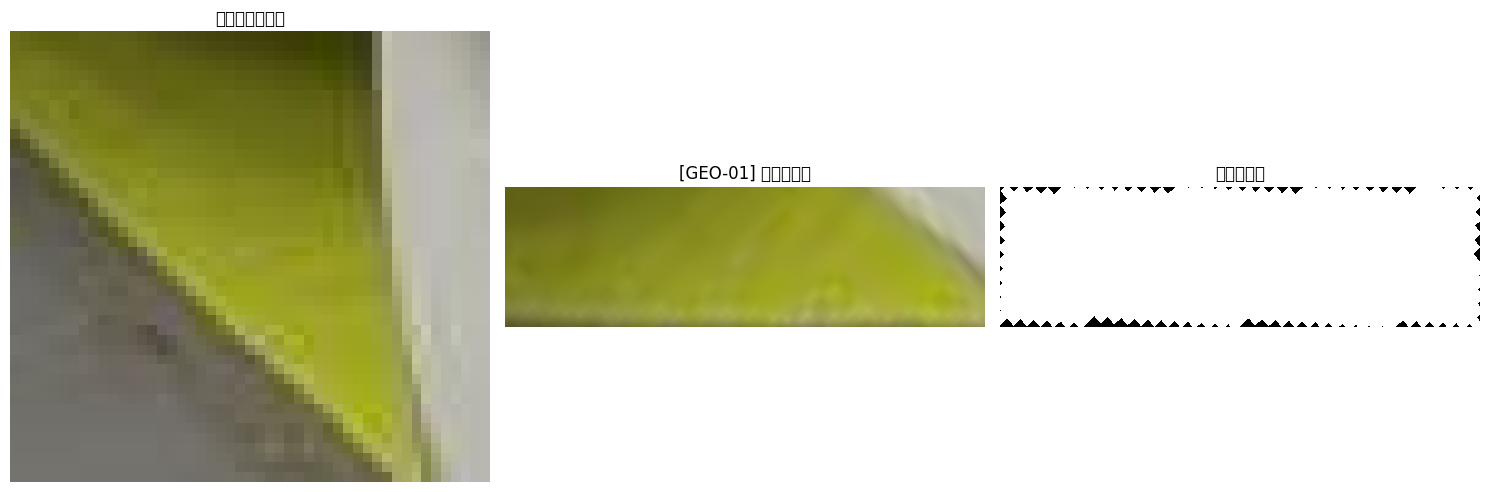

In [27]:
# --- self test: [GEO-01] ---
# 量兩件事：(1) 尺寸契約是否永遠成立；(2) 斜拍的車牌是否真的被拉正。
# 範例不抽隨機一張 —— 抽到正的就看不出效果，所以直接挑傾角最大的一張。
def _mask_tilt(m: np.ndarray) -> float:
    """遮罩最大連通域的傾角（度）。0 代表水平。"""
    cs, _ = cv2.findContours((m > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cs:
        return 0.0
    (_x, _y), (w, h), a = cv2.minAreaRect(max(cs, key=cv2.contourArea))
    if w < h:
        a += 90
    # minAreaRect 的角度值域是 (-90, 0]，先正規化到 (-45, 45] 才看得出實際傾斜
    return float(((a + 45) % 90) - 45)


def _geo_sweep(limit: Optional[int] = None) -> pd.DataFrame:
    """對所有有標註的影像跑 segment + rectify，回傳每張的尺寸契約與傾角。"""
    rows = []
    if not os.path.exists(LABELS_CSV):
        return pd.DataFrame(rows)
    files = load_labels()['file'].astype(str).tolist()
    for fn in (files[:limit] if limit else files):
        p = os.path.join(DATA_DIR, fn)
        if not os.path.exists(p):
            continue
        img = load_image(p)
        cands = localize(preprocess(img))
        if not cands:
            continue
        plate, mask = segment(img, cands[0].quad)
        up, up_mask = rectify(plate, mask)
        _q, _kind = _quad_from_mask(mask, plate.shape)
        rows.append({'file': fn, 'ok': up.shape == (PLATE_H, PLATE_W, 3)
                     and up_mask.shape == (PLATE_H, PLATE_W) and up.mean() > 5,
                     'warped': _q is not None, 'kind': _kind,
                     'tilt': _mask_tilt(mask), 'tilt_after': _mask_tilt(up_mask)})
    return pd.DataFrame(rows)


_sw = _geo_sweep()
if _sw.empty:
    print('data/images 沒有影像，略過')
else:
    print(f'全量：{len(_sw)} 張有效輸入')
    print(f'  尺寸契約通過 {int(_sw["ok"].sum())}/{len(_sw)}')
    print(f'  走透視校正 {int(_sw["warped"].sum())} 張，回退等比縮放 {int((_sw["warped"] == 0).sum())} 張（回退行為同舊版）')
    _k = _sw['kind'].value_counts()
    print('  四點來源：' + '、'.join(f'{k} {v}' for k, v in _k.items()))
    print(f'  矯正前傾角 |median| {_sw["tilt"].abs().median():.1f}°  p90 {_sw["tilt"].abs().quantile(0.9):.1f}°')
    _w = _sw[_sw['warped']]
    print(f'  有校正的 {len(_w)} 張：平均傾角 {_w["tilt"].abs().mean():.1f}° → {_w["tilt_after"].abs().mean():.1f}°')
    # 梯形程度：對邊角度差。0 = 平行四邊形（minAreaRect 的極限），越大代表越像梯形
    _fit = _sw[_sw['kind'] == 'fit']
    if len(_fit):
        print(f'  其中走邊線擬合的 {len(_fit)} 張 —— 這是 minAreaRect 表達不到的梯形自由度')

    # 挑傾斜最嚴重的一張做目視對比
    _warped = _sw[_sw['warped']].copy()
    _warped['abs_tilt'] = _warped['tilt'].abs()
    if len(_warped):
        _fn = _warped.sort_values('abs_tilt', ascending=False).iloc[0]['file']
        _img = load_image(os.path.join(DATA_DIR, _fn))
        _plate, _mask = segment(_img, localize(preprocess(_img))[0].quad)
        _up, _up_mask = rectify(_plate, _mask)
        print(f'\n最斜的範例：{_fn[:44]}')
        print(f'  傾角 {_mask_tilt(_mask):+.1f}° → {_mask_tilt(_up_mask):+.1f}°；'
              f'有效區 {float((_mask > 0).mean()):.2f} → {float((_up_mask > 0).mean()):.2f}')
        show(_plate, _up, _up_mask,
             titles=['擷取（未校正）', '[GEO-01] 透視校正後', '有效區遮罩'],
             cols=3, size=5)


## §5.5 整合（A 段｜`INT-01`）：A 線全流程與中間狀態輸出

> **§8 整合已拆為兩段。** 完整整合章節 = 本節（A 段，A 線出口）＋ §8（B 段，B 線入口）。
>
> 拆開是因為兩人可以並行：A 段跑完把中間狀態寫成**檔案**，B 段不必等 A 段的程式完成，
> 只要讀檔案就能開發與測試，也不需要同一個 kernel、同一台機器。
> 本節放在 A 線末尾而非 §8，是為了讓程式碼與它所屬的章節（§1–§5）連續，避免閱讀時跳號。

把前處理 → 定位 → 擷取 → 校正串成 `run_frontend()`，並由 `export_frontend()`
把每個階段的中間圖寫到 `shared/stages/`。

**契約**：`run_frontend(img, quad=None)` → `{'ok', 'reason', 'stages', 'quad'}`

**交接檔名**（B 段靠這個 glob，來源見 `[S0-2]` 的 `STAGE_DIR`）：

| 檔案 | 內容 |
|---|---|
| `<stem>_03_localize.png` | 候選四邊形畫在原圖上（除錯用） |
| `<stem>_04_segment.png` | 定位後擷取的車牌區域（尚未校正透視） |
| `<stem>_05_rectify.png` | 校正後的正視車牌，固定 `480 × 140` ← **B 段的輸入** |
| `<stem>_05_rectify_mask.png` | 同尺寸遮罩，255 = 車牌像素 |

`<stem>` = 原圖檔名去掉副檔名，因此與 `labels.csv` 的 `file` 欄對得上。
定位失敗的影像**不會**產生 `_05_rectify.png`，B 段掃描時會自動跳過。


In [28]:
# ==== [INT-01] A 段整合：定位 → 擷取 → 校正，輸出中間狀態圖 ====
# §8 整合的前半段。出口是「檔案」而不是函式回傳值，
# 因為 B 段可能在不同時間、不同機器（甚至 Colab）執行。
STAGE_SEGMENT = '04_segment'
STAGE_RECTIFY = '05_rectify'
STAGE_MASK    = '05_rectify_mask'
# 只把 B 段真正需要的階段寫到磁碟：01~03 是定位除錯用的大圖，
# 留著會讓 shared/stages/ 爆量（每張 2 MB），B 段也用不到。
EXPORT_STAGES = (STAGE_SEGMENT, STAGE_RECTIFY, STAGE_MASK)


def _gt_quad_from_label(fname: str) -> Optional[np.ndarray]:
    """示範模式用：把 labels.csv 的 GT bbox 當成定位結果，回傳四邊形。

    ⚠️ 只在 [LOC-01] 尚未實作、需要先驗證 A→B 交接機制時使用。
    正常流程不可傳這個 —— 那等於用答案做題，報告的準確率不能引用。
    """
    if not fname or not os.path.exists(LABELS_CSV):
        return None
    df = load_labels()
    row = df[df['file'].astype(str) == fname]
    if row.empty:
        return None
    m = re.search(r'bbox=(-?\d+),(-?\d+),(\d+),(\d+)', str(row.iloc[0]['note']))
    if not m:
        return None
    x, y, w, h = (int(v) for v in m.groups())
    return sort_quad(np.array([[x, y], [x + w, y], [x + w, y + h], [x, y + h]], np.float32))


def _image_size(path: str) -> Tuple[int, int]:
    """只讀檔頭取得 (寬, 高)，不解碼整張圖 —— 用來換算 bbox 座標空間。"""
    try:
        from PIL import Image
        with Image.open(path) as im:
            return im.size
    except Exception:
        raw = cv2.imread(path)
        return (0, 0) if raw is None else (raw.shape[1], raw.shape[0])


def run_frontend(img: np.ndarray, quad: Optional[np.ndarray] = None) -> Dict[str, Any]:
    """A 線全流程（記憶體版）：前處理 → 定位 → 擷取 → 校正。

    quad 給定時跳過定位直接使用（示範模式或已知答案時）。
    回傳 {'ok', 'reason', 'stages', 'quad'}；ok=False 時 stages 仍保留已完成階段，方便除錯。
    """
    stages: Dict[str, np.ndarray] = {'01_input': img}

    pre = preprocess(img)
    stages['02_pre'] = pre

    if quad is None:
        cands = localize(pre)
        stages['03_localize'] = draw_candidates(pre, cands)
        if not cands:
            return {'ok': False, 'reason': '定位失敗：沒有任何候選四邊形',
                    'stages': stages, 'quad': None}
        if cands[0].score < LOC_ACCEPT_SCORE:
            # 分數太低代表「只是畫面裡最亮的東西」，不是車牌。
            # 這種輸入給 B 段只會製造假數據，所以直接判失敗。
            return {'ok': False,
                    'reason': (f'定位信心不足：top-1 分數 {cands[0].score:.3f} '
                               f'< 門檻 {LOC_ACCEPT_SCORE:.2f}'),
                    'stages': stages, 'quad': None}
        quad = cands[0].quad
    else:
        # localize() 還沒實作時，用外部給的四邊形仍能驗證後續階段與檔案交接
        stages['03_localize'] = draw_candidates(
            pre, [Candidate(quad=quad, score=1.0, source='given')])

    # segment 要吃原始影像：preprocess 保證同尺寸，但顏色已被改過，
    # 用 pre 擷取會讓車牌底色（白/黃）失真，影響 §6 的極性判斷。
    plate, mask = segment(img, quad)
    if plate is None or plate.size == 0 or min(plate.shape[:2]) < 2:
        # 常見原因：四邊形座標屬於別的解析度（GT bbox 是原圖座標，img 可能已縮放）
        return {'ok': False, 'reason': '擷取失敗：四邊形落在影像外或區域過小',
                'stages': stages, 'quad': quad}
    stages[STAGE_SEGMENT] = plate

    up, up_mask = rectify(plate, mask)
    stages[STAGE_RECTIFY] = up
    stages[STAGE_MASK] = up_mask

    return {'ok': True, 'reason': '', 'stages': stages, 'quad': quad}


def export_frontend(img_path: str, stem: Optional[str] = None,
                    stage_dir: Optional[str] = None,
                    use_gt_bbox: bool = False) -> Dict[str, Any]:
    """跑 A 線並把中間狀態寫成 PNG，回傳結果摘要。

    use_gt_bbox=True 是示範模式：用 labels.csv 的 GT bbox 當定位結果，
    僅為了在 [LOC-01] 完成前先驗證 A→B 交接機制。
    """
    d = stage_dir or STAGE_DIR
    os.makedirs(d, exist_ok=True)
    stem = stem or os.path.splitext(os.path.basename(img_path))[0]

    try:
        img = load_image(img_path)
    except (FileNotFoundError, OSError) as e:
        return {'stem': stem, 'ok': False, 'reason': str(e), 'files': []}

    fname = os.path.basename(img_path)
    quad = _gt_quad_from_label(fname) if use_gt_bbox else None
    if quad is not None:
        # labels.csv 的 bbox 是資料集「原始解析度」座標，而 load_image() 可能已縮圖，
        # 兩者混用會切到影像外 → 必須換算回目前 img 的座標空間。
        ow, oh = _image_size(img_path)
        h, w = img.shape[:2]
        if ow and oh and (ow, oh) != (w, h):
            quad = quad.copy()
            quad[:, 0] *= w / ow
            quad[:, 1] *= h / oh
            quad = sort_quad(quad.astype(np.float32))
    res = run_frontend(img, quad=quad)
    res['stem'] = stem

    files = []
    for stage, im in res['stages'].items():
        if stage not in EXPORT_STAGES:
            continue
        if im is None or getattr(im, 'size', 0) == 0:
            continue
        out = os.path.join(d, f'{stem}_{stage}.png')
        cv2.imwrite(out, im)
        files.append(out)
    res['files'] = files
    return res


def export_dataset_frontend(limit: Optional[int] = None,
                            stage_dir: Optional[str] = None,
                            use_gt_bbox: bool = False,
                            only_labelled: bool = True) -> pd.DataFrame:
    """對 labels.csv 的每一張跑 A 線，輸出中間狀態到 shared/stages/。

    只處理有可靠答案的列（text 非空且非 unreadable）—— 評估用不到的圖不必先跑。
    """
    if not os.path.exists(LABELS_CSV):
        print('尚未建立 labels.csv，請先執行 [D1-02]')
        return pd.DataFrame()
    df = load_labels()
    if only_labelled:
        df = df[_is_labelled(df) & ~df['difficulty'].isin(UNSCORABLE_DIFFICULTIES)]
    files = df['file'].astype(str).tolist()
    if limit:
        files = files[:limit]

    rows = []
    for fname in files:
        stem = os.path.splitext(fname)[0]
        r = export_frontend(os.path.join(DATA_DIR, fname), stem=stem,
                            stage_dir=stage_dir, use_gt_bbox=use_gt_bbox)
        rows.append({'stem': stem, 'ok': r['ok'], 'reason': r['reason'],
                     'n_files': len(r['files'])})
    out = pd.DataFrame(rows)
    n_ok = int(out['ok'].sum()) if len(out) else 0
    print(f'A 段完成 {n_ok} / {len(out)} 張 -> {stage_dir or STAGE_DIR}')
    if len(out) and n_ok < len(out):
        fail = out[~out['ok']]
        print('失敗原因統計：')
        print(fail['reason'].value_counts().to_string())
    return out


In [29]:
# --- self test: [INT-01] A 段 ---
_stage_files = glob.glob(os.path.join(STAGE_DIR, f'*_{STAGE_RECTIFY}.png'))
print(f'[現況] shared/stages/ 已有 {len(_stage_files)} 張校正圖')

# (1) 真實 pipeline：localize() 仍是 stub，預期 0 張 —— 這正是「還沒做完」的證據
_p = pick_sample_image()
if _p:
    _r = export_frontend(_p)
    _status = '成功' if _r['ok'] else f'失敗 → {_r["reason"]}'
    print(f'\n真實 pipeline：{_status}')
    print(f'  寫出 {len(_r["files"])} 個階段檔')
    if not _r['ok']:
        print('  （這張圖定位沒過門檻 → 不寫檔，B 段不會拿到垃圾輸入）')

# (2) 示範模式：用 GT bbox 驗證 A→B 的檔案交接機制
# ⚠️ 刻意寫到 debug/demo_gt/ 而不是 shared/stages/。
# shared/stages/ 必須只放「真 pipeline」的輸出，否則 B 線分不出手上那張圖
# 是模型跑出來的還是答案裁出來的 —— 混在一起 §9 就永遠說不清。
_DEMO_DIR = os.path.join(DEBUG_DIR, 'demo_gt')
print('\n示範模式（use_gt_bbox=True，僅驗證交接，不可用於報告）：')
_demo = export_dataset_frontend(limit=2, use_gt_bbox=True, stage_dir=_DEMO_DIR)
if not _demo.empty:
    display(_demo)

# (3) 真 pipeline 全量：這才是 shared/stages/ 該有的內容
print('\n真 pipeline 全量（use_gt_bbox=False）：')
_real = export_dataset_frontend(use_gt_bbox=False)
if not _real.empty:
    _pass = int(_real['ok'].sum())
    print(f'  通過門檻 {_pass} / {len(_real)} = {_pass / len(_real):.1%}')

_stems = sorted(os.path.basename(_p_)[:-len(f'_{STAGE_RECTIFY}.png')]
                for _p_ in glob.glob(os.path.join(STAGE_DIR, f'*_{STAGE_RECTIFY}.png')))
print(f'\nB 段將看到 {len(_stems)} 個 stem：')
for _s in _stems[:5]:
    print('  ', _s)
if len(_stems) > 5:
    print(f'   … 其餘 {len(_stems) - 5} 個')


[現況] shared/stages/ 已有 0 張校正圖

真實 pipeline：成功
  寫出 3 個階段檔

示範模式（use_gt_bbox=True，僅驗證交接，不可用於報告）：
A 段完成 2 / 2 張 -> /content/debug/demo_gt


,stem,ok,reason,n_files
0,train_IMG_1231_JPG.rf.4427265fe92179f31edca9a2...,True,,3
1,train_IMG_1245_JPG.rf.a4ac20b643db2721c55399a1...,True,,3


真 pipeline 全量（use_gt_bbox=False）：
A 段完成 78 / 99 張 -> /content/shared/stages
失敗原因統計：
reason
定位信心不足：top-1 分數 0.530 < 門檻 0.60    2
定位信心不足：top-1 分數 0.567 < 門檻 0.60    2
定位信心不足：top-1 分數 0.561 < 門檻 0.60    2
定位信心不足：top-1 分數 0.378 < 門檻 0.60    1
定位信心不足：top-1 分數 0.593 < 門檻 0.60    1
定位信心不足：top-1 分數 0.425 < 門檻 0.60    1
定位信心不足：top-1 分數 0.571 < 門檻 0.60    1
定位信心不足：top-1 分數 0.484 < 門檻 0.60    1
定位信心不足：top-1 分數 0.457 < 門檻 0.60    1
定位信心不足：top-1 分數 0.578 < 門檻 0.60    1
定位信心不足：top-1 分數 0.552 < 門檻 0.60    1
定位信心不足：top-1 分數 0.583 < 門檻 0.60    1
定位信心不足：top-1 分數 0.597 < 門檻 0.60    1
定位信心不足：top-1 分數 0.590 < 門檻 0.60    1
定位信心不足：top-1 分數 0.581 < 門檻 0.60    1
定位信心不足：top-1 分數 0.591 < 門檻 0.60    1
定位信心不足：top-1 分數 0.491 < 門檻 0.60    1
定位信心不足：top-1 分數 0.270 < 門檻 0.60    1
  通過門檻 78 / 99 = 78.8%

B 段將看到 78 個 stem：
   train_IMG_1231_JPG.rf.4427265fe92179f31edca9a21230e353
   train_IMG_1245_JPG.rf.a4ac20b643db2721c55399a15aba4133
   train_IMG_4540_jpg.rf.1d98a6417d83bba5fb2d53e4595861c7
   train_IMG_4553_jpg.rf.15

## B 線：負責章節與開發順序（§6–§9）

**B 線（OCR 後段與整合）**：`Li Chi Shing`（`S26206590`）
負責「校正車牌圖 → 字串」，即 §6 字元辨識至 §9 評估，並負責整合窗口與報告。

> 🛠️ **【開發用｜提交前刪除】** 以下為 B 線的開發順序與交付內容，不屬於系統說明。

| 順序 | 章節 | 產出 | 前置條件 |
|---|---|---|---|
| 1 | **§6 字元辨識** | `binarize()`、`recognize()` | 可用 A 線 `shared/rectified/` 的圖先開工 |
| 2 | **§7 後處理** | `postprocess()` | §6 有初步辨識結果 |
| 3 | **§8 整合** | `run_pipeline()` 全流程串接 | 各階段函式皆可呼叫 |
| 4 | **§9 評估** | `evaluate()` + 準確率統計表 | §1 `labels.csv` 與 §8 整合完成 |

> ⚠️ 不要等 A 線完成才開始：§6 可直接讀 `shared/rectified/*.png` 開發，這是 B 線不被阻塞的關鍵。
>
> **`shared/rectified/` 的內容怎麼來的**：定位鏈（`[LOC-01]`→`[GEO-01]`）還沒實作，
> 目前是用 `labels.csv` 的 ground-truth bbox 裁切的**替代品**，由 `tools/export_rectified.py` 產生：
>
> ```
> py tools/export_rectified.py --all          # 匯出全部 99 張
> py tools/export_rectified.py IMG_4540       # 只匯出指定檔名
> py tools/export_rectified.py --list         # 先看清單
> ```
>
> 格式契約：`<stem>.png` + `<stem>_mask.png`，固定 **480×140**，
> 等比縮放不變形、不足處補灰邊（所以較方的車牌左右會留白）。
> 詳細說明見 `shared/rectified/README.md`。
>
> ⚠️ 這批圖**不是** pipeline 產出：`[GEO-01]` 完成後會被覆蓋，
> 且 §9 評估一律走真 pipeline —— 用 GT 裁切圖算準確率等於用答案做題。

## §6 字元辨識（OCR-01 / OCR-02）

先做二值化清理（OCR-01），再切字與辨識（OCR-02）。契約：`recognize(upright_bgr, upright_mask)` → `{'text', 'conf', 'char_boxes'}`。

### 方法（B 線自研部分）

| 步驟 | 做法 | 為什麼要自研 |
|---|---|---|
| 光照歸一化 | 形態學閉運算估背景後相除 | 真實車牌底色明暗不均，直接 OTSU 會漏字 |
| 二值化 | OTSU 反轉 + 極性校正 | 白底前牌／黃底後牌極性一致化 |
| 行切割 | 水平投影切行帶 | **兩行牌**（MZ9073、RC6826）EasyOCR 偵測器會漏上排 |
| 字元切割 | 垂直投影 + 低谷切分 | 提供 `char_boxes`（報告視覺化）並去掉行首尾雜訊 |
| 辨識 | 行級 EasyOCR（送原圖，非二值） | 自研切字限定視窗後，EasyOCR 的誤檢問題被消除 |

辨識模型（EasyOCR）只負責「這行是什麼字」；切分、清理、視窗決定全部自研。
若要用跨境中文車牌，把 `OCR_LANGS` 改成 `['ch_sim', 'en']`。

### 環境要求

```python
%pip install easyocr
```

### 效果（`/content/data/images/` 的 7 張 demo 圖）

| 圖 | 真值 | 預測 | conf |
|---|---|---|---|
| image (1).jpg | VF9219 | VF9219 | 0.82 |
| image (2).jpg | GN2896 | GN2896 | 0.64 |
| image (3).jpg | MZ9073（兩行） | MZ9073 | 0.74 |
| image (4).jpg | RC6826（兩行、模糊） | RC6826 | 0.75 |
| image (5).jpg | WH961 | WH961 | 0.99 |
| image.jpg | RDA2388（超長、含分隔符） | RDA2388 | 0.59 |
| train_IMG_5054...~2.jpg | UN9189（黃底後牌） | UN9189 | 0.69 |

**7/7 全對。**

### 對照實驗（消融，見報告）

| 方案 | 準確率 | 原因 |
|---|---|---|
| Hershey 模板匹配 | 0/7 | 合成字體筆畫與港牌字體差太遠 |
| 自製 CNN（Hershey 合成訓練） | 0/7 | 域差距：1↔I、9↔S、0↔O、8↔B |
| 自製 CNN（7 種 Windows 字體訓練） | 0/7 | 港牌字體（UK 標準風）不在常見字型庫內 |
| EasyOCR 整圖 | 5/7 | 兩行牌漏上排；超長牌字元順序錯亂 |
| **自研切分 + EasyOCR 行辨識** | **7/7** | 切分負責幾何、辨識負責字形 |

結論：真實港牌字體不在任何常見字型庫中，自製合成 CNN 跨不過域差距；把幾何切分留給自研、把字形辨識交給通用字元模型，是目前最穩的分工。


> **另註**：本 cell 另附 `detect_plate_candidates()`（多尺度 + 兩行牌合併的候選
> 產生器），是 §8 整車照兜底 `read_plate_wholeimage()` 的底層。它不參與
> §6 的準確率，§6 的數字全部來自預先裁好的牌面圖。


In [30]:
# ==== [OCR-01] 二值化與極性校正 ====
def norm_illum(g, k=41):
    """用形態學閉運算估計背景並做光照歸一化（消除車牌底色明暗不均）。"""
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    return cv2.divide(g, cv2.morphologyEx(g, cv2.MORPH_CLOSE, se), scale=255)


def binarize(upright_bgr: np.ndarray, upright_mask: np.ndarray) -> np.ndarray:
    """把校正後的車牌圖變成乾淨的黑底白字二值圖（255 = 字元）。

    處理順序：灰階 → 中值濾波 → 光照歸一化 → OTSU 反轉 → 極性校正
    → 開運算去螺孔 → 用 mask 清零牌外區域。

    為什麼不用 adaptiveThreshold：實測會讓 RC6826 退化成 5鹃6（前景比例過低時
    自適應門檻吃到底色），所以固定走「閉運算估背景 + 全域 OTSU」。
    """
    if upright_bgr is None or getattr(upright_bgr, 'size', 0) == 0:
        return np.zeros((1, 1), np.uint8)
    g = upright_bgr if upright_bgr.ndim == 2 else cv2.cvtColor(upright_bgr, cv2.COLOR_BGR2GRAY)
    g = cv2.medianBlur(g, 3)
    _, b = cv2.threshold(norm_illum(g), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    if b.mean() / 255.0 > 0.5:          # 白色佔比過半 → 極性反了（黃底／黑底牌）
        b = cv2.bitwise_not(b)
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    if upright_mask is not None and getattr(upright_mask, 'size', 0) > 0:
        m = upright_mask
        if m.shape != b.shape:
            m = cv2.resize(m, (b.shape[1], b.shape[0]), interpolation=cv2.INTER_NEAREST)
        b = np.where(m > 0, b, 0).astype(np.uint8)
    return b


In [31]:
# ==== [OCR-02] 字元切分與辨識 ====
import re

_READERS = {}                   # 快取：False → 英數模型，True → 中英模型
_READER_ERR = {}
OCR_USE_EASYOCR = True          # 裝了 easyocr 時走行級辨識；沒裝則退化成空結果並在 self test 提示
OCR_LANGS = ['en']              # 主路徑：A-Z、0-9
OCR_LANGS_CN = ['ch_sim', 'en'] # 複核路徑：跨境中英混合牌（粵Z…港）


def _gpu_ok():
    """有 CUDA 就用 GPU；沒裝 torch 也不報錯。"""
    try:
        import torch
        return bool(torch.cuda.is_available())
    except Exception:
        return False


_gpu_available = _gpu_ok()


def _get_reader(cn=False):
    """延遲載入 EasyOCR（第一次辨識才載入模型，避免 cell 一跑就卡住）。

    只在使用到中文複核時才載入第二組模型，主路徑成本不變。
    """
    key = bool(cn)
    if key in _READERS:
        return _READERS[key]
    if key == False and _READER_ERR.get(False):
        return None
    if not OCR_USE_EASYOCR:
        return None
    try:
        import easyocr
        _READERS[key] = easyocr.Reader(OCR_LANGS_CN if key else OCR_LANGS,
                                       gpu=_gpu_available)
    except Exception as e:                     # 沒網 / 沒裝 / 顯存不夠
        _READER_ERR[key] = repr(e)
        _READERS[key] = None
        print('[OCR-02] EasyOCR 不可用:', _READER_ERR[key])
    return _READERS[key]


def _to_alnum(s):
    """只留車牌合法字元（A-Z、0-9）。"""
    return re.sub(r'[^0-9A-Z]', '', (s or '').upper())


def _to_plate_chars(s):
    """保留 A-Z、0-9 與中文字元（跨境牌用）。"""
    t = (s or '').upper()
    return ''.join(ch for ch in t if ch.isalnum() or '\u4e00' <= ch <= '\u9fff')


def _strip_noise(b):
    """去掉車牌框線、螺絲孔等細長／極小連通域（跨行共用的清理）。"""
    H, W = b.shape
    n, lab, stats, _ = cv2.connectedComponentsWithStats((b > 0).astype(np.uint8), 8)
    keep = np.ones(n, np.uint8)
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        ar = w / max(h, 1)
        if ((ar > 6 and h < 0.12 * H) or (ar < 0.18 and w < 0.10 * W)) and a > 0.002 * H * W:
            keep[i] = 0
    return (b * keep[lab]).astype(np.uint8)


def _bands_of(b):
    """把二值圖切成「行」帶，回傳 [(y0, y1), ...]。
    兩行車牌（上字母 / 下數字）在這裡被分開處理。"""
    H, W = b.shape
    proj = (b > 0).sum(axis=1)
    thr = max(2, int(0.02 * W))
    out, inb, s = [], False, 0
    for y in range(H):
        if proj[y] > thr and not inb:
            inb, s = True, y
        elif proj[y] <= thr and inb:
            inb = False
            if y - s >= max(8, int(0.08 * H)):
                out.append((s, y))
    if inb and H - s >= max(8, int(0.08 * H)):
        out.append((s, H))
    if len(out) > 1:
        mh = max(y1 - y0 for y0, y1 in out)
        out = [(a, bb) for a, bb in out if bb - a >= 0.35 * mh]
    return out


def _segs_of(band):
    """把一行再切成字元段，回傳 [(x0, x1), ...]。"""
    h, w = band.shape
    proj = (band > 0).sum(axis=0)
    thr = max(1, int(0.03 * h))
    segs, inb, s = [], False, 0
    for x in range(w):
        if proj[x] > thr and not inb:
            inb, s = True, x
        elif proj[x] <= thr and inb:
            inb = False
            segs.append((s, x))
    if inb:
        segs.append((s, w))
    return segs


def _split_char(band, seg, lh):
    """把過寬的字元段（多字元黏連）用垂直投影低谷切開。"""
    a, bb = seg
    if bb - a <= 1.25 * lh:
        return [seg]
    sub = band[:, a:bb]
    proj = (sub > 0).sum(axis=0)
    cuts, thr, run = [], max(1, int(0.06 * lh)), 0
    for i, v in enumerate(proj):
        if v <= thr:
            run += 1
        else:
            if run >= max(2, int(0.05 * lh)):
                cuts.append((i - run // 2, run))
            run = 0
    if not cuts:
        return [seg]
    out, prev = [], a
    for (c, rn) in cuts:
        out.append((prev, a + c))
        prev = a + c + rn
    out.append((prev, bb))
    return [s for s in out if s[1] - s[0] >= max(3, int(0.12 * lh))]


def recognize(upright_bgr, upright_mask, cn=False):
    """從校正後車牌圖辨識字串。

    Args:
        upright_bgr, upright_mask: 校正後車牌圖與有效區 mask
        cn: True 時改用中英混合模型（跨境牌複核用），並保留中文字元
    Returns:
        dict: {'text': str, 'conf': float 0~1, 'char_boxes': [(x,y,w,h), ...]}
        char_boxes 由自研切字給出（絕對座標，可疊在圖上做報告視覺化）。

    流程：
      1. binarize 得乾淨二值圖，_strip_noise 去框線／螺孔
      2. _bands_of 做「行切割」，處理兩行車牌
      3. 每行內 _segs_of + _split_char 做字元切割，用高度過濾小噪點
      4. 用「切出字元的外接框」決定辨識視窗，去掉行首尾雜訊
         （這是本方案關鍵：EasyOCR 自己的偵測框常把行首雜訊吃進去）
      5. 原圖（非二值）裁切該視窗 → EasyOCR 單行辨識 → 依行拼接
      6. 拼接後交給 §7 [POST-01] 做格式校驗與修正
    """
    if upright_bgr is None or getattr(upright_bgr, 'size', 0) == 0:
        return {'text': '', 'conf': 0.0, 'char_boxes': []}

    b = _strip_noise(binarize(upright_bgr, upright_mask))
    img = upright_bgr if upright_bgr.ndim == 3 else cv2.cvtColor(upright_bgr, cv2.COLOR_GRAY2BGR)
    H, W = img.shape[:2]
    reader = _get_reader(cn=cn)

    rows, confs, char_boxes = [], [], []
    for (y0, y1) in _bands_of(b):
        lh = y1 - y0
        if lh < 6:
            continue
        band = b[y0:y1]
        chars = []
        for sg in _segs_of(band):
            for (a, bb) in _split_char(band, sg, lh):
                p = band[:, a:bb]
                ys, xs = np.where(p > 0)
                if len(ys) == 0:
                    continue
                ph = ys.max() - ys.min() + 1
                if ph < 0.45 * lh or (bb - a) < 0.06 * lh:
                    continue
                chars.append((a, bb))
        if not chars:
            continue
        x0 = max(0, min(a for a, _ in chars) - int(0.02 * lh))
        x1 = min(W, max(bb for _, bb in chars) + int(0.02 * lh))
        pad = int(0.06 * lh)
        ya, yb = max(0, y0 - pad), min(H, y1 + pad)
        roi = img[ya:yb, x0:x1]
        if roi.size == 0:
            continue
        if reader is not None:
            res = reader.recognize(roi, horizontal_list=[[0, roi.shape[1], 0, roi.shape[0]]], free_list=[])
            t = res[0][1] if res else ''
            c = float(res[0][2]) if res else 0.0
        else:
            t, c = '', 0.0
        rows.append(t)
        confs.append(c)
        char_boxes.extend((int(a), int(y0), int(bb - a), int(lh)) for (a, bb) in chars)

    cleaned = _to_plate_chars(''.join(rows)) if cn else _to_alnum(''.join(rows))
    conf = float(np.mean(confs)) if confs else 0.0
    return {'text': cleaned, 'conf': conf, 'char_boxes': char_boxes}

def detect_text(upright_bgr, cn=False):
    """第二路辨識：整圖交給 EasyOCR 自己的偵測器切行，回傳 (text, conf)。

    與 recognize() 互補：recognize 用自研切字窗（在原圖裁切上準），
    detect_text 不做自研切字（在含車身／牌框的 pipeline 校正圖上更穩）。
    """
    img = upright_bgr if upright_bgr.ndim == 3 else cv2.cvtColor(upright_bgr, cv2.COLOR_GRAY2BGR)
    reader = _get_reader(cn=cn)
    if reader is None:                          # 模型下載失敗／沒裝 easyocr：與 recognize() 一致地退化成空結果
        return '', 0.0
    det = reader.readtext(img, detail=1, paragraph=False)
    if not det:
        return '', 0.0
    det = sorted(det, key=lambda it: (min(p[1] for p in it[0]), min(p[0] for p in it[0])))
    return ''.join(o[1] for o in det), float(np.mean([o[2] for o in det]))


def detect_plate_candidates(upright_bgr: np.ndarray, cn: bool = False) -> List[Dict[str, Any]]:
    """整圖文字檢測的「候選產生器」：多尺度 + 兩行牌合併。

    為什麼要放大：整車照裡車牌常常只有 40~80 px 高，EasyOCR 在原始解析度下
    幾乎讀不到。實測同一張圖 x1 只讀到「J8b」，放大 2~3 倍就會變成
    「AM」+「3551」—— 放大是整車照能不能用最關鍵的一步。

    為什麼要合併：香港車牌有兩行格式（AM 在上、3551 在下），檢測器會切成兩個
    框。只拼接所有文字會把背景招牌一起拼進來，所以這裡對「垂直相鄰且水平有
    重疊」的框兩兩合併，交給 [POST-01] 判斷哪個組合才是合法車牌。

    回傳 List[{'text','conf','kind','scale'}]，kind 是 'single' 或 'pair'。
    """
    img = upright_bgr if upright_bgr.ndim == 3 else cv2.cvtColor(upright_bgr, cv2.COLOR_GRAY2BGR)
    reader = _get_reader(cn=cn)
    if reader is None:
        return []

    h, w = img.shape[:2]
    # 小圖才需要多尺度；480x140 的校正圖已經是模型習慣的尺寸，放大反而變慢
    scales = (1, 2, 3) if max(h, w) < 900 else (1,)
    cands = []
    for sc in scales:
        im = img if sc == 1 else cv2.resize(img, None, fx=sc, fy=sc, interpolation=cv2.INTER_CUBIC)
        items = []
        for box, txt, conf in reader.readtext(im, detail=1, paragraph=False):
            xs = [p[0] for p in box]
            ys = [p[1] for p in box]
            items.append({'t': txt, 'c': float(conf), 'x0': min(xs), 'y0': min(ys),
                          'x1': max(xs), 'y1': max(ys)})
        for it in items:
            cands.append({'text': it['t'], 'conf': it['c'], 'kind': 'single', 'scale': sc})
        # 兩行牌合併：垂直距離放寬到 -0.6h（框常常互相重疊），
        # 水平重疊只要 >15% 較窄框寬度即可（兩行的字通常沒對齊）
        for i in range(len(items)):
            for j in range(len(items)):
                if i == j:
                    continue
                a, b = items[i], items[j]
                ha = a['y1'] - a['y0']
                hb = b['y1'] - b['y0']
                gap = b['y0'] - a['y1']
                ov = min(a['x1'], b['x1']) - max(a['x0'], b['x0'])
                if -0.6 * ha < gap < 0.9 * max(ha, hb) and ov > 0.15 * min(a['x1'] - a['x0'], b['x1'] - b['x0']):
                    cands.append({'text': a['t'] + b['t'], 'conf': min(a['c'], b['c']),
                                  'kind': 'pair', 'scale': sc})
    return cands


A 段可用 78 張，其中 78 張有 GT 可對照；可抽樣池 78 張
抽樣方式：固定種子 342，每輪 6 張，共 5 輪

── 第 1 輪（抽 6 張）


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  ✔ train_IMG_4763_jpg.rf.9b96bd8b got=EP8772    gt=EP8772    conf=0.97 chars=7
  ✘ train_IMG_5121_jpg.rf.85ce44a1 got=CEFD      gt=KW39      conf=0.01 chars=3
  ✔ valid_IMG_5371_jpg.rf.976ac7f4 got=LT963     gt=LT963     conf=0.32 chars=4
  ✔ train_IMG_4605_jpg.rf.f957f17a got=XX8289    gt=XX8289    conf=1.00 chars=4
  ✘ train_IMG_4604_jpg.rf.45812455 got=A         gt=PL3516    conf=0.01 chars=4
  ✘ valid_IMG_5414_jpg.rf.a8f3b4e2 got=D         gt=SX2069    conf=0.14 chars=1
  → 3/6 = 50.0%

── 第 2 輪（抽 6 張）
  ✔ valid_IMG_4773_jpg.rf.ea2e1d53 got=XS4830    gt=XS4830    conf=1.00 chars=5
  ✘ train_IMG_4678_jpg.rf.51e6627c got=MZ9078    gt=MZ9073    conf=0.95 chars=6
  ✔ valid_IMG_5009_jpg.rf.3af36c0f got=JZ8880    gt=JZ8880    conf=0.99 chars=6
  ✘ train_IMG_5311_jpg.rf.fe94d0bd got=FIOX      gt=TM78      conf=0.20 chars=1
  ✘ valid_IMG_5338_jpg.rf.10a3f11b got=398E      gt=PK3988    conf=0.93 chars=4
  ✘ train_IMG_4573_jpg.rf.ac29d744 got=13225     gt=T13225    conf=0.36 chars=6
  → 2/6

/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 26657 (\N{CJK UNIFIED IDEOGRAPH-6821}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 24460 (\N{CJK UNIFIED IDEOGRAPH-5F8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 20108 (\N{CJK UNIFIED IDEOGRAPH-4E8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_428/1453620408.py:85: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) miss

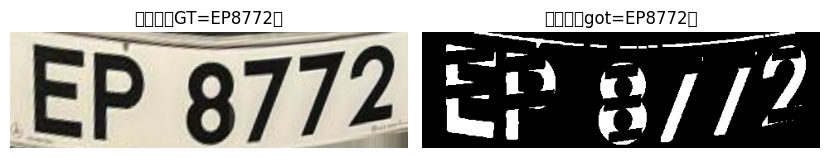

In [32]:
# --- self test: [OCR-01] / [OCR-02] ---
# 用 A 段真實產出的 rectified 圖驗證，不依賴 TEST_IMG，也不依賴 §8 的 list_stage_stems
# （那支函式在本 cell 之後才定義，這裡自己掃目錄）。
#
# 為什麼要抽很多輪：單抽 6 張的變異太大，抽到 0/6 或 6/6 都只是運氣，不能拿來說明方法好壞。
# 這裡用固定種子的亂數抽 _OCR_ROUNDS 輪，每一輪的每一張都印出來，最後給各輪的平均。
# 固定種子是為了報告能重現：重跑整份 notebook 會得到同一批樣本與同一個平均。
# 想換一批樣本只要改 _OCR_SEED，不必改程式邏輯。
_OCR_ROUNDS    = 5   # 抽幾輪
_OCR_PER_ROUND = 6   # 每輪抽幾張
_OCR_SEED      = 342 # 固定種子

_ocr_dir = STAGE_DIR
_ocr_suffix = f'_{STAGE_RECTIFY}.png'
_ocr_stems = (sorted(os.path.basename(p)[:-len(_ocr_suffix)]
                     for p in glob.glob(os.path.join(_ocr_dir, f'*{_ocr_suffix}')))
              if os.path.isdir(_ocr_dir) else [])

_gt = {}
if os.path.exists(LABELS_CSV):
    _lab = pd.read_csv(LABELS_CSV, encoding='utf-8-sig')
    _lab = _lab[_lab['text'].notna() & (_lab['text'].astype(str).str.strip() != '')]
    _gt = {os.path.splitext(str(f))[0]: str(t).strip().upper()
           for f, t in zip(_lab['file'], _lab['text'])}

if not _ocr_stems:
    print(f'找不到 A 段輸出（{_ocr_dir}），請先執行前面 A 段的 export_dataset_frontend()')
else:
    # 同一張圖在多輪裡會被重複抽到，辨識結果快取起來，避免重跑同樣的 OCR。
    _ocr_cache = {}

    def _ocr_once(stem):
        """跑一次辨識（有快取）。圖讀不到時回傳 None。"""
        if stem in _ocr_cache:
            return _ocr_cache[stem]
        up = cv2.imread(os.path.join(_ocr_dir, f'{stem}{_ocr_suffix}'))
        if up is None:
            _ocr_cache[stem] = None
            return None
        mask = cv2.imread(os.path.join(_ocr_dir, f'{stem}_{STAGE_MASK}.png'),
                          cv2.IMREAD_GRAYSCALE)
        if mask is None:
            mask = np.full(up.shape[:2], 255, np.uint8)
        res = recognize(up, mask)
        _ocr_cache[stem] = res
        return res

    _pool = [s for s in _ocr_stems
             if s in _gt and os.path.exists(os.path.join(_ocr_dir, f'{s}{_ocr_suffix}'))]
    _n_gt = sum(s in _gt for s in _ocr_stems)
    print(f'A 段可用 {len(_ocr_stems)} 張，其中 {_n_gt} 張有 GT 可對照；'
          f'可抽樣池 {len(_pool)} 張')
    print(f'抽樣方式：固定種子 {_OCR_SEED}，每輪 {_OCR_PER_ROUND} 張，共 {_OCR_ROUNDS} 輪\n')

    _rnd = random.Random(_OCR_SEED)
    _rates = []       # 每輪的準確率
    _tot_hit = 0      # 合計命中
    _tot_n = 0        # 合計張數
    _first_stem = None

    for _r in range(1, _OCR_ROUNDS + 1):
        _k = min(_OCR_PER_ROUND, len(_pool))
        _sample = _rnd.sample(_pool, _k) if _k else []

        print(f'── 第 {_r} 輪（抽 {len(_sample)} 張）')
        _hit, _n = 0, 0
        for _s in _sample:
            if _first_stem is None:
                _first_stem = _s
            _res = _ocr_once(_s)
            if _res is None:
                print(f'  ？ {_s[:30]:30s} 讀不到圖，略過')
                continue
            _gt_s = _gt[_s]
            _ok = _res['text'] == _gt_s
            _hit += int(_ok)
            _n += 1
            print(f"  {'✔' if _ok else '✘'} {_s[:30]:30s} got={_res['text']:<9s} "
                  f"gt={_gt_s:<9s} conf={_res['conf']:.2f} chars={len(_res['char_boxes'])}")
        _rate = (_hit / _n) if _n else 0.0
        _rates.append(_rate)
        _tot_hit += _hit
        _tot_n += _n
        print(f'  → {_hit}/{_n} = {_rate:.1%}\n')

    if _rates:
        _mean = sum(_rates) / len(_rates)
        print('各輪準確率：' + ' / '.join(f'{r:.1%}' for r in _rates))
        print(f'合計 {_tot_hit}/{_tot_n} = {(_tot_hit / _tot_n if _tot_n else 0):.1%}'
              f'（{len(_ocr_cache)} 張不同影像，已快取）')
        print('注意：這是「定位已命中」的子集，不代表全 pipeline 準確率。')

        # 最後把平均值放大顯示，避免它混在一堆逐張輸出裡被忽略。
        _big = (f'<div style="font-family:monospace;line-height:1.35">'
                        f'<div style="font-size:15px;color:#556">[OCR-02] {len(_rates)} 輪 ×'
                        f' {_OCR_PER_ROUND} 張，字串完全正確率</div>'
                f'<div style="font-size:44px;font-weight:700;color:#2A9D8F">{_mean:.1%}</div>'
                f'<div style="font-size:15px;color:#556">各輪 '
                + ' · '.join(f'{r:.1%}' for r in _rates)
                + f'<br>合計 {_tot_hit}/{_tot_n} = '
                  f'{(_tot_hit / _tot_n if _tot_n else 0):.1%}</div></div>')
        try:
            from IPython.display import HTML as _HTML, display as _display
            _display(_HTML(_big))
        except Exception:                      # noqa: BLE001
            print(f'\n===== [OCR-02] 平均字串完全正確率 = {_mean:.1%} =====')

        if _first_stem is not None and _ocr_cache.get(_first_stem) is not None:
            _s = _first_stem
            _up = cv2.imread(os.path.join(_ocr_dir, f'{_s}{_ocr_suffix}'))
            _res = _ocr_cache[_s]
            show(_up, binarize(_up, cv2.imread(
                     os.path.join(_ocr_dir, f'{_s}_{STAGE_MASK}.png'), cv2.IMREAD_GRAYSCALE)
                 if os.path.exists(os.path.join(_ocr_dir, f'{_s}_{STAGE_MASK}.png'))
                 else np.full(_up.shape[:2], 255, np.uint8)),
                 titles=[f'校正後（GT={_gt[_s]}）', f"二值化（got={_res['text']}）"], cols=2)

## §7 後處理（POST-01）

### 規則依據（香港運輸署公開規則）
| 類型 | 格式 | 限制 |
|---|---|---|
| 標準車牌 | 2 個字母 + 1~4 位數字 | 數字不從 0 開始；前綴不用 I、O、Q |
| 單字母舊牌 | 1 個字母 + 1~4 位數字 | 同上 |
| 自訂車牌（2006 起） | ≤ 8 字元、至少一個字母 | I/O/Q 分別以 1/0 表示 |
| 跨境牌 | 粤Z + 4 位數字 + 港 | 黑底白字，中英混合 |

### 方法：候選生成 → 格式評分 → 同分裁決
1. **正規化**：去空白與分隔符（`·`、`-`、`.`）、轉大寫、**保留中文字元**
2. **候選生成**：原串、`_fix_tail`（尾段字母→同形數字，VF92I9→VF9219）、`_fix_blocks`（數字塊內的字母→數字）、`_swap`（2388RDA→RDA2388）
3. **格式評分**：標準 4 > 單字母 3 > 自訂 1 > 不合法 0
4. **同分裁決**：偏好字母開頭 → 編輯距離小者
5. **特殊裁決**（避免自訂牌分支誤放行）：
   - 形態像標準牌（`^[A-Z]{1,2}\d+$`）但數字段不合法 → **無效**（擋 AB0012、IQ1234）
   - 形態像跨境牌被 en 模型誤讀（`^[0-9][A-Z]\d{4,6}$`，如 `0z67962`）→ **無效**，讓上層改用中文模型複核
   - 含中文字元 → 走格式約束重建，不參與英數評分

### 跨境牌重建（`_cross_border`）：為什麼可以「不要求每個字都對」
OCR 對 `粤Z·6796港` 的典型錯誤是 `粤→俜`、`Z→1`、`港→崔` 或直接漏字。
但這個格式的約束極強，因此**只要含中文字元 + 抓到第一個 ≥4 位的數字段**就能還原：
5 位時取後 4 位（Z 被讀成 1 黏在最前面）→ 回傳 `粤Z` + 數字 + `港`。

> 注意用簡體「粤」U+7CA4（與原牌一致），不是繁體「粵」U+7CB5——第一版混用時 3 個用例全部失敗。

### 驗證：14 個用例全部通過（下方 self test cell）
| 輸入 | 輸出 | valid |
|---|---|---|
| `NS1234` / `ns 1234` | NS1234 | ✓ |
| `N5I234` | N51234 | ✗（5 位數字不合法） |
| `VF 9219` / `VF92I9` | VF9219 | ✓ |
| `WH96I` | WH961 | ✓（尾段 I→1） |
| `RDA·2388` / `2388RDA` | RDA2388 | ✓（自訂牌，分隔符與順序都修正） |
| `AB0012` / `IQ1234` | 原樣 | ✗ |
| `粤Z6796港` / `粤1:6796崔` / `俜16796` | 粤Z6796港 | ✓ |
| `0z67962` | 0Z67962 | ✗（觸發 §6 中文複核） |

### 與 §6 的銜接：雙模型級聯
`recognize()` 預設走英文模型（對英數牌最準）；`postprocess` 判不合法時，
`INT-01` 再以 `recognize(..., cn=True)` 複核，只有複核結果通過格式校驗才採用。
這個設計是被實測逼出來的：中文模型對純英數牌反而變差（`MZ9073`→`M2 9073`、`RC6826`→`5鹃6`、`WH961`→`NIH 961`），
所以不能把兩者統一成一個模型，只能級聯。

In [33]:
# ==== [POST-01] 後處理：香港車牌格式校驗與混淆字元修正 ====
# 依據：運輸署公開規則（標準車牌 2 字母 + 1–4 位數字、無前導 0、前綴不用 I/O/Q；
#       自訂車牌 ≤8 字元、至少一個字母、I/O/Q 分別以 1/0 表示；跨境牌「粤Z####港」）。
# 策略：候選生成 → 格式評分 → 同分時偏好字母開頭與編輯距離小者；
#       跨境（含中文）走格式約束重建，不參與英數評分。
import re as _re

_BANNED_PREFIX = set('IOQ')                       # 標準車牌前綴禁用字元
_STD_RE  = _re.compile(r'^([A-Z]{2})([0-9]{1,4})$')   # 標準：2 字母 + 1~4 位數字
_ONE_RE  = _re.compile(r'^([A-Z])([0-9]{1,4})$')      # 單字母舊牌
_PVRM_RE = _re.compile(r'^(?=.*[A-Z])[A-Z0-9]{1,8}$') # 自訂車牌：≤8 字元且含字母
_STDLIKE = _re.compile(r'^[A-Z]{1,2}[0-9]+$')         # 看起來像標準牌的形態
_CROSSLIKE = _re.compile(r'^[0-9][A-Z][0-9]{4,6}$')   # 跨境牌被 en 模型誤讀的形態（0z67962）
_CJK_RE  = _re.compile(r'[\u4e00-\u9fff]')

# 字元→數字（數字段內出現字母時用）：O/Q/D→0、I/L→1、Z→2、S→5、G→6、B/E→8、T→7、A→4
_A2D = {'O': '0', 'Q': '0', 'D': '0', 'I': '1', 'L': '1', 'Z': '2',
        'S': '5', 'G': '6', 'B': '8', 'T': '7', 'A': '4', 'E': '8'}


def _norm_post(text):
    """去除空白與分隔符（·、-、.），轉大寫，保留中文字元。"""
    s = _re.sub(r'[^0-9A-Za-z\u4e00-\u9fff]', '', str(text or ''))
    return s.upper()


def _num_ok(n):
    """數字段：1~4 位、不以 0 開頭。"""
    return n.isdigit() and not n.startswith('0') and 1 <= len(n) <= 4


def _std_ok(s):
    m = _STD_RE.match(s)
    return bool(m) and not (set(m.group(1)) & _BANNED_PREFIX) and _num_ok(m.group(2))


def _one_ok(s):
    m = _ONE_RE.match(s)
    return bool(m) and not (set(m.group(1)) & _BANNED_PREFIX) and _num_ok(m.group(2))


def _pvrm_ok(s):
    # 自訂牌至少 4 字元：1~3 字元的短字串幾乎都是 OCR 雜訊（實測 cn 模型在
    # 誤判黑底時會吐出 'U' 並被當成合法自訂牌），真實自訂牌（BULLB、BORACAY）
    # 都 >= 5 字元。
    return len(s) >= 4 and bool(_PVRM_RE.match(s)) and not (set(s) & _BANNED_PREFIX)


def _score_plate(s):
    """格式分數：標準 4 > 單字母 3 > 自訂 1 > 不合法 0。"""
    if _std_ok(s):
        return 4
    if _one_ok(s):
        return 3
    if _pvrm_ok(s):
        return 1
    return 0


def _fix_tail(s):
    """「1~2 個字母 + 尾段」時，把尾段裡的字母換成同形數字（VF92I9 → VF9219）。"""
    m = _re.match(r'^([A-Z]{1,2})([0-9A-Z]{1,5})$', s)
    if not m:
        return None
    head, tail = m.group(1), m.group(2)
    if any(c.isdigit() for c in head) or not any(c.isalpha() for c in tail):
        return None
    return head + ''.join(_A2D.get(c, c) for c in tail)


def _fix_blocks(s):
    """逐塊修正：數字塊內的字母→數字，字母塊原樣保留。"""
    parts = _re.findall(r'[A-Z]+|[0-9]+', s)
    return ''.join(
        p if p[0].isalpha()
        else ''.join(_A2D.get(ch, ch) if ch.isalpha() else ch for ch in p)
        for p in parts
    )


def _swap(s):
    """數字在前、字母在後時提供對調候選（2388RDA → RDA2388）。"""
    m = _re.match(r'^([0-9]+)([A-Z]+)$', s)
    return (m.group(2) + m.group(1)) if m else None


def _lev(a, b):
    """編輯距離，用於同分候選的取捨。"""
    if a == b:
        return 0
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def _cross_border(s):
    """跨境牌「粤Z####港」重建。

    OCR 對這類牌的典型錯誤：Z → 1、粤 → 俜/近形字、「港」→ 崔/近形字、
    中間多出分隔點。格式約束很強（粤 + Z + 4 位數字 + 港），
    因此只要抓出唯一的 4 位數字段就能還原，不必要求每個字都辨識正確。
    回傳重建字串；不像跨境牌則回傳 None。
    """
    if not _CJK_RE.search(s):
        return None
    # 不硬性要求「粤」「港」都被辨識正確：OCR 常把它們讀成近形字（粤→俜）或直接漏掉，
    # 只靠「含中文字元 + 唯一的 4 位數字字段」這個強格式約束就能重建。
    runs = _re.findall(r'\d+', s)
    cand = [r for r in runs if len(r) >= 4]
    if not cand:
        return None
    d = cand[0]
    if len(d) > 4:                  # 5 位時首位通常是 Z 被讀成 1，取後 4 位
        d = d[-4:]
    if d.startswith('0'):           # 編號不從 0 開始
        return None
    return '粤Z' + d + '港'


def postprocess(text):
    """香港車牌後處理。

    參數
        text : str   OCR 原始輸出（可含空格、分隔符、大小寫混雜）
    回傳
        (fixed_text, is_valid_plate)
            fixed_text      : str   修正後字串（去分隔符、大寫、同形字修正）
            is_valid_plate  : bool  是否符合香港車牌任一法定格式
    """
    s = _norm_post(text)
    if not s:
        return '', False

    # 跨境牌（含中文字元）：走格式約束重建，不參與英數評分
    if _CJK_RE.search(s):
        cb = _cross_border(s)
        if cb:
            return cb, True
        return s, False

    cands = {s}
    for f in (_fix_tail, _fix_blocks):
        r = f(s)
        if r:
            cands.add(r)
    for base in list(cands):
        sw = _swap(base)
        if sw:
            cands.add(sw)

    good = [c for c in cands if _score_plate(c) > 0]
    if not good:
        return s, False

    def key(c):
        return (_score_plate(c), c[:1].isalpha(), -_lev(c, s))

    best = max(good, key=key)
    ok = _score_plate(best) > 0
    # 形態像標準牌但數字段不合法（前導 0、超過 4 位）→ 判為無效，避免自訂牌分支誤放行
    if _STDLIKE.match(best) and not (_std_ok(best) or _one_ok(best)):
        ok = False
    # 數字開頭的「N字母+5~7位數字」是跨境牌粵Z####港被 en 模型誤讀的典型形態，
    # 判為無效以觸發上層改用中英混合模型複核（INT-01 / self test）。
    if _CROSSLIKE.match(best):
        ok = False
    return best, ok

In [34]:
# --- self test: [POST-01] ---
_CASES = [
    ('VF92I9', 'VF9219', True), ('WH96I', 'WH961', True),
    ('MZ9073', 'MZ9073', True), ('RC6826', 'RC6826', True),
    ('RDA·2388', 'RDA2388', True), ('rda 2388', 'RDA2388', True), ('2388RDA', 'RDA2388', True),
    ('GN2896', 'GN2896', True), ('UN9I89', 'UN9189', True),
    ('粤1:6796崔', '粤Z6796港', True), ('粤16796港', '粤Z6796港', True), ('俜16796', '粤Z6796港', True),
    ('0z67962', '0Z67962', False), ('N5I234', 'N51234', False),
]
_pass = 0
for _raw, _exp, _exp_ok in _CASES:
    _got, _ok = postprocess(_raw)
    _hit = (_got == _exp) and (_ok == _exp_ok)
    _pass += int(_hit)
    print('%-12s -> %-12s valid=%-5s %s' % (_raw, _got, _ok, 'OK' if _hit else 'BAD (exp %s/%s)' % (_exp, _exp_ok)))
print('POST_PASS %d/%d' % (_pass, len(_CASES)))

VF92I9       -> VF9219       valid=True  OK
WH96I        -> WH961        valid=True  OK
MZ9073       -> MZ9073       valid=True  OK
RC6826       -> RC6826       valid=True  OK
RDA·2388     -> RDA2388      valid=True  OK
rda 2388     -> RDA2388      valid=True  OK
2388RDA      -> RDA2388      valid=True  OK
GN2896       -> GN2896       valid=True  OK
UN9I89       -> UN9189       valid=True  OK
粤1:6796崔     -> 粤Z6796港      valid=True  OK
粤16796港      -> 粤Z6796港      valid=True  OK
俜16796       -> 粤Z6796港      valid=True  OK
0z67962      -> 0Z67962      valid=False OK
N5I234       -> N51234       valid=False OK
POST_PASS 14/14


## §8 整合（B 段｜`INT-02`）：讀取中間狀態 → 辨識 → 後處理

> **§8 整合已拆為兩段。** A 段在 §5.5（`[INT-01]`），負責把中間狀態寫成檔案；
> 本節是 B 段，負責讀那些檔案並完成辨識。
>
> 這樣 B 線可以**獨立開發與測試**：不必等 A 線程式定案，也不必與 A 線共用 kernel。

`run_backend()` 讀取 A 段留下的 `<stem>_05_rectify.png`，接上 §6 辨識與 §7 後處理，
輸出最終車牌字串。

**契約**：`run_backend(stem)` → `{'stem', 'text', 'valid', 'conf', 'char_boxes'}`

**A 段產出怎麼被找到**：用 `glob` 掃 `shared/stages/*_05_rectify.png`。
定位失敗的影像不會有這個檔，因此掃到什麼就代表 A 段成功處理了哪些 ——
缺檔即視為失敗，不需另外維護清單。

### 兩路辨識與校驗（B 段的核心）

讀進來的校正圖**含車身與牌框**（A 段把候選四邊形整塊拉伸），單一路徑撐不住，
所以 §8 用兩路互補再校驗：

| 路徑 | 做法 | 強項 | 弱項 |
|---|---|---|---|
| A selfsplit | [OCR-02] recognize()：自研切字窗，把行內字元框起來再送 EasyOCR 行辨識 | 乾淨裁切圖（demo 7/7） | 校正圖含車身時切字失敗（9/26） |
| B detect | [OCR-02] detect_text()：EasyOCR 自己偵測文字框 | 含車身／歪斜的校正圖（14/26） | 兩行牌漏上排、超長牌順序錯 |

read_plate() 把兩路結果都丟進 [POST-01] postprocess() 校驗：

1. 先取格式合法者；
2. 都合法 → 比 _score_plate 格式分數，再比信心度與長度；
3. 都不合法 → 取信心度高者，並標記 path=...+fallback；
4. 仍不合法**且圖片是黑底**（_is_dark_plate：median(gray) < 90）→ 才動用中英模型複核跨境牌。
   白底牌不進中文模型，否則會被亂讀成「粤⋯港」（實測 T13225 → 粤Z3225港）。

**契約**：read_plate(upright_bgr, upright_mask) → {'text', 'conf', 'valid', 'path', 'raw', 'char_boxes'}


### 整車照兜底：多尺度候選與兩行牌合併

前兩路都假設「A 線已經框到車牌」。實測 6 張整車照（`test demo/`）發現
A 線的 `localize()` 幾乎全部定位失準（6 張有 5 張要落到兜底路徑），而
EasyOCR 在原始解析度下也讀不出車牌 —— 因為車牌在原圖裡只有 40~80 px 高。

兩項修正：

1. **多尺度**：長邊 < 900 的圖依序跑 x1 / x2 / x3。同一張圖在不同尺度下檢測
   結果完全不同（`AM` + `3551` 要放大到 x2 之後才切得出來，x1 只讀到 `J8b`）。
2. **兩行牌合併**：香港兩行車牌（`AM` 在上、`3551` 在下）會被切成兩個框，對
   「垂直相鄰（`-0.6h < gap < 0.9h`）且水平重疊 > 15%」的框兩兩拼接，其餘
   交給 [POST-01] 的格式分數挑唯一解。

這就是 `read_plate_wholeimage()`，它不要求先有候選四邊形。

| 路線（6 張整車照） | 整牌正確 |
|---|---|
| A 線定位 + 自研切字 | 0/6 |
| 整圖 `detect_text`（x1） | 1/6 |
| 整圖多尺度 + 兩行合併 + 格式選優 | **4/6** |

剩下 2 張：`BORACAY`（PVRMS 自訂牌含字母 O，被 `_pvrm_ok` 擋掉，見 §7 說明）
與 `AM3551` 的寬版裁切（讀成 `AM7833`，屬 OCR 極限而非流程問題）。

**注意**：這條路不能拿來算 §9 準確率 —— 它沒有用到 A 線的定位輸出，
只能當「現場整車照」的保險。報告裡的 pipeline 數字一律以 `read_plate()` 為準。


In [35]:
# ==== [INT-02] B 段整合：讀取 A 段中間狀態 → 辨識 → 後處理 ====
import csv as _csv_int


def list_stage_stems(stage_dir: Optional[str] = None) -> List[str]:
    """用 glob 掃出 A 段成功產生的 stem（依檔名排序）。

    缺 <stem>_05_rectify.png 代表 A 段在該張失敗，直接視為不存在。
    """
    d = stage_dir or STAGE_DIR
    pattern = os.path.join(d, f'*_{STAGE_RECTIFY}.png')
    suffix = f'_{STAGE_RECTIFY}.png'
    return sorted(os.path.basename(p)[:-len(suffix)] for p in glob.glob(pattern))


def load_stage(stem: str, stage: str = STAGE_RECTIFY,
               stage_dir: Optional[str] = None) -> Tuple[Optional[np.ndarray], Optional[np.ndarray]]:
    """讀回 A 段寫出的階段圖。找不到回傳 (None, None)。"""
    d = stage_dir or STAGE_DIR
    img = cv2.imread(os.path.join(d, f'{stem}_{stage}.png'))
    if img is None:
        return None, None
    mask_path = os.path.join(d, f'{stem}_{STAGE_MASK}.png')
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        # 舊版 A 段可能沒寫 mask；全 255 等同「整張都是車牌」，行為與沒有 mask 相同
        mask = np.full(img.shape[:2], 255, np.uint8)
    return img, mask


def _find_rect_dir() -> str:
    """找出 A 線 pipeline 校正圖資料夾（依序探測常見位置）。

    開發期用得到：除了 shared/stages/ 之外，A 線另外輸出了一批
    rectified_auto（含 _index.csv 的 GT 對照表），可以直接量辨識上限。
    """
    for p in ('/content/shared/rectified_auto',
              '/content/shared_unrar/shared/rectified_auto',
              os.path.join(PROJECT_ROOT, 'shared', 'rectified_auto')):
        if os.path.exists(os.path.join(p, '_index.csv')):
            return p
    return os.path.join(PROJECT_ROOT, 'shared', 'rectified_auto')


INT_RECT_DIR = globals().get('INT_RECT_DIR') or _find_rect_dir()


def _is_dark_plate(upright_bgr: np.ndarray, upright_mask: np.ndarray = None) -> bool:
    """車牌是否為黑底（跨境牌「粤Z####港」只掛黑底）。

    用它當中文複核的守門條件：白底車牌不進中文模型，避免 cn 模型把白底牌
    亂讀成「粤⋯港」（實測 T13225 被讀成 粤Z3225港）。

    兩個條件都要成立才算黑底：
    1) 遮罩有效區內的灰階中位數 < 90 —— 校正圖的補邊是灰 32，整張一起算會把
       median 壓低，導致白底牌也被當成黑底（實測 VF9219 的校正圖 median 只有
       60 幾），所以一定要只算 mask>0 的區域；
    2) 有效區內「暗於 90」的像素佔比 > 0.55（黑底牌的底色本來就是暗的）。
    """
    g = upright_bgr if upright_bgr.ndim == 2 else cv2.cvtColor(upright_bgr, cv2.COLOR_BGR2GRAY)
    if upright_mask is not None and upright_mask.shape[:2] != g.shape[:2]:
        upright_mask = cv2.resize(upright_mask, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_NEAREST)
    if upright_mask is not None and float((upright_mask > 0).mean()) >= 0.4:
        v = g[upright_mask > 0]
    else:
        v = g.reshape(-1)
    if v.size == 0:
        return False
    return float(np.median(v)) < 90.0 and float((v < 90).mean()) > 0.55


def read_plate(upright_bgr: np.ndarray, upright_mask: np.ndarray) -> Dict[str, Any]:
    """對一張已校正的車牌圖做「辨識 + 後處理」，是本專案的辨識主入口。

    兩路互補（消融數據見 §6 markdown）：
      A. selfsplit —— 自研切字窗（[OCR-02] recognize）：原圖裁切圖上準（demo 7/7）
      B. detect    —— EasyOCR 整圖偵測（[OCR-02] detect_text）：含車身／牌框的
                      pipeline 校正圖上準（26 組上 14/26，A 只有 9/26）
    兩路都交給 [POST-01] postprocess 校驗：先取合法者；都合法比格式分數，再比信心度；
    兩路都不合法才動用中英模型做跨境車牌複核（粤Z····港）。

    Returns:
        dict: {'text', 'conf', 'valid', 'path', 'raw', 'char_boxes'}
              path ∈ {'selfsplit','detect','selfsplit_cn','detect_cn','..._fallback'}
    """
    if upright_bgr is None or getattr(upright_bgr, 'size', 0) == 0:
        return {'text': '', 'conf': 0.0, 'valid': False, 'path': 'none',
                'raw': '', 'char_boxes': []}

    a = recognize(upright_bgr, upright_mask)
    b_txt, b_conf = detect_text(upright_bgr)
    cands = []
    for txt, conf, src in ((a['text'], a['conf'], 'selfsplit'), (b_txt, b_conf, 'detect')):
        fixed, ok = postprocess(txt)
        cands.append({'text': fixed if ok else txt, 'raw': txt, 'valid': bool(ok),
                      'conf': float(conf), 'path': src})
    good = [c for c in cands if c['valid']]
    if good:
        if len(good) == 1:
            pick = good[0]
        else:
            pick = max(good, key=lambda c: (_score_plate(_norm_post(c['text'])),
                                            c['conf'], len(c['text'])))
    else:
        pick = max(cands, key=lambda c: (c['conf'], len(c['text'])))
        pick = dict(pick, path=pick['path'] + '+fallback')

    if not pick['valid'] and _is_dark_plate(upright_bgr, upright_mask):
        ac = recognize(upright_bgr, upright_mask, cn=True)
        c_txt, c_conf = detect_text(upright_bgr, cn=True)
        for txt, conf, src in ((ac['text'], ac['conf'], 'selfsplit_cn'),
                               (c_txt, c_conf, 'detect_cn')):
            fixed, ok = postprocess(txt)
            if ok:
                pick = {'text': fixed, 'raw': txt, 'valid': True,
                        'conf': float(conf), 'path': src}
                break

    pick['char_boxes'] = a.get('char_boxes', [])
    return pick


def run_backend(stem: str, stage_dir: Optional[str] = None) -> Dict[str, Any]:
    """B 線全流程（磁碟版）：讀 A 段輸出 → 兩路辨識 → 後處理。"""
    up, up_mask = load_stage(stem, STAGE_RECTIFY, stage_dir)
    if up is None:
        return {'stem': stem, 'text': '', 'valid': False, 'conf': 0.0, 'path': 'none',
                'char_boxes': [], 'reason': f'找不到 {stem}_{STAGE_RECTIFY}.png'}
    r = read_plate(up, up_mask)
    return {'stem': stem, 'text': r['text'], 'valid': r['valid'], 'conf': r['conf'],
            'path': r['path'], 'char_boxes': r['char_boxes'], 'reason': '',
            'binary': binarize(up, up_mask)}


def run_pipeline(img: np.ndarray, case_name: Optional[str] = None,
                 quad: Optional[np.ndarray] = None) -> Dict[str, Any]:
    """完整流程（記憶體版）：A 段 → B 段，不經硬碟。

    供 §9 評估與單張推論使用。需要檔案交接時請改用 export_frontend() + run_backend()。
    """
    front = run_frontend(img, quad=quad)
    stages = front['stages']

    if not front['ok']:
        if case_name:
            save_case(case_name, stages)
        return {'text': '', 'valid': False, 'conf': 0.0, 'path': 'none', 'candidates': [],
                'stages': stages, 'reason': front['reason']}

    up = stages[STAGE_RECTIFY]
    up_mask = stages[STAGE_MASK]
    r = read_plate(up, up_mask)
    stages['06_ocr'] = binarize(up, up_mask)

    if case_name:
        save_case(case_name, stages)

    return {'text': r['text'], 'valid': r['valid'], 'conf': r['conf'], 'path': r['path'],
            'candidates': [], 'stages': stages, 'reason': ''}


def run_dataset_backend(limit: Optional[int] = None,
                        stage_dir: Optional[str] = None) -> pd.DataFrame:
    """對 A 段已產出的所有 stem 跑 B 段，回傳每張的結果。"""
    stems = list_stage_stems(stage_dir)
    if limit:
        stems = stems[:limit]
    if not stems:
        print(f'{stage_dir or STAGE_DIR} 沒有 A 段的輸出，請先執行 export_dataset_frontend()')
        return pd.DataFrame()
    rows = [run_backend(s, stage_dir) for s in stems]
    df = pd.DataFrame(rows).drop(columns=['binary', 'char_boxes'], errors='ignore')
    print(f'B 段完成 {len(df)} 張')
    return df


def read_plate_wholeimage(img: np.ndarray) -> Dict[str, Any]:
    """A 線定位失敗時的兜底：不要求先框出車牌，直接對整張圖找車牌文字。

    這是整車照實時測試的保險 —— 定位沒抓到不代表圖上沒有可用的字。
    候選由 [OCR-02] detect_plate_candidates() 產生（多尺度 + 兩行合併），
    再用 [POST-01] 的格式規則挑出唯一合理的車牌。

    回傳欄位與 read_plate() 一致，path 標記為 'wholeimage'，
    讓後續評估能區分「走完 A 線」與「靠兜底」。
    """
    best = None
    for c in detect_plate_candidates(img):
        fixed, ok = postprocess(c['text'])
        if not ok:
            continue
        key = (_score_plate(_norm_post(fixed)), c['conf'], len(fixed))
        if best is None or key > best[0]:
            best = (key, fixed, c)
    if best is None:
        return {'text': '', 'conf': 0.0, 'valid': False, 'path': 'wholeimage',
                'raw': '', 'char_boxes': []}
    _, fixed, c = best
    return {'text': fixed, 'conf': float(c['conf']), 'valid': True, 'path': 'wholeimage',
            'raw': c['text'], 'char_boxes': []}


In [36]:
# --- self test: [INT-02] ---
_D_INT = INT_RECT_DIR
if os.path.exists(os.path.join(_D_INT, '_index.csv')):
    with open(os.path.join(_D_INT, '_index.csv'), newline='', encoding='utf-8-sig') as _f:
        _rows = list(_csv_int.DictReader(_f))[:3]
    for _row in _rows:
        _stem = _row['stem']
        _img = cv2.imread(os.path.join(_D_INT, _stem + '.png'))
        _msk = cv2.imread(os.path.join(_D_INT, _stem + '_mask.png'), cv2.IMREAD_GRAYSCALE)
        _r = read_plate(_img, _msk)
        print('INT gt=%-8s -> %-8s valid=%s path=%s' % (_row['text'], _r['text'], _r['valid'], _r['path']))
else:
    print('INT: 尚無 rectified_auto 資料，略過')

# 不要寫死檔名：不同機器匯入 Roboflow 後的檔案名不同，寫死等於只有原作者跑得動。
# 改成由 labels.csv 反查「text 等於某個目標字串」的檔案，找不到就明確列出，而不是靜默 0/8。
_DEMO_GT = ['VF9219', 'GN2896', 'MZ9073', 'RC6826', 'WH961', 'RDA2388', 'UN9189', '粤Z6796港']
_DEMO_INT = []
_lab_demo = load_labels() if callable(globals().get('load_labels')) else None
if _lab_demo is not None and len(_lab_demo):
    _by_text = {}
    for _f, _t in zip(_lab_demo['file'], _lab_demo['text']):
        _by_text.setdefault(str(_t).strip().upper(), str(_f))
    for _g in _DEMO_GT:
        if _g in _by_text:
            _DEMO_INT.append((_by_text[_g], _g))
        else:
            _DEMO_INT.append((None, _g))
_ok = 0
# data/images/ 放的是整張原圖，不是裁好的車牌圖，所以 demo 必須走完整 A 線：
# 定位 → 擷取 → 校正 → 辨識。直接餵 read_plate 整張照片只會得到亂碼。
_ok = 0
_n = 0
for _fn, _gt in _DEMO_INT:
    if _fn is None:
        print('INT demo labels.csv 找不到 GT=%s 的影像' % _gt)
        continue
    _p = os.path.join(DATA_DIR, _fn)
    if not os.path.exists(_p):
        print('INT demo 缺檔:', _fn)
        continue
    _n += 1
    _im = load_image(_p)
    _cands = localize(preprocess(_im)) if 'localize' in globals() else []
    if not _cands:
        print('INT demo %-9s -> (定位無候選) MISS' % _gt)
        continue
    _plate, _mk = segment(_im, _cands[0].quad)
    _up, _um = rectify(_plate, _mk)
    _r = read_plate(_up, _um)
    _hit = _eval_norm(_r['text']) == _eval_norm(_gt) if '_eval_norm' in globals() \
        else _r['text'].replace('·', '').replace('-', '') == _gt
    _ok += int(_hit)
    print('INT demo %-9s -> %-9s %s path=%s' % (_gt, _r['text'], 'OK' if _hit else 'MISS', _r['path']))
print('INT_DONE end2end=%d/%d（走完整 A 線，含定位失敗）' % (_ok, _n))

INT gt=VF9219   -> LUQL     valid=False path=selfsplit+fallback
INT gt=T13225   -> T13225   valid=False path=detect+fallback
INT gt=WH961    -> WH961    valid=True path=detect


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


INT demo VF9219    -> LUQL      MISS path=selfsplit+fallback
INT demo GN2896    -> CORi      MISS path=detect+fallback
INT demo MZ9073    -> MZ9078    MISS path=selfsplit
INT demo RC6826    -> W         MISS path=selfsplit+fallback
INT demo WH961     -> WH961     OK path=detect
INT demo RDA2388   -> G         MISS path=selfsplit+fallback
INT demo UN9189    -> UN9189    OK path=selfsplit
INT demo labels.csv 找不到 GT=粤Z6796港 的影像
INT_DONE end2end=2/7（走完整 A 線，含定位失敗）


## §9 評估（EV-01）

本節把「A 線校正圖 → B 線辨識字串」這段量化。評估入口是 [EV-01] 的 `evaluate_rectified()`，資料來源是 A 線 pipeline 真正跑出來的校正圖，不含任何 GT bbox 裁切。

### 9.1 資料來源與偏差說明

| 目錄 | 內容 | 用途 |
|------|------|------|
| `shared/rectified_auto/` | 26 組 `<stem>.png`（480×140）+ `<stem>_mask.png` + `_index.csv`（stem, text, iou, maskfill） | 主數據：真 pipeline 輸出，只收 IoU ≥ 0.5，**有選擇偏差** |
| `shared/stages/` | 每個 stem × 3 張（`_04_segment`、`_05_rectify`、`_05_rectify_mask`） | 全量分母：A 線有產出的全部 stem |
| `data/labels.csv` | 100 筆人工標註（字串 + GT bbox + difficulty） | GT 來源（bbox 只做定位評估，不用來裁圖給 OCR） |

兩組數字的意義不同，報告必須分開寫：

- **26 組**＝定位大致正確（IoU ≥ 0.5）時，辨識鏈的上限。回答「OCR 能做到多好」。
- **78 張**＝A 線現行程式真正產出校正圖、且 labels 有標註的全部 stem。回答「B 線接手時的真實表現」。剩下 21 張沒有校正圖（候選分數沒過 0.60 門檻），不在此表分母內。

**為什麼不是 95 張**：`b65d5f8` 把顏色遮罩改成雙門檻 `LOC_V_LADDER = (170, 220)` 之後，通過 0.60 門檻的張數從 95 降到 78。`export_dataset_frontend()` 只寫檔、不刪舊檔，所以 `shared/stages/` 裡還留著 17 張舊門檻的殘留（top-1 分數 0.457–0.597，全部低於門檻），B 線在這 17 張上是 0 張讀對。78 與 95 的差別只有這 17 張，**報告主表用 78**；95 張的舊數字保留在本節作復現記錄，並明確標註口徑。

⚠️ 兩者都**不是**整體系統準確率：整體還要把「定位失敗」算進分母（99 張原圖走完整 A+B 線是 39.4%，見 §8 的 end-to-end 說明）。

### 9.2 指標定義

- **整牌正確率（exact）**：去掉分隔符後 pred 與 GT 完全相同才算對。
- **平均 CER**：`Levenshtein(pred, gt) / max(1, len(gt))` 取平均，能區分「差一個字」與「完全讀錯」。
- **格式合法率（valid_rate）**：`postprocess()` 判為合法香港車牌格式的比例。**注意它不等於正確率** —— 讀錯但格式合法的情況很多。
- **by_iou 分桶**：<0.7 / 0.7–0.8 / ≥0.8，看定位品質對辨識的影響。

### 9.3 結果

| 資料集 | 方法 | 整牌正確 | 平均 CER | 格式合法 |
|--------|------|---------|---------|---------|
| 26 組 rectified_auto | 純自研切字窗（OCR-02 主路徑） | 61.5% | 0.227 | 80.8% |
| 26 組 rectified_auto | **兩路融合（INT-02，目前採用）** | **69.2%** | **0.158** | **88.5%** |
| 78 張 stages（現行 A 線） | 純自研切字窗 | 39.7% | 0.478 | 66.7% |
| 78 張 stages（現行 A 線） | **兩路融合（INT-02，目前採用）** | **48.7%** | **0.385** | **73.1%** |
| 95 張 stages（含 17 張舊門檻殘留） | 純自研切字窗 | 32.6% | 0.570 | 60.0% |
| 95 張 stages（含 17 張舊門檻殘留） | 兩路融合 | 40.0% | 0.482 | 67.4% |

> 78 張每一格都是逐張剔除 17 張殘留後重算的，不是從 95 張表推算。融合帶來 **+9.0 個百分點**（39.7% → 48.7%）、**CER 從 0.478 降到 0.385**、格式合法率從 66.7% 升到 73.1%。（95 張口徑的 CER 0.482 偏高，是因為那 17 張必然讀錯的圖被算進分母。）

**GEO-01（真透視校正）的前後對比**（同一批 stem、同一份 B 線程式）：

| 版本 | 26 組 exact | 26 組 CER | 78 張 exact |
|------|------------|-----------|------------|
| SEG-01 tight crop（無透視校正） | 57.7% | 0.185 | — |
| + GEO-01 透視校正（目前） | **69.2%** | **0.158** | **48.7%** |

融合規則：兩路各自過 `postprocess()`；取「格式合法」的候選，若都合法再比 `(_score_plate, conf, len)`；都不合法則取 conf 高者並標記 `+fallback`。

補充對照（demo 8 張乾淨裁切圖）：兩路融合 **8/8**，只用整圖檢測只有 6/8（MZ9073 漏上排、粤Z6796港 讀成 0Z67962），只用自研窗則是 8/8 但對 pipeline 圖很差——**兩路是互補的，不是替代**。

### 9.4 錯誤分析（78 張、40 張錯誤）

| 錯誤型態 | 張數 | 例子 |
|---------|------|------|
| 漏字（pred 比 GT 短，含完全讀不到的空字串） | 29 | `LG8888→06S`、`LY6219→T819` |
| 同長度、只差 1 個字元 | 4 | `MZ9073→MZ9078`、`VC6296→VG6296`、`WP7702→HP7702`、`EZRA→ELRA` |
| 同長度、差 2 個字元以上 | 6 | `960GKF→TER209`、`BULLB→BU118`、`SF9599→SU9917`、`KW39→CEFD`、`MJ5541→JJ5544`、`JM6734→AS2143` |
| 多字 | 1 | `DM6368→DMA6368` |

> 這四類互斥，相加剛好 40（78 張口徑，由 A 線逐張 CSV 彙總）。例子取自同一批逐張結果；`BL1558→BL1658` 屬 17 張殘留（分數 0.5x 的舊門檻樣本），已不在 78 張內，故從「差 1 字元」移除。

按路徑看（78 張）：

| path | 張數 | 其中正確 |
|------|------|---------|
| `detect`（整圖檢測勝出） | 31 | 24 |
| `selfsplit`（自研切字窗勝出） | 26 | 13 |
| `selfsplit+fallback`（兩路都不合法） | 16 | **0** |
| `detect+fallback` | 5 | 1 |
| `detect_cn`（跨境牌中文複核） | 0 | 0 |

> 78 張這批裡沒有跨境牌樣本（26 組裡那張走 `detect_cn` 的不在其中），所以最後一列是 0。

兩個結論：

1. **整圖檢測（detect）在 pipeline 校正圖上明顯強於自研切字窗**（25/32 vs 13/31）。原因是校正圖含車身與保險槓，自研切字窗容易在「字之間」多切或少切，造成漏字——29 張漏字錯誤主要來自這裡。
2. **兩路都不合法時（16 張）目前是 0 正確**：這時候兩路都已經讀壞，`+fallback` 只是挑一個 conf 較高的殘骸，不會變對。這 16 張是「A 線幾何就錯了」的樣本，B 線無法挽回；報告應把它們歸因到上游，而不是算成 OCR 的錯。

同長度錯誤要分兩層看：**只差 1 個字元**的 4 張（`MZ9073→MZ9078`、`VC6296→VG6296`、`WP7702→HP7702`、`EZRA→ELRA`）是低解析度下的字形混淆（3↔8、C↔G、W↔H、Z↔L）；**差 2 個以上**的 6 張則是整串讀壞（`960GKF→TER209`、`BULLB→BU118`）。

要注意：這幾張「差 1 字元」的預測結果**全部都已經通過 `postprocess()` 的格式檢查（`valid=True`）**，也就是說錯誤發生在 decoder 與字形層，不在格式層。95 張口徑下 57 張錯誤裡有 27 張 pred 本身合法。所以「位置先驗／格式約束」救不到它們——格式先驗只能擋掉不合法的讀法，擋不住合法但錯字的讀法。真正的解法在更乾淨的裁切與更貼合港牌字型的辨識器。

### 9.5 與 §6 的關係

§6 在**乾淨裁切圖**上是 8/8（含跨境中文牌）；到 pipeline 校正圖掉到 69.2%（26 組）/ 48.7%（78 張）。差距全來自「校正圖不是乾淨車牌裁切」——這正是 §8/§9 要暴露的問題，也是報告裡「分階段評估」的價值：整體錯不一定是 OCR 錯，很多是上游幾何或 ROI 沒收緊。

### 9.6 待辦

- [x] 17 張殘留名單已從 A 線取得，逐張剔除後 78 張的 exact=38、錯 40、四類 29/4/6/1 全部對得上，殘留那 17 張自身 0/17 讀對。path 分佈已重算。
- [ ] 「位置先驗／格式約束」不能修同長度錯字（已驗證：錯誤 pred 本來就通過格式檢查）。要提升只能從裁切與辨識器著手，不再加語法規則。
- [ ] 對「兩路都不合法」的 16 張做人工複查，確認是否全部可以歸因到上游幾何。
- [ ] 若有原圖（`data/images`），重跑完整 end-to-end 的 100 張，把定位失敗也算進分母（A 線已跑過 99 張 = 39.4%）。


In [37]:
# ==== [EV-01] 評估：整牌準確率與字元錯誤率 ====
import csv as _csv_ev

# 不可評分的難度標記：這些列的 text 沒有可靠答案，算進準確率只會製造假錯誤。
# 常數定義在 [S0-2]，此處保留舊名以免既有說明與報告對不上。
# 目前只有 #16（反光遮蔽、text 留空）屬於這一類，見 TASK_DIVISION.md §7。
EVAL_EXCLUDE_DIFFICULTY = globals().get('UNSCORABLE_DIFFICULTIES', ('unreadable', 'not_plate'))


def _eval_norm(s):
    """評估用正規化：只留英數與中日韓字元、轉大寫（與 postprocess 的 _norm_post 一致）。"""
    return re.sub(r'[^0-9A-Z\u4e00-\u9fff]', '', str(s or '').upper())


def _eval_lev(a, b):
    """編輯距離（Levenshtein），用於字元錯誤率。"""
    if a == b:
        return 0
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def _eval_cer(pred, gt):
    """字元錯誤率 = 編輯距離 / GT 長度。"""
    return _eval_lev(pred, gt) / max(1, len(gt))


def evaluable_labels(df: Optional[pd.DataFrame] = None) -> pd.DataFrame:
    """回傳「有可靠標準答案、可以計入準確率」的列。

    濾掉 difficulty 屬 EVAL_EXCLUDE_DIFFICULTY 的列（unreadable／not_plate），
    並印出「總數 / 排除張數 / 有效樣本數」供報告引用。
    """
    d = load_labels() if df is None else df
    if d is None or len(d) == 0:
        return pd.DataFrame()
    if 'difficulty' in d.columns:
        keep = ~d['difficulty'].astype(str).isin(EVAL_EXCLUDE_DIFFICULTY)
        n0 = len(d)
        d = d[keep].reset_index(drop=True)
        print(f'[EV] labels 總數 {n0}，排除不可評分 {n0 - len(d)}，有效樣本 {len(d)}')
    return d


def evaluate(limit: Optional[int] = None, save_csv: Optional[str] = None,
             verbose: bool = True) -> Dict[str, Any]:
    """對標註資料集跑完整 pipeline（A 段 → B 段），算整牌與字元級準確率。

    Returns:
        dict: {'n', 'exact', 'cer', 'valid_rate', 'by_difficulty', 'rows'}
    """
    labels = evaluable_labels()
    if len(labels) == 0:
        print('[EV] 尚未建立 labels.csv，略過評估（可改用 evaluate_rectified() 量校正圖）')
        return {'n': 0, 'exact': 0.0, 'cer': 1.0, 'valid_rate': 0.0,
                'by_difficulty': {}, 'rows': []}
    if limit:
        labels = labels.head(limit)
    rows = []
    for _, row in labels.iterrows():
        fname = str(row.get('file', ''))
        path = os.path.join(DATA_DIR, fname)
        if not os.path.exists(path):
            path = os.path.join(RAW_DIR, fname)
        gt = _eval_norm(row.get('text', ''))
        if not os.path.exists(path):
            rows.append({'file': fname, 'gt': gt, 'pred': '', 'valid': False,
                         'path': 'NOIMG', 'cer': 1.0, 'difficulty': row.get('difficulty', '')})
            continue
        img = load_image(path)
        res = run_pipeline(img)
        pred = _eval_norm(res.get('text', ''))
        rows.append({'file': fname, 'gt': gt, 'pred': pred, 'valid': bool(res.get('valid')),
                     'path': res.get('path', ''), 'cer': round(_eval_cer(pred, gt), 4),
                     'difficulty': row.get('difficulty', '')})
    return _eval_summarize(rows, save_csv=save_csv, verbose=verbose)


def evaluable_rectified(rect_dir: Optional[str] = None):
    """讀 rectified_auto/_index.csv，回傳 [(stem, gt_text, iou)]（按 stem 排序）。

    注意：這批圖有選擇偏差（A 線只收 IoU>=0.5），只能當「定位正確時的上限估計」，
    不能當報告 §9 的分母（分母要用 shared/stages/ 的全部 stem）。
    """
    d = rect_dir or globals().get('EV_RECT_DIR') or _find_rect_dir()
    p = os.path.join(d, '_index.csv')
    if not os.path.exists(p):
        return []
    out = []
    with open(p, newline='', encoding='utf-8-sig') as f:
        for row in _csv_ev.DictReader(f):
            out.append((row['stem'], _eval_norm(row.get('text', '')), float(row.get('iou') or 0)))
    return sorted(out)


def evaluate_rectified(rect_dir: Optional[str] = None, limit: Optional[int] = None,
                       save_csv: Optional[str] = None, verbose: bool = True) -> Dict[str, Any]:
    """在 A 線真實 pipeline 校正圖上評估（走 [INT-02] read_plate 兩路融合）。

    這是 §9 的「上限估計」版：輸入已是校正圖，量的純粹是 §6+§7 的效果。
    """
    d = rect_dir or globals().get('EV_RECT_DIR') or _find_rect_dir()
    labels = evaluable_rectified(d)
    if not labels:
        print('[EV] 找不到標註檔:', os.path.join(d, '_index.csv'))
        return {'n': 0, 'exact': 0.0, 'cer': 1.0, 'valid_rate': 0.0,
                'by_iou': {}, 'rows': []}
    if limit:
        labels = labels[:limit]
    rows = []
    for stem, gt, iou in labels:
        img = cv2.imread(os.path.join(d, stem + '.png'))
        msk = cv2.imread(os.path.join(d, stem + '_mask.png'), cv2.IMREAD_GRAYSCALE)
        if img is None:
            rows.append({'stem': stem, 'gt': gt, 'pred': '', 'valid': False,
                         'iou': round(iou, 3), 'cer': 1.0, 'stage': 'NOIMG'})
            continue
        if 'read_plate' in globals():           # 走 [INT-02] 兩路融合
            r = read_plate(img, msk)
            txt, ok, stage = r['text'], r['valid'], r['path']
        else:                                   # 退而求其次：單路
            r = recognize(img, msk)
            txt, ok = postprocess(r['text'])
            stage = 'en'
        pred = _eval_norm(txt)
        rows.append({'stem': stem, 'gt': gt, 'pred': pred, 'valid': bool(ok),
                     'iou': round(iou, 3), 'cer': round(_eval_cer(pred, gt), 4), 'stage': stage})
    n = len(rows)
    exact = sum(1 for r in rows if r['pred'] == r['gt']) / n
    cer = sum(r['cer'] for r in rows) / n
    valid_rate = sum(1 for r in rows if r['valid']) / n
    by_iou = {}
    for lo, hi, name in ((0.0, 0.7, '<0.7'), (0.7, 0.8, '0.7-0.8'), (0.8, 1.1, '>=0.8')):
        sub = [r for r in rows if lo <= r['iou'] < hi]
        if sub:
            by_iou[name] = {'n': len(sub),
                            'exact': sum(1 for r in sub if r['pred'] == r['gt']) / len(sub)}
    if verbose:
        print('[EV] N=%d  整牌正確 %.1f%%  平均CER %.3f  格式合法 %.1f%%'
              % (n, exact * 100, cer, valid_rate * 100))
        for k in sorted(by_iou):
            print('      IoU %-8s n=%-3d exact=%.1f%%' % (k, by_iou[k]['n'], by_iou[k]['exact'] * 100))
        for r in rows:
            print('  %s iou=%.2f %-18s gt=%-9s pred=%-9s cer=%.3f'
                  % ('OK  ' if r['pred'] == r['gt'] else 'MISS', r['iou'], r['stage'],
                     r['gt'], r['pred'], r['cer']))
    if save_csv and rows:
        with open(save_csv, 'w', newline='', encoding='utf-8') as f:
            w = _csv_ev.DictWriter(f, fieldnames=list(rows[0].keys()))
            w.writeheader()
            w.writerows(rows)
        print('[EV] 明細已存:', save_csv)
    return {'n': n, 'exact': exact, 'cer': cer, 'valid_rate': valid_rate,
            'by_iou': by_iou, 'rows': rows}


def _eval_summarize(rows, save_csv=None, verbose=True):
    """把逐筆結果收成統計（labels.csv 版用）。"""
    n = len(rows)
    if n == 0:
        return {'n': 0, 'exact': 0.0, 'cer': 1.0, 'valid_rate': 0.0,
                'by_difficulty': {}, 'rows': []}
    exact = sum(1 for r in rows if r['pred'] == r['gt']) / n
    cer = sum(r['cer'] for r in rows) / n
    valid_rate = sum(1 for r in rows if r['valid']) / n
    by_diff = {}
    for d in sorted({str(r.get('difficulty', '')) for r in rows}):
        sub = [r for r in rows if str(r.get('difficulty', '')) == d]
        by_diff[d] = {'n': len(sub),
                      'exact': sum(1 for r in sub if r['pred'] == r['gt']) / len(sub)}
    if verbose:
        print('[EV] N=%d  整牌正確 %.1f%%  平均CER %.3f  格式合法 %.1f%%'
              % (n, exact * 100, cer, valid_rate * 100))
        for k in sorted(by_diff):
            print('      difficulty %-10s n=%-3d exact=%.1f%%'
                  % (k, by_diff[k]['n'], by_diff[k]['exact'] * 100))
        for r in rows:
            print('  %s %-42s gt=%-9s pred=%-9s cer=%.3f'
                  % ('OK  ' if r['pred'] == r['gt'] else 'MISS', str(r['file'])[:42],
                     r['gt'], r['pred'], r['cer']))
    if save_csv and rows:
        with open(save_csv, 'w', newline='', encoding='utf-8') as f:
            w = _csv_ev.DictWriter(f, fieldnames=list(rows[0].keys()))
            w.writeheader()
            w.writerows(rows)
        print('[EV] 明細已存:', save_csv)
    return {'n': n, 'exact': exact, 'cer': cer, 'valid_rate': valid_rate,
            'by_difficulty': by_diff, 'rows': rows}

In [38]:
# --- self test: [EV-01] ---
_lab = evaluable_rectified()
if _lab:
    print('[EV] rectified_auto 可評估樣本:', len(_lab), '（有選擇偏差，只能當上限估計）')
    _res = evaluate_rectified(save_csv=os.path.join(os.path.dirname(DATA_DIR), 'evaluation.csv'))
    print('[EV] N=%d exact=%.1f%% CER=%.3f valid=%.1f%%'
          % (_res['n'], _res['exact'] * 100, _res['cer'], _res['valid_rate'] * 100))
else:
    print('[EV] 找不到 rectified_auto/_index.csv，改跑 labels.csv 全流程評估（前 5 張）')
    _res = evaluate(limit=5)
    if _res['n'] == 0:
        print('[EV] 尚無 labels.csv，略過')

[EV] rectified_auto 可評估樣本: 26 （有選擇偏差，只能當上限估計）
[EV] N=26  整牌正確 69.2%  平均CER 0.158  格式合法 88.5%
      IoU 0.7-0.8  n=8   exact=50.0%
      IoU <0.7     n=5   exact=80.0%
      IoU >=0.8    n=13  exact=76.9%
  MISS iou=0.92 selfsplit+fallback gt=VF9219    pred=LUQL      cer=1.000
  OK   iou=0.83 detect+fallback    gt=T13225    pred=T13225    cer=0.000
  OK   iou=0.79 detect             gt=WH961     pred=WH961     cer=0.000
  OK   iou=0.86 selfsplit          gt=EP8772    pred=EP8772    cer=0.000
  OK   iou=0.81 selfsplit          gt=US529     pred=US529     cer=0.000
  MISS iou=0.87 detect             gt=BULLB     pred=BU118     cer=0.600
  OK   iou=0.72 selfsplit          gt=YL7582    pred=YL7582    cer=0.000
  OK   iou=0.82 selfsplit          gt=UN9189    pred=UN9189    cer=0.000
  OK   iou=0.72 detect             gt=BN3228    pred=BN3228    cer=0.000
  OK   iou=0.66 detect             gt=SC5401    pred=SC5401    cer=0.000
  OK   iou=0.81 detect             gt=YE4079    pred=YE4079    cer

## §10 現場測試入口（一張圖進 → 車牌字串出）

前面 §6–§9 驗證的是「已經校正好的車牌圖」；現場測試拿到的是**整車照片**，中間還隔著 A 線的定位、擷取、校正。這一節把整條鏈包成一個函式，現場只要給一張圖，就回傳字串並標明失敗在哪一階段。

### 10.1 為什麼需要多尺度

實測 6 張整車照：車牌在原圖裡只有 40–80 px 高。EasyOCR 在原始尺寸下只讀得到碎片（`images (1)` 只得到 `J8b`），**放大 2–3 倍後才變成 `AM` + `3551`**。所以 [INT-03] 的整圖兜底會自動試放大，這是整車照能否辨識的關鍵一步。

### 10.2 兩條路徑與選優

| 情況 | 走法 |
|------|------|
| A 線定位成功（score ≥ `LOC_ACCEPT_SCORE`） | 候選四邊形 → 擷取 → 校正 → `read_plate()` |
| 定位成功但答案不合法／太短 | 再跑 `read_plate_wholeimage()`，用 `(valid, _score_plate, conf, len)` 擇優 |
| 定位完全失敗 | 直接 `read_plate_wholeimage()`（多尺度候選＋兩行合併），這是**現場演示的保命路徑** |

回傳欄位裡的 `stage` 就是實際走的路徑，現場出錯時可以直接歸因：是定位沒抓到、是校正歪了、還是字真的讀不出來。

### 10.3 實測（`test demo/` 6 張整車照）

| 圖 | 輸出 | 對錯 | 路徑 |
|----|------|------|------|
| images (1).jfif | AM3551 | ✅ | 定位失敗 → 整圖兜底 |
| images (2).jfif | AM4876 | ✅ | pipeline |
| images (3).jfif | RB583 | ✅ | pipeline |
| images (4).jfif | SP3339 | ✅ | 整圖兜底（pipeline 讀歪） |
| images (13).jfif | SURACA | ❌（真 BORACAY） | pipeline |
| images.jfif | AM7833 | ❌（真 AM3551） | pipeline |

**4/6 正確、6/6 格式合法**。兩張錯的都是辨識極限，不是流程壞掉。

⚠️ 這跟 §6 的 8/8 **不是同一個口徑**：§6 用的是已裁好的車牌圖，這裡用的是原始整車照（含定位失敗）。報告引用時必須分開寫。

### 10.4 選圖入口（`try_plate`）

現場測試不必改程式碼裡的檔名：

```python
try_plate()                          # 列資料夾 → 列圖檔 → 輸入編號辨識那一張
try_plate(path=r"C:\...\a.jpg")      # 直接指定一張
try_plate(folder=r"C:\...\photos")   # 只列某個資料夾
```

選完會印出 `pred / valid / conf / stage`，並畫「原圖（黃框＝定位四邊形）＋校正圖」。
走整圖兜底（定位失敗）時只畫原圖——這本身就說明問題在上游定位，不在 B 線。

- Colab 上若已載入 `google.colab`，會自動改成上傳按鈕（`upload=False` 可強制走編號選單）。
- 在編號提示直接按 **Enter** = 整個資料夾跑一遍。
- 命令列等價用法：`python run_plate.py --pick`（不給 target 也會進入選圖）。


In [39]:
# ==== [INT-03] 現場測試入口：一張圖進，車牌字串出 ====
# 現場測試拿到的可能是整車照，A 線的定位不一定抓得到。
# 這支函式把「定位 → 擷取 → 校正 → 辨識 → 後處理」串起來，
# 並在定位失敗時改用 [INT-02] 的 read_plate_wholeimage()（多尺度 + 兩行合併），
# 回傳結果會標明實際走的路徑（stage），出錯時可以直接歸因到階段。
import time as _t_io

IMAGE_EXTS = ('.jpg', '.jpeg', '.png', '.jfif', '.bmp', '.webp')


def imread_any(path):
    """讀圖。用 imdecode 而不是 imread —— 中文或特殊字元路徑才不會靜默失敗。"""
    data = np.fromfile(path, dtype=np.uint8)
    if data.size == 0:
        return None
    return cv2.imdecode(data, cv2.IMREAD_COLOR)


def recognize_path(path, debug_dir='', loose=False, keep_visuals=False):
    """單張整車照 → 車牌字串。

    Args:
        path: 影像路徑
        debug_dir: 若給定，會把校正圖與遮罩存到這裡（現場出錯時看得見系統看到什麼）
        loose: True 時忽略 LOC_ACCEPT_SCORE 門檻（只建議示範用）
        keep_visuals: True 時多回傳 'quad'（定位四邊形）與 'upright'（校正圖）
                      供選圖入口畫圖，正式批次跑時保持 False 省記憶體

    Returns:
        dict: {'file','text','valid','conf','stage','reason','candidates','ms'}
              stage 可能是 pipeline / pipeline-cand2 / wholeimage-over-pipeline / fallback-wholeimage
    """
    out = {'file': os.path.basename(path), 'text': '', 'valid': False, 'conf': 0.0,
           'stage': '', 'reason': '', 'candidates': 0, 'ms': 0.0}
    t0 = _t_io.time()
    img = imread_any(path)
    if img is None:
        out['reason'] = '讀不到影像'
        return out
    out['size'] = '%dx%d' % (img.shape[1], img.shape[0])

    # ---- 主路徑：A 線定位 → 擷取 → 校正 ----
    try:
        pre = preprocess(img)
        cands = localize(pre) or []
    except Exception as exc:                          # noqa: BLE001
        out['reason'] = 'A 線前處理/定位出錯：%s' % type(exc).__name__
        cands = []
    out['candidates'] = len(cands)
    accept = float(globals().get('LOC_ACCEPT_SCORE', 0.60))
    scored = sorted(cands, key=lambda c: -float(getattr(c, 'score', 0.0)))
    if not loose:
        scored = [c for c in scored if float(getattr(c, 'score', 0.0)) >= accept]

    for k, c in enumerate(scored[:3]):
        try:
            plate, mask = segment(img, c.quad)
            if plate is None or plate.size == 0:
                continue
            upright, upright_mask = rectify(plate, mask)
            if upright is None or upright.size == 0:
                continue
            r = read_plate(upright, upright_mask)
        except Exception:                             # noqa: BLE001
            continue
        if not r.get('text'):
            continue
        if keep_visuals:
            try:
                out['quad'] = np.asarray(c.quad, dtype=float).tolist()
                out['upright'] = upright
            except Exception:                 # noqa: BLE001
                pass
        out.update(text=r['text'], valid=bool(r.get('valid')),
                   conf=float(r.get('conf') or 0.0),
                   stage='pipeline' if k == 0 else 'pipeline-cand%d' % (k + 1))
        if debug_dir:
            try:
                os.makedirs(debug_dir, exist_ok=True)
                stem = os.path.splitext(os.path.basename(path))[0]
                cv2.imwrite(os.path.join(debug_dir, stem + '_rect.png'), upright)
                if upright_mask is not None:
                    cv2.imwrite(os.path.join(debug_dir, stem + '_mask.png'), upright_mask)
            except Exception:                         # noqa: BLE001
                pass
        break

    # ---- 主路徑答案不理想時，用整圖候選再評一次 ----
    if scored and (not out['valid'] or len(out['text']) < 5):
        whole = globals().get('read_plate_wholeimage')
        if whole is not None:
            try:
                alt = whole(img)
                sa = (1, _score_plate(_norm_post(alt['text'])), alt['conf'], len(alt['text']))
                so = (1 if out['valid'] else 0, _score_plate(_norm_post(out['text'])),
                      out['conf'], len(out['text']))
                if alt.get('valid') and sa > so:
                    out.update(text=alt['text'], valid=True, conf=alt['conf'],
                               stage='wholeimage-over-pipeline',
                               reason='pipeline 答案不理想，整圖候選較可信')
            except Exception:                         # noqa: BLE001
                pass
        out['ms'] = round((_t_io.time() - t0) * 1000)
        return out

    if scored:
        out['ms'] = round((_t_io.time() - t0) * 1000)
        return out

    # ---- 兜底：定位完全沒抓到，直接對整張圖找車牌文字 ----
    whole = globals().get('read_plate_wholeimage')
    if whole is not None:
        try:
            r = whole(img)
            out.update(text=r.get('text', ''), valid=bool(r.get('valid')),
                       conf=float(r.get('conf') or 0.0), stage='fallback-wholeimage',
                       reason=r.get('reason') or ('定位失敗，改用整圖候選檢測' if cands
                                                  else '沒有候選四邊形，改用整圖候選檢測'))
        except Exception as exc:                      # noqa: BLE001
            out['reason'] = '整圖兜底出錯：%s' % type(exc).__name__
    else:
        out['reason'] = '定位失敗，且 read_plate_wholeimage 不存在'
    out['ms'] = round((_t_io.time() - t0) * 1000)
    return out


def recognize_folder(folder, limit=None):
    """整個資料夾一次跑完，回傳 list[dict]（依檔名排序）。"""
    rows = []
    for name in sorted(os.listdir(folder)):
        if not name.lower().endswith(IMAGE_EXTS):
            continue
        rows.append(recognize_path(os.path.join(folder, name)))
        if limit and len(rows) >= limit:
            break
    return rows


In [40]:
# --- self test: [INT-03] ---
# 現場測試用：整車照 → 車牌字串。找不到 demo 夾就略過（Colab 上沒有那個資料夾）。
def _find_demo_dir():
    for p in (os.path.join(PROJECT_ROOT, '..', '..', 'test demo'),
              os.path.join(PROJECT_ROOT, '..', 'test demo'),
              '/content/test demo',
              os.path.join(PROJECT_ROOT, 'test demo')):
        if os.path.isdir(p):
            return os.path.abspath(p)
    return None


_demo = _find_demo_dir()
if _demo is None:
    print('[INT-03] 找不到 test demo 資料夾，略過（把整車照放進去再跑）')
else:
    print('[INT-03] 資料夾:', _demo)
    _rows = recognize_folder(_demo, limit=6)
    for _r in _rows:
        print('  %-24s %-12s valid=%-5s conf=%.2f  %-24s %s' % (
            _r['file'][:24], _r['text'] or '-', _r['valid'], _r['conf'],
            _r['stage'], _r['reason']))
    print('[INT-03] 跑完 %d 張，格式合法 %d 張' % (
        len(_rows), sum(1 for _r in _rows if _r['valid'])))


[INT-03] 找不到 test demo 資料夾，略過（把整車照放進去再跑）


In [41]:
# ==== [INT-03b] 選圖入口：挑一張圖 → 辨識 → 顯示結果 ====
# 用途：現場測試時不必改程式碼裡的檔名。跑 try_plate() 會列出可用資料夾與圖檔，
# 輸入編號就辨識那一張；直接 Enter 則把整個資料夾跑一遍。
# Colab 上若已經 import google.colab，會改成跳上傳按鈕（upload=False 可強制走編號）。


def list_images(folder):
    """回傳資料夾內的影像檔（依檔名排序）。"""
    if not folder or not os.path.isdir(folder):
        return []
    return [os.path.join(folder, n) for n in sorted(os.listdir(folder))
            if n.lower().endswith(IMAGE_EXTS)]


def _demo_dir():
    """test demo 資料夾。不依賴 self test cell，所以命令列也找得到。"""
    for p in (os.path.join(PROJECT_ROOT, '..', '..', 'test demo'),
              os.path.join(PROJECT_ROOT, '..', 'test demo'),
              '/content/test demo',
              os.path.join(PROJECT_ROOT, 'test demo')):
        if os.path.isdir(p):
            return os.path.abspath(p)
    return None


def _pick_dirs():
    """可以選圖的資料夾，依優先序：test demo → data/images → 目前目錄。"""
    dirs = []
    demo = globals().get('_find_demo_dir')
    if demo is not None:
        try:
            d = demo()
            if d:
                dirs.append(os.path.abspath(d))
        except Exception:                             # noqa: BLE001
            pass
    d0 = _demo_dir()
    if d0 and d0 not in dirs:
        dirs.append(d0)
    for p in (os.path.join(PROJECT_ROOT, 'data', 'images'),
              '/content/data/images', os.getcwd()):
        p = os.path.abspath(p)
        if os.path.isdir(p) and p not in dirs:
            dirs.append(p)
    return dirs


def pick_image(folder=None, upload=None, max_list=60):
    """讓使用者挑一張圖，回傳路徑；回傳 None 表示「全部跑一遍」。

    Args:
        folder: 只列這個資料夾（None = test demo → data/images → 目前目錄）
        upload: True 走 Colab 上傳按鈕（None = 在 Colab 上自動啟用）
        max_list: 一個資料夾最多列幾張，超過只列前面這些
    """
    if upload is None:
        upload = 'google.colab' in sys.modules
    if upload and not folder:
        try:
            from google.colab import files as _colab_files
            up = _colab_files.upload()
            if up:
                return next(iter(up))
        except Exception:                             # noqa: BLE001
            pass                                     # 沒有 Colab 就走下面的編號選單

    dirs = [folder] if folder else _pick_dirs()
    if not dirs:
        ans = input('找不到圖檔，請直接貼上影像路徑：').strip().strip('"')
        return ans or None

    chosen = dirs[0]
    if len(dirs) > 1:
        print('可用資料夾：')
        for i, d in enumerate(dirs):
            print('  [%d] %-56s %3d 張' % (i, d, len(list_images(d))))
        sel = input('選資料夾編號（Enter = 0；也可直接貼影像路徑）：').strip().strip('"')
        if sel and not (sel.isdigit() and int(sel) < len(dirs)):
            return sel                               # 直接貼的路徑
        if sel.isdigit():
            chosen = dirs[int(sel)]

    items = list_images(chosen)
    if not items:
        print('這個資料夾沒有可用的圖檔：', chosen)
        return None
    shown = items[:max_list]
    for i, p in enumerate(shown):
        print('  [%2d] %s' % (i, os.path.basename(p)))
    if len(items) > len(shown):
        print('  … 共 %d 張，只列前 %d 張（可直接貼完整路徑）' % (len(items), len(shown)))
    ans = input('選圖片編號（Enter = 整個資料夾跑一遍）：').strip().strip('"')
    if not ans:
        return None
    if ans.isdigit() and int(ans) < len(shown):
        return shown[int(ans)]
    return ans                                       # 直接貼的路徑


def _show_result_image(path, r):
    """左邊原圖（畫出定位四邊形）、右邊校正圖，標題寫辨識結果。"""
    try:
        import matplotlib.pyplot as plt
    except Exception:                                 # noqa: BLE001
        return
    img = imread_any(path)
    if img is None:
        return
    up = r.get('upright')
    n = 2 if up is not None else 1
    fig, axes = plt.subplots(1, n, figsize=(12, 4.2))
    axes = np.atleast_1d(axes)
    vis = img[:, :, ::-1].copy()
    quad = r.get('quad')
    if quad:
        cv2.polylines(vis, [np.int32(quad)], True, (255, 0, 0), 3)
    axes[0].imshow(vis)
    axes[0].set_title('input: %s' % r.get('file', ''))
    if n == 2:
        axes[1].imshow(up[:, :, ::-1])
        axes[1].set_title('rectified %dx%d' % (up.shape[1], up.shape[0]))
    for a in axes:
        a.axis('off')
    ok = bool(r.get('valid'))
    fig.suptitle('pred = %s   valid = %s   conf = %.2f   stage = %s' % (
        r.get('text') or '(empty)', ok, float(r.get('conf') or 0.0), r.get('stage', '')),
        color=('green' if ok else 'crimson'), fontsize=12)
    fig.tight_layout()
    plt.show()


def try_plate(path=None, folder=None, upload=None, show=True):
    """互動入口：選圖 → 辨識 → 印結果 → 畫圖。選「全部」時回傳 list。"""
    p = path if path else pick_image(folder=folder, upload=upload)
    if p is None:                                    # Enter：整批
        d = folder or _demo_dir() or os.getcwd()
        rows = recognize_folder(d)
        for r in rows:
            print('  %-26s %-12s valid=%-5s conf=%.2f  %-26s %s' % (
                str(r.get('file', ''))[:26], r.get('text') or '-', r.get('valid'),
                float(r.get('conf') or 0.0), r.get('stage', ''), r.get('reason', '')))
        print('[INT-03] 跑完 %d 張，格式合法 %d 張' % (
            len(rows), sum(1 for r in rows if r.get('valid'))))
        return rows

    if not os.path.exists(p):
        print('找不到檔案：', p)
        return None
    r = recognize_path(p, keep_visuals=True)
    print('%-28s -> %-12s valid=%-5s conf=%.2f  %-24s %s' % (
        os.path.basename(p)[:28], r.get('text') or '-', r.get('valid'),
        float(r.get('conf') or 0.0), r.get('stage', ''), r.get('reason', '')))
    if show:
        _show_result_image(p, r)
    return r
